## Analyze Data from Fischbach Lab 

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib import patheffects
import scipy.optimize
import scipy.stats as stats
from scipy.stats import gmean, ttest_rel, wilcoxon, ttest_ind
from scipy.optimize import minimize, LinearConstraint, Bounds, NonlinearConstraint, linprog
from sklearn.cluster import SpectralClustering, KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler, RobustScaler, Normalizer
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from math import erf
import multiprocessing as mp
import seaborn as sns
# from tqdm import tqdm
from joblib import Parallel, delayed
import itertools
import os
import time
import pandas as pd
import plotly.graph_objects as go

plt.style.use('/Users/ObinnaUkogu/Desktop/custom.mplstyle')
%config InlineBackend.figure_format = 'retina'

# set colors
ito_colors = [
    '#999999',   # Grey
    '#E69F00',  # Orange
    '#56B4E9',  # Sky Blue
    '#009E73',  # Bluish Green
    '#F0E442',  # Yellow
    '#0072B2',  # Blue
    '#D55E00',  # Vermillion
    '#CC79A7',  # Reddish Purple
    '#999933', # Olive
    '#AA4499' # Pink purple
]
custom_cmap_discrete = ListedColormap(ito_colors)

In [59]:
!pip install dirichlet
from dirichlet import dirichlet

In [3]:
# 2. Define the scaling functions
def clr_transform(column):
    # Calculate the geometric mean of the column
    # gmean handles NaNs by default with 'omit', but ensure data is positive
    norm_colum = column/np.sum(column)
    col_gmean = gmean(norm_colum, nan_policy='omit')
    
    # Scale the column by dividing each value by the geometric mean
    scaled_column = norm_colum / col_gmean
    return np.log10(scaled_column)

def alr_transform(column, ref = 'first'):
    # Calculate the additive log tranform
    # Scale the column by dividing each value by the first cluster
    if ref == 'first':
        norm_column = column/column[0]
    elif ref == 'max':
        norm_column = column/np.amax(column)
        
    return np.log10(norm_column)

#### Import datasets

In [4]:
# bulk reactivity and cross-reactivity data from Nagashima et al. (2023)
coverage_data = pd.read_csv('./data/nagashima_fig2.csv')
coverage_data['strain_id'] = coverage_data['Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
coverage_data['imm_resp_flag'] = (coverage_data[['hCom1d_pTreg_pval', 'hCom1d_pTreg_pval', 'hCom1d_FR4_Th_pval']] <= 0.05).any(axis="columns")
coverage_data['sig_imm_resp_flag'] = (coverage_data[['hCom1d_pTreg_discovery', 'hCom1d_pTreg_discovery', 'hCom1d_FR4_Th_discovery']] == 'Yes').any(axis="columns")

cross_reactivity_data = pd.read_csv('./data/nagashima_fig3.csv')
cross_reactivity_data['strain_id'] = cross_reactivity_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)

hybridoma_abundance_data = pd.read_csv('./data/nagashima_hybridoma co-culture.csv')

# week 2 abundance data from Nagashima et al. (2023)
day14_abundance_data = pd.read_csv('./data/nagashima_extfig7a.csv')
day14_abundance_data['strain_id'] = day14_abundance_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)

# amino acid dropout data from Cheng et al. (2022)
amino_dropout_abundance_data = pd.read_csv('./data/cheng_tableS3.csv')
amino_dropout_abundance_data['strain_id'] = amino_dropout_abundance_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
amino_dropout_abundance_data.loc[:,'day2_log10_abundance'] = amino_dropout_abundance_data.day2_abundance
amino_dropout_abundance_data.loc[:,'day2_abundance'] = 100*10**(amino_dropout_abundance_data.day2_abundance)

# abundance data from Wang et al. (2023)
day0_abundance_data = pd.read_csv('./data/wang_tableS2_inoculumB6mice.csv')
day0_abundance_data['strain_id'] = day0_abundance_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)

feces_abundance_data = pd.read_csv('./data/wang_tableS2_fecesB6mice.csv')
feces_abundance_data['strain_id'] = feces_abundance_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
id_cols = ['Name', 'alt_Strain_Name', 'Phyla', 'strain_id']
keep_vars = ['Batch1_week1_m1', 'Batch1_week1_m2', 'Batch1_week1_m3', 'Batch1_week1_m4', 'Batch1_week1_m5',
        'Batch1_week2_m1', 'Batch1_week2_m2', 'Batch1_week2_m3', 'Batch1_week2_m4', 'Batch1_week2_m5',
        'Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3', 'Batch1_week3_m4', 'Batch1_week3_m5',
        'Batch1_week4_m1', 'Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4', 'Batch1_week4_m5',
            'Batch2_week4_m1', 'Batch2_week4_m2', 'Batch2_week4_m3', 
            'Batch3_week4_m1', 'Batch3_week4_m2', 'Batch3_week4_m3', 'Batch3_week4_m4', 'Batch3_week4_m5']
# replace zeros with minimum detectable value of 10-5
feces_abundance_data.loc[:, 'filled_in_abundance'] = feces_abundance_data[keep_vars].isna().any(axis=1) | (feces_abundance_data[keep_vars] == 0).any(axis=1)
feces_abundance_data[keep_vars] = feces_abundance_data[keep_vars].replace(0.0, np.nan).apply(lambda row: row.fillna(row.mean()), axis=1).replace([0.0, np.nan], 1e-6)
feces_abundance_data[keep_vars] = feces_abundance_data[keep_vars].apply(lambda x: 100*x/np.sum(x), axis=0) # re-normalize

feces_abundance_data_long = pd.wide_to_long(feces_abundance_data[id_cols + keep_vars + ['filled_in_abundance']], 
                stubnames = ["Batch1_week1", "Batch1_week2", "Batch1_week3", "Batch1_week4"],
                sep="_", suffix=r"\w+",
                i=id_cols[0], j="replicate").reset_index()

# strain dropout data from Wang et al. (2023)
strain_dropout_abundance_data = pd.read_csv('./data/wang_tableS3_cecum.csv')
strain_dropout_abundance_data['strain_id'] = strain_dropout_abundance_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)

# Combine data sets  
full_data = feces_abundance_data_long.loc[feces_abundance_data_long.strain_id.notna()].merge(day14_abundance_data[['strain_id', 'day14_abundance']], how = 'left', on = 'strain_id', validate = 'many_to_one',
                                ).merge(coverage_data[['strain_id', 'GF_pTreg_Average', 'hCom1d_pTreg_Average', 'GF_Th17_Average', 'hCom1d_Th17_Average', 'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average', 'imm_resp_flag', 'sig_imm_resp_flag']], how = 'left', on = 'strain_id', validate = 'many_to_one'
                                       ).merge(day0_abundance_data.loc[day0_abundance_data.strain_id.notna(),['strain_id', 'day0_abundance_batch1', 'day0_abundance_batch2', 'day0_abundance_batch3']], how = 'left', on = 'strain_id', validate = 'many_to_one'
                                       ).merge(amino_dropout_abundance_data.loc[amino_dropout_abundance_data.strain_id.notna(),['strain_id', 'day2_abundance']], how = 'left', on = 'strain_id', validate = 'many_to_one'
                                       )

#### Notes on data
##### feces_abundance_data.loc[feces_abundance_data.alt_Strain_Name.isna()]
shows that the abundance dataset (Hcom1a from Wang 2023) actually contains a few additional species than were used in Nagashima 2023, but many of them are either not present or are present at very small abundance. We exclude these additional species from our analysis.

In [5]:
# pd.set_option('display.max_rows', None)
# coverage_data[['strain_id', 'imm_resp_flag', 'hCom1d_pTreg_discovery', 'hCom1d_pTreg_discovery', 'hCom1d_FR4_Th_discovery']]

In [6]:
# Set p-value threshold
p_thresh = 0.05

#### Microbial abundance data for week 0 (inoculum) to week 4 (post-inoculation)
This data comes from multiple sources

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33658/365688064.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


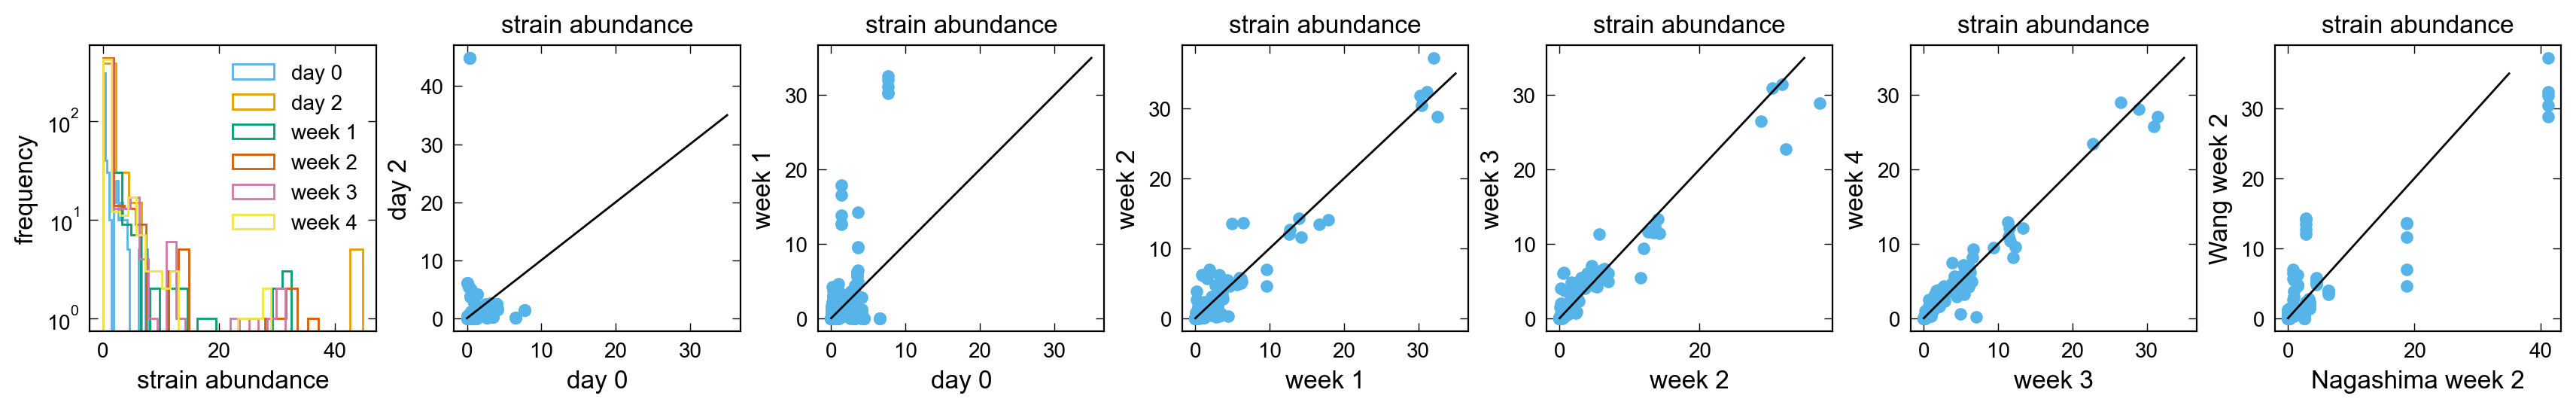

In [7]:
# Plot figures
fig, axs = plt.subplots(1, 7, figsize=(17.0, 3.0), sharex = False, constrained_layout=True)

labels = [['strain abundance', 'frequency'], 
          ['day 0', 'day 2'], ['day 0', 'week 1'], ['week 1', 'week 2'], ['week 2', 'week 3'], ['week 3', 'week 4'], ['Nagashima week 2', 'Wang week 2']]
var_list = [["day0_abundance_batch1", "day2_abundance"],
            ["day0_abundance_batch1", "Batch1_week1"],
            ["Batch1_week1", "Batch1_week2"],
            ["Batch1_week2", "Batch1_week3"],
            ["Batch1_week3", "Batch1_week4"],
           ["day14_abundance", "Batch1_week2"]]

axs[0].hist(full_data.day0_abundance_batch1, bins = 20, log = True, histtype = 'step', label = 'day 0');
axs[0].hist(full_data.day2_abundance, bins = 20, log = True, histtype = 'step', label = 'day 2');
axs[0].hist(full_data.Batch1_week1, bins = 20, log = True, histtype = 'step', label = 'week 1');
axs[0].hist(full_data.Batch1_week2, bins = 20, log = True, histtype = 'step', label = 'week 2');
axs[0].hist(full_data.Batch1_week3, bins = 20, log = True, histtype = 'step', label = 'week 3');
axs[0].hist(full_data.Batch1_week4, bins = 20, log = True, histtype = 'step', label = 'week 4');

for i, u in enumerate(var_list):
    axs[i + 1].scatter(full_data[u[0]], full_data[u[1]], marker = 'o')
    # mask = ~np.isnan(full_data[u[0]]) & ~np.isnan(full_data[u[1]])
    # m, b, r_value, p_value, std_err = scipy.stats.linregress(full_data[u[0]][mask], full_data[u[1]][mask])
    # axs[i + 1].plot(np.unique(full_data[u[0]][mask]), m*np.unique(full_data[u[0]][mask]) + b, 
    #                 color = 'orange', label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)) + r', $m$: ' + str("{:.2f}".format(m)) + ',\n'+r'$p$: ' + str("{:.3f}".format(p_value)))
    axs[i + 1].plot(np.linspace(0,35,10), np.linspace(0,35,10), color = 'black')

for j, ax in enumerate(axs.flat):
    ax.legend()
    if j >= 1:
        # ax.plot([0, 40], [0,40])
        # ax.semilogy()
        # ax.semilogx()
        ax.set_title('strain abundance', fontsize = 12) 
        
    ax.set_xlabel(labels[j][0], fontsize = 12)
    ax.set_ylabel(labels[j][1], fontsize = 12)
        
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/wk_change_in_abundance_strain'+'.pdf', dpi=300, bbox_inches='tight')

Day 2 data from Cheng et al (2022) is weird. There's a big change in the abundance of Lactococcus lactis subsp. lactis Il1403 from day 0 to day 2 in the data. The inoculum (day 0) does not reflect anything about the ecology of the consortium as it is made by pooling samples of each microbe grown separately in an ideal medium.

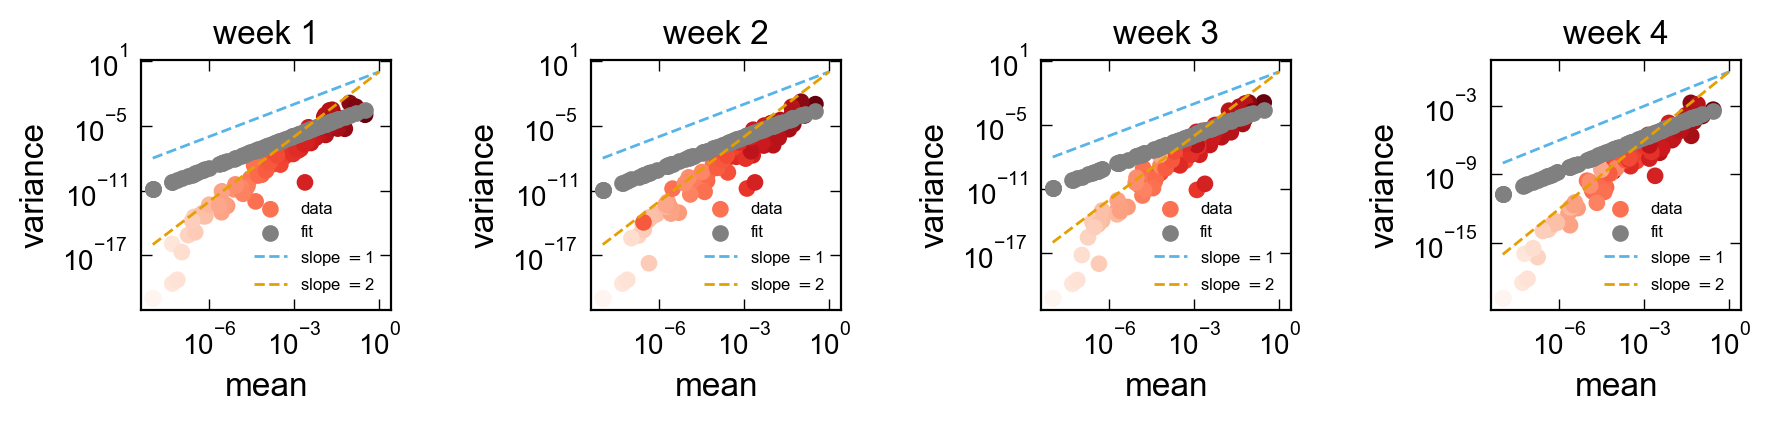

In [68]:
# Using mean data from Wang et al (2023)
import matplotlib.ticker as ticker
fig, ax = plt.subplots(1, 4, figsize=(9.0, 2.0), sharex = False, constrained_layout=True)

var_list = ['Batch1_week1', 'Batch1_week2', 'Batch1_week3', 'Batch1_week4']
var_labels = ['week 1', 'week 2', 'week 3', 'week 4']
data = full_data
data.loc[:,[var+"_clr" for var in var_list]] = np.vstack([clr_transform(data[var]) for var in var_list]).T
mean_data = data[['Name'] + var_list + [var+"_clr" for var in var_list]].groupby(['Name'], as_index = False).mean()
std_data = data[['Name'] + var_list + [var+"_clr" for var in var_list]].groupby(['Name'], as_index = False).std()

# alpha = dirichlet.fit(data)

for i, var in enumerate(var_list): # [v+"_clr" for v in var_list]
    
    # plot relationship between observed data
    y_data = (std_data[var]/100)**2
    x_data = (mean_data[var]/100) #*(1-mean_data[var]/100)
    ax[i].scatter(x_data, y_data, c = mean_data['Batch1_week1']/100, cmap = 'Reds', norm = mpl.colors.LogNorm(), label = 'data')

    # fit to a dirichlet model and plot expected relationship
    for_fit = np.vstack([g[var].values for (_,g) in data.groupby('replicate', as_index = False)])/100
    alphas = dirichlet.mle(for_fit)
    fit_x_data = alphas/np.sum(alphas)
    fit_y_data = x_data*(1 - x_data)/(1 + np.sum(alphas))
    ax[i].scatter(x_data, fit_y_data, color = 'grey', label = 'fit')
    
    for m in [1,2]:
        ax[i].plot(np.logspace(-8,0,10), np.logspace(-8,0,10)**m, ls = '--', label = r'slope $= $'+str(m))

    ax[i].legend(fontsize=6)
    ax[i].set_ylabel('variance', fontsize = 12)
    ax[i].set_xlabel(r'mean', fontsize = 12)
    ax[i].set_title(var_labels[i], fontsize = 12)
    ax[i].set_box_aspect(1)
    ax[i].semilogx(1)
    ax[i].xaxis.set_major_locator(ticker.LogLocator(base=10.0, numticks=3))
    ax[i].semilogy(1)
    ax[i].minorticks_off()
    ax[i].tick_params(axis='both', which='major', labelsize=10)
    ax[i].xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_variation_in_rel_abundance_replicates'+'.pdf', dpi=300, bbox_inches='tight')

A Dirichlet model is probably the most appropriate noise model

##### Microbial abundance trajectories over time: week 0 to week 4
This data is for a microbial consortium that is very similar to hCom1d. The differences are all(?) very low abundance strains.

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33658/2362265084.py:35: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig('_figs/fig_rel_abundance_dynamics_by_strain'+'.pdf', dpi=300, bbox_inches='tight')
/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/IPython/core/events.py:82: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


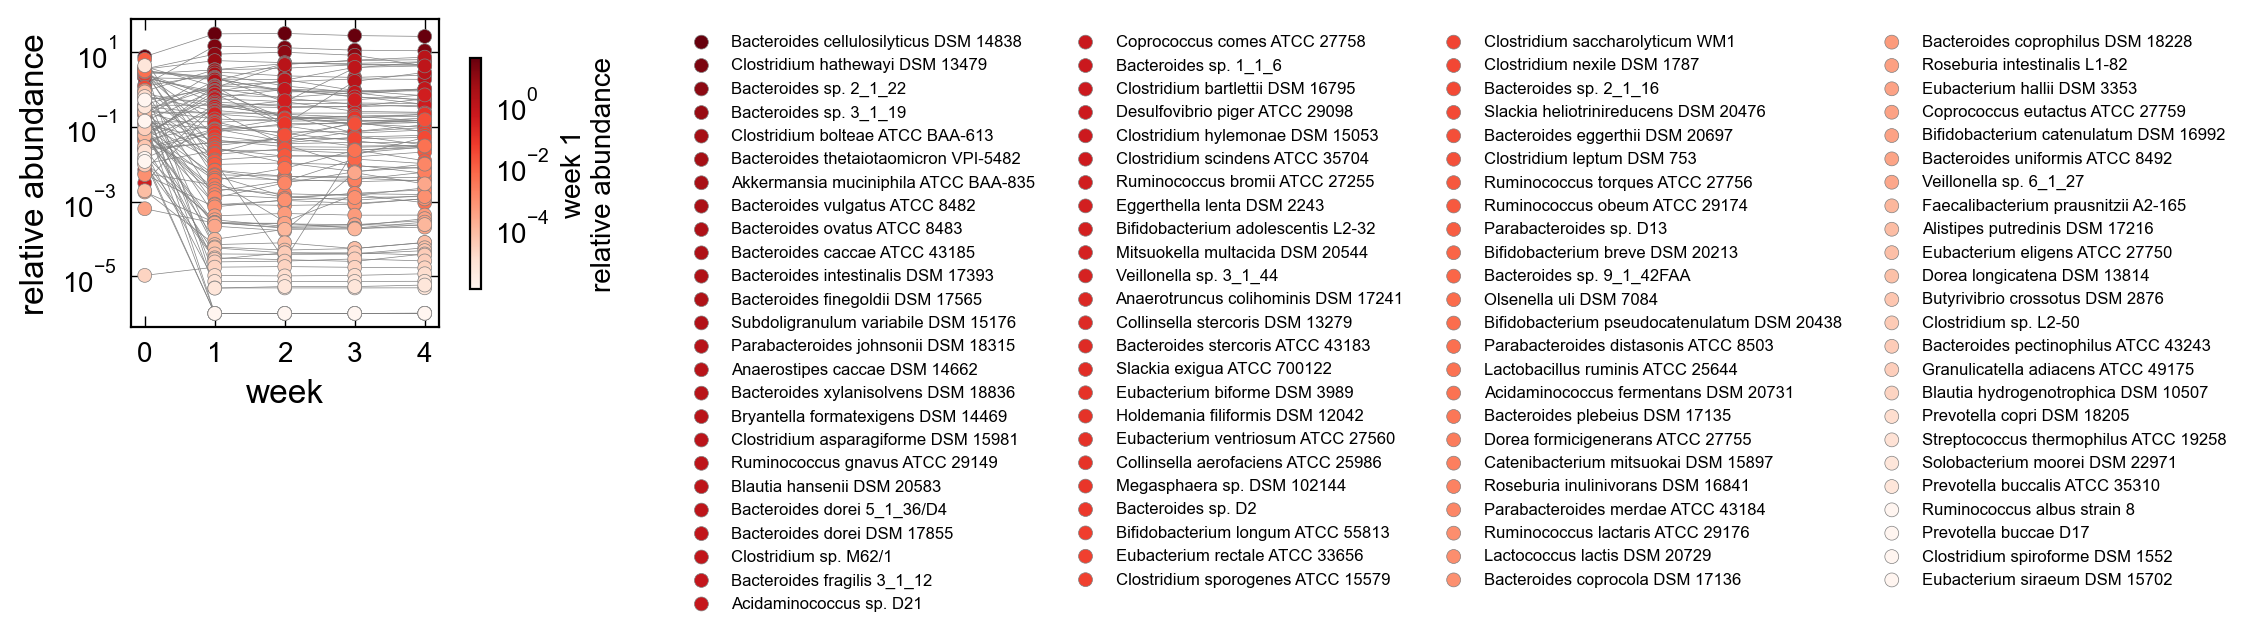

In [9]:
# Using mean data from Wang et al (2023)
fig, ax = plt.subplots(1, 1, figsize=(4.0, 2.0), sharex = False, constrained_layout=True)

var_list = ['day0_abundance_batch1', 'Batch1_week1', 'Batch1_week2', 'Batch1_week3', 'Batch1_week4']
vmin, vmax = np.amin(full_data.Batch1_week1), np.amax(full_data.Batch1_week1)
data = full_data[['Name'] + var_list].groupby('Name', as_index = False).mean()
strain_list = data.sort_values(by='Batch1_week1', ascending= False).Name

for strain in strain_list:
    y_data = np.array(data.loc[data.Name == strain, var_list].values.ravel().tolist())
    mask = y_data > 0
    x_data = np.array([0, 1, 2, 3, 4])
    z_data = data.loc[data.Name == strain, var_list[1]].values.item()*np.ones(len(x_data))
    if np.amin(mask) > 0:
        ax.plot(x_data[mask], y_data[mask],  color = 'grey', linewidth = 0.25, zorder = 0)
        im = ax.scatter(x_data[mask], y_data[mask],  
                        marker = 'o', edgecolor = 'grey', linewidth = 0.25, 
                        c = z_data[mask], cmap = 'Reds', norm = mpl.colors.LogNorm(vmax = vmax, vmin = vmin), label = strain, zorder = 1)

    
ax.legend(bbox_to_anchor=(1.75, 1.0), fontsize=6, framealpha=0, ncol = 4)
cb = fig.colorbar(im, ax=ax, location='right', shrink = 0.75, pad = 0.05)
cb.set_label('week 1\nrelative abundance', fontsize = 10)
cb.ax.tick_params(labelsize=10)

ax.set_xlabel('week', fontsize = 12)
ax.set_ylabel('relative abundance', fontsize = 12)
ax.semilogy()
ax.set_box_aspect(1)
ax.minorticks_off()
ax.tick_params(axis='both', which='major', labelsize=10)
ax.xaxis.set_tick_params(labeltop=False)
ax.set_xticks(x_data)

fig.savefig('_figs/fig_rel_abundance_dynamics_by_strain'+'.pdf', dpi=300, bbox_inches='tight')

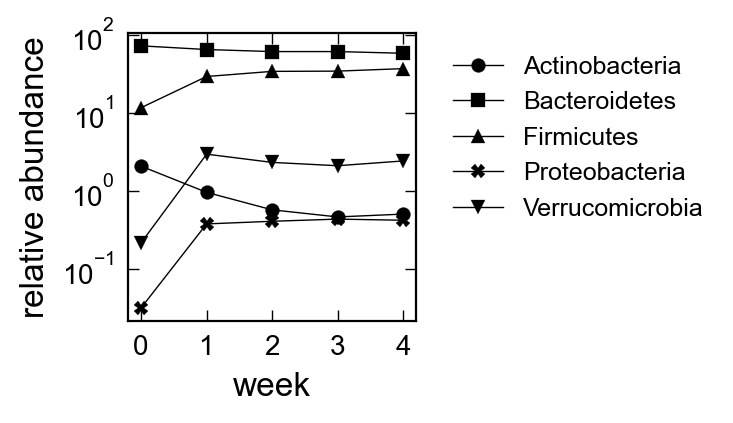

In [10]:
# Using mean data from Wang et al (2023)
fig, ax = plt.subplots(1, 1, figsize=(4.0, 2.0), sharex = False, constrained_layout=True)

var_list = ['day0_abundance_batch1', 'Batch1_week1', 'Batch1_week2', 'Batch1_week3', 'Batch1_week4']
data = full_data[['Name', 'Phyla'] + var_list].groupby(['Name', 'Phyla'], as_index = False).mean().groupby('Phyla', as_index = False).sum()
phyla_list = np.unique(data.sort_values(by='Batch1_week1', ascending= False).Phyla)
markers = ['o','s', '^', 'X', 'v']

for i, phyla in enumerate(phyla_list):

    y_data = data.loc[data.Phyla == phyla, var_list].values.ravel().tolist()
    x_data = [0, 1, 2, 3, 4]
    ax.plot(x_data, y_data, marker = markers[i], linewidth = 0.5, label = phyla, color = 'black')
    
ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)

ax.set_xlabel('week', fontsize = 12)
ax.set_ylabel('relative abundance', fontsize = 12)
ax.semilogy()
ax.set_box_aspect(1)
ax.minorticks_off()
ax.tick_params(axis='both', which='major', labelsize=10)
ax.xaxis.set_tick_params(labeltop=False)
ax.set_xticks(x_data)

fig.savefig('_figs/fig_rel_abundance_dynamics_by_phyla'+'.pdf', dpi=300, bbox_inches='tight')

Fecal matter data from Wang et al. (2023) has more data points and more reliable trends. We'll use this going forward.

#### Reactivity of individual T-cell receptors to individual hCom1d microbes
This data comes from Figure 3 in Nagashima et al. (2023). Data is only available for a subset of the microbes.

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33658/4083632317.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0, ncol = 2)


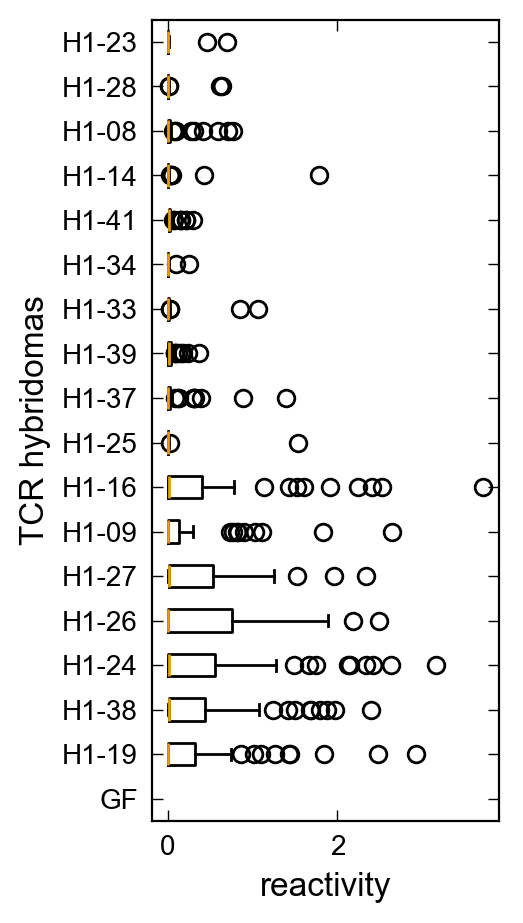

In [11]:
# Plot figures
fig, ax = plt.subplots(1, 1, figsize=(2.5, 4.5), sharex = False, constrained_layout=True)

labels = [['strain abundance', 'frequency'], 
          ['day 0', 'day 2'], ['day 0', 'day 14'], ['day 0', 'day 28'], ['day 14', 'day 28']]
var_list = ['GF',
            'H1-19','H1-38','H1-24','H1-26','H1-27','H1-09','H1-16',
            'H1-25',
            'H1-37','H1-39','H1-33','H1-34',
            'H1-41','H1-14','H1-08',
            'H1-28',
            'H1-23']

ax.boxplot(cross_reactivity_data[var_list], tick_labels= var_list, orientation = 'horizontal')

    
ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0, ncol = 2)

ax.set_xlabel('reactivity', fontsize = 12)
ax.set_ylabel('TCR hybridomas', fontsize = 12)
    
ax.minorticks_off()
ax.tick_params(axis='both', which='major', labelsize=10)
ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_tcr_hybridoma_reactivities'+'.pdf', dpi=300, bbox_inches='tight')

#### Immune coverage of hCom1d by T-cell repertoire
This data comes from Figure 2 in Nagashima et al. (2023).

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33658/1151075201.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[i].legend(fontsize=9, loc = 'upper right', framealpha=0)
/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33658/1151075201.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[i].legend(fontsize=9, loc = 'upper right', framealpha=0)
/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33658/1151075201.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[i].legend(fontsize=9, loc = 'upper right', framealpha=0)


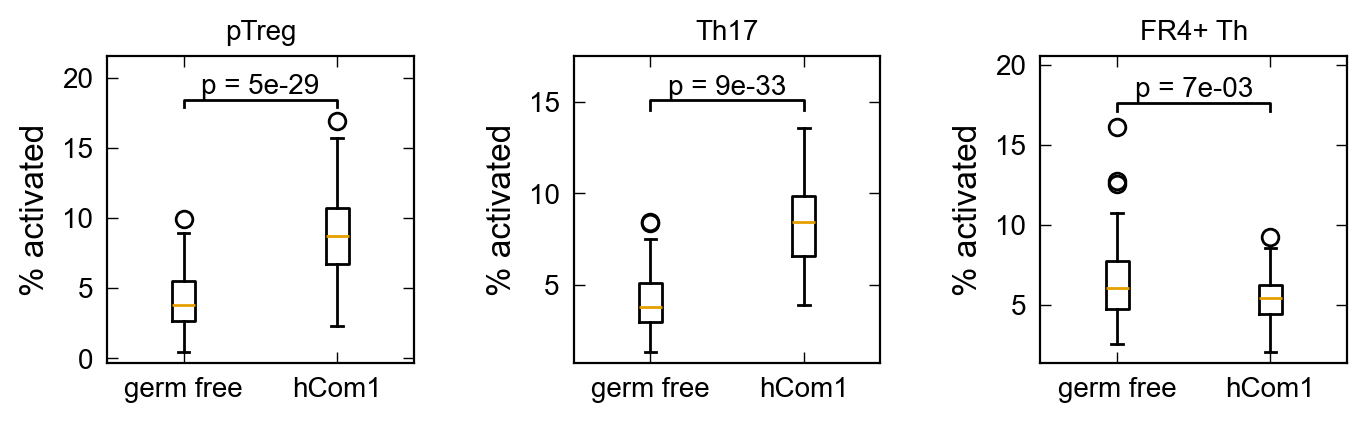

In [12]:
# Plot figures
fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']
var_list = [['GF_pTreg_Average', 'hCom1d_pTreg_Average'], 
                      ['GF_Th17_Average', 'hCom1d_Th17_Average'], 
                      ['GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']]

data = full_data[['Name'] + coverage_variables].groupby('Name', as_index = False).mean()

for i, var in enumerate(var_list):
    GF_pop, hcom1_pop = data[var[0]], data[var[1]]
    # axs[i].hist(GF_pop, bins = 20, label = 'germ free');
    # axs[i].hist(hcom1_pop, bins = 20, label = 'hCom1d');
    axs[i].boxplot([GF_pop, hcom1_pop], tick_labels= ['germ free', 'hCom1'])

    axs[i].legend(fontsize=9, loc = 'upper right', framealpha=0)
    
    axs[i].set_title(['pTreg', 'Th17', 'FR4+ Th'][i], fontsize = 10) 
    axs[i].set_ylabel('% activated', fontsize = 12)
        
    axs[i].set_box_aspect(1)
    axs[i].minorticks_off()
    axs[i].tick_params(axis='both', which='major', labelsize=10)
    axs[i].xaxis.set_tick_params(labeltop=False)

    # Run two-sided Mann-Whitney test with null that the two distribitions are identical
    from scipy.stats import mannwhitneyu
    U1, p = mannwhitneyu(GF_pop, hcom1_pop, method="exact")

    x1, x2 = 1, 2   # columns 'Sat' and 'Sun' (first column: 0, see plt.xticks())
    y, h, col = np.amax(np.array([GF_pop, hcom1_pop])) + 1, 0.5, 'k'
    axs[i].set_ylim(top = y*(1.2))
    axs[i].plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.0, c=col)
    axs[i].text((x1+x2)*.5, y+h, f'p = {p:.0e}', ha='center', va='bottom', color=col)

fig.savefig('_figs/fig_immune_activation_GF_hcom1'+'.pdf', dpi=300, bbox_inches='tight')

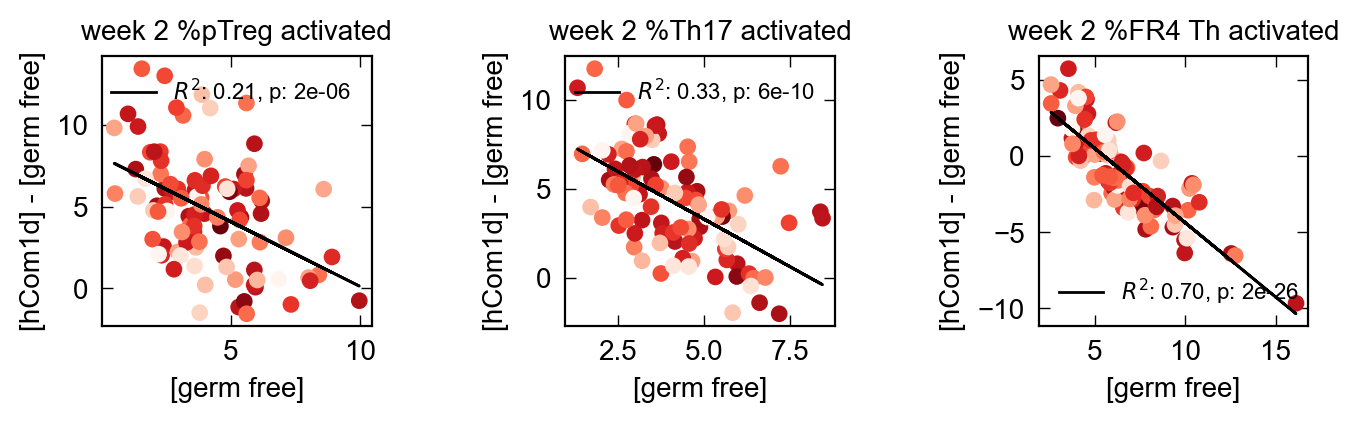

In [13]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

data = full_data[['Name', 'Batch1_week1'] + coverage_variables].groupby('Name', as_index = False).mean()

for i, ax in enumerate(axs):

    ax.scatter(data[coverage_variables[2*i]], 
               data[coverage_variables[2*i + 1]] - data[coverage_variables[2*i]],
                c = data['Batch1_week1'],
               cmap = 'Reds', norm = mpl.colors.LogNorm())
    #ax.plot([0, 15], [0,15])

    m, b, r_value, p_value, std_err = scipy.stats.linregress(data[coverage_variables[2*i]], data[coverage_variables[2*i + 1]] - data[coverage_variables[2*i]])
    ax.plot(data[coverage_variables[2*i]], 
            m*data[coverage_variables[2*i]] + b,
            color = 'black',
           label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)) + f', p: {p_value:.0e}')
    
for j, ax in enumerate(axs.flat):
    ax.legend(fontsize=8)
    # ax.semilogx()
    # ax.semilogy()
    ax.set_xlabel('[germ free]', fontsize = 10)
    ax.set_ylabel('[hCom1d] - [germ free]', fontsize = 10)
    ax.set_title('week 2 '+['%pTreg activated', '%Th17 activated', '%FR4 Th activated'][j], fontsize = 10)   
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_change_in_response_to_hcom1'+'.pdf', dpi=300, bbox_inches='tight')

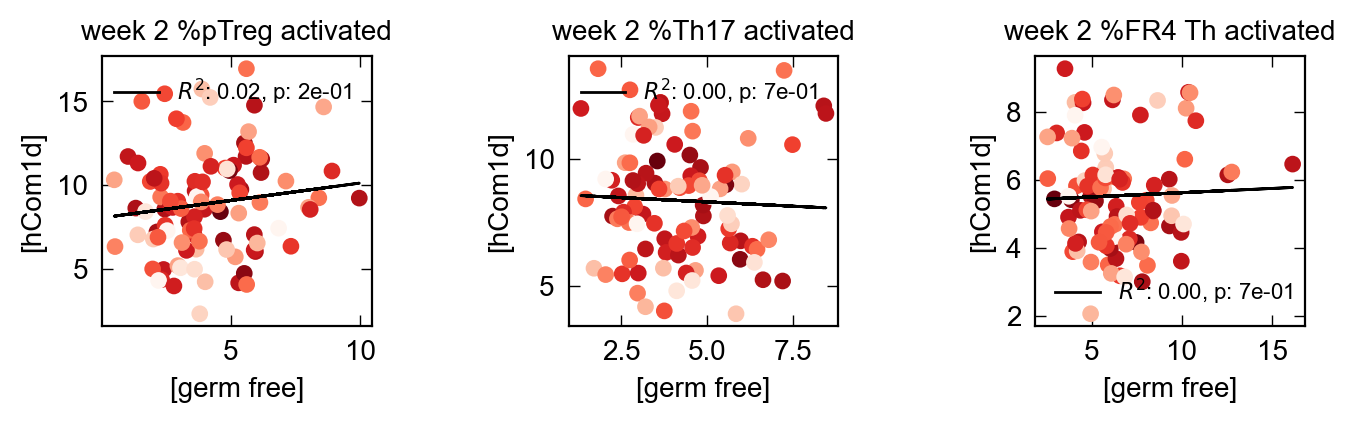

In [14]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

data = full_data[['Name', 'Batch1_week1'] + coverage_variables].groupby('Name', as_index = False).mean()

for i, ax in enumerate(axs):

    ax.scatter(data[coverage_variables[2*i]], 
               data[coverage_variables[2*i + 1]],
                c = data['Batch1_week1'],
               cmap = 'Reds', norm = mpl.colors.LogNorm())
    #ax.plot([0, 15], [0,15])

    m, b, r_value, p_value, std_err = scipy.stats.linregress(data[coverage_variables[2*i]], data[coverage_variables[2*i + 1]])
    ax.plot(data[coverage_variables[2*i]], 
            m*data[coverage_variables[2*i]] + b,
            color = 'black',
           label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)) + f', p: {p_value:.0e}')
    
for j, ax in enumerate(axs.flat):
    ax.legend(fontsize=8)
    # ax.semilogx()
    # ax.semilogy()
    ax.set_xlabel('[germ free]', fontsize = 10)
    ax.set_ylabel('[hCom1d]', fontsize = 10)
    ax.set_title('week 2 '+['%pTreg activated', '%Th17 activated', '%FR4 Th activated'][j], fontsize = 10)   
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# fig.savefig('_figs/fig_change_in_response_to_hcom1'+'.pdf', dpi=300, bbox_inches='tight')

From the last two figures, we see that while the distribution of coverage by FR4+ T-cells changes the least, the coverage of individual microbes changes a lot, and the signal is quite strong. What are these T-cells doing? Exclude them from further analysis.

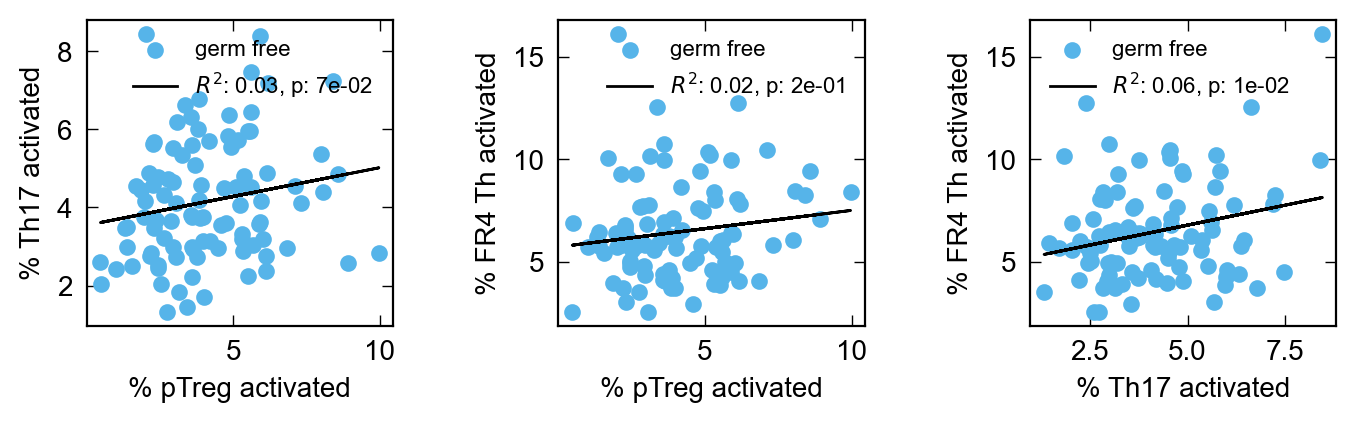

In [15]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']
labels = [['% pTreg activated', '% Th17 activated'], ['% pTreg activated', '% FR4 Th activated'], ['% Th17 activated', '% FR4 Th activated']]
var_list = [[coverage_variables[0], coverage_variables[2]],
            [coverage_variables[0], coverage_variables[4]],
            [coverage_variables[2], coverage_variables[4]]]

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

data = full_data[['Name', 'Batch1_week1'] + coverage_variables].groupby('Name', as_index = False).mean()

axs[0].scatter(data[coverage_variables[0]], data[coverage_variables[2]], marker = 'o', label = 'germ free')
axs[1].scatter(data[coverage_variables[0]], data[coverage_variables[4]], marker = 'o', label = 'germ free')
axs[2].scatter(data[coverage_variables[2]], data[coverage_variables[4]], marker = 'o', label = 'germ free')

for i, u in enumerate(var_list):
    m, b, r_value, p_value, std_err = scipy.stats.linregress(data[u[0]], data[u[1]])
    axs[i].plot(data[u[0]], m*data[u[0]] + b, color = 'black', 
                label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ f', p: {p_value:.0e}')

for j, ax in enumerate(axs.flat):
    ax.legend(fontsize=8)
    ax.set_xlabel(labels[j][0], fontsize = 10)
    ax.set_ylabel(labels[j][1], fontsize = 10)   
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

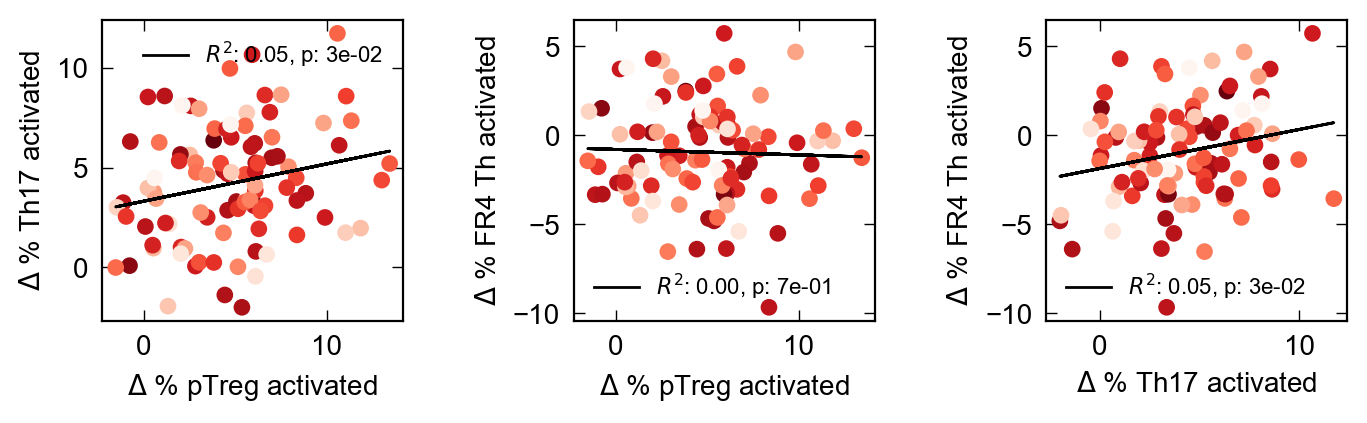

In [16]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']
labels = [['% pTreg activated', '% Th17 activated'], ['% pTreg activated', '% FR4 Th activated'], ['% Th17 activated', '% FR4 Th activated']]
var_list = [[1, 3],
            [1, 5],
            [3, 5]]

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

data = full_data[['Name', 'Batch1_week1'] + coverage_variables].groupby('Name', as_index = False).mean()

for i, u in enumerate(var_list):
    x_data = data[coverage_variables[u[0]]] - data[coverage_variables[u[0] - 1]]
    y_data = data[coverage_variables[u[1]]] - data[coverage_variables[u[1] - 1]]
    axs[i].scatter(x_data, y_data, marker = 'o', c = data['Batch1_week1'],
               cmap = 'Reds', norm = mpl.colors.LogNorm())
    m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data, y_data)
    axs[i].plot(x_data, m*x_data + b, color = 'black', 
                label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ f', p: {p_value:.0e}')

for j, ax in enumerate(axs.flat):
    ax.legend(fontsize=8)
    ax.set_xlabel(r'$\Delta$ ' + labels[j][0], fontsize = 10)
    ax.set_ylabel(r'$\Delta$ ' + labels[j][1], fontsize = 10)
    # ax.set_title(, fontsize = 12)   
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_relationship_immune_cells_hcom1'+'.pdf', dpi=300, bbox_inches='tight')

What if we do these regressions only on the most abundant microbes? Or stratified by abundance level

#### Is there a relationship between microbe abundance and immune coverage?

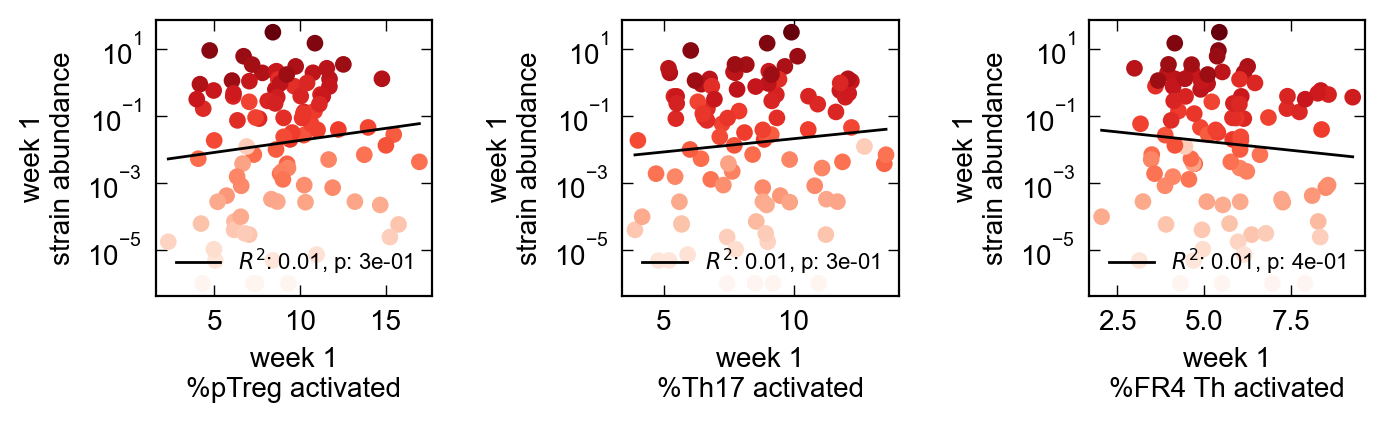

In [17]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

var_list = [coverage_variables[1], coverage_variables[3], coverage_variables[5]]

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

data = full_data[['Name', 'Batch1_week1', 'Batch1_week2'] + coverage_variables].groupby('Name', as_index = False).mean()

for i, ax in enumerate(axs):
    x_data = data[coverage_variables[2*i + 1]]
    y_data = data['Batch1_week1']
    ax.scatter(x_data, 
               y_data, 
               c = data['Batch1_week2'],
               cmap = 'Reds',
               marker = 'o', norm = mpl.colors.LogNorm()) #, label = 'hCom1d')
    mask = ~np.isnan(x_data) & ~np.isnan(y_data) & ~np.isinf(np.log10(y_data))
    m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data[mask], np.log10(y_data[mask]))
    # ax.scatter(x_data[mask], m*x_data[mask] + b)
    ax.plot(np.unique(x_data[mask]), 10**(m*np.unique(x_data[mask]) + b), color = 'black', 
            label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ f', p: {p_value:.0e}')

for j, ax in enumerate(axs.flat):
    ax.legend(fontsize = 8)
    ax.semilogy()
    ax.set_ylabel('week 1\nstrain abundance', fontsize = 10)
    ax.set_xlabel('week 1\n'+['%pTreg activated', '%Th17 activated', '%FR4 Th activated'][j], fontsize = 10)
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_wk1_abundance_v_coverage_hcom1'+'.pdf', dpi=300, bbox_inches='tight')

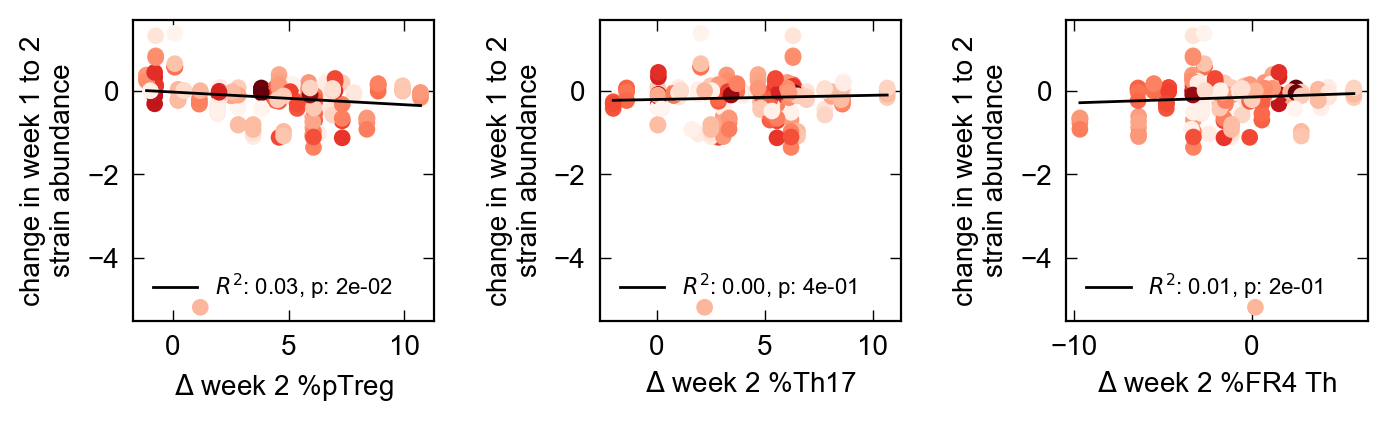

In [18]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

data = full_data[['Name', 'Batch1_week1', 'Batch1_week2', 'Batch1_week4'] + coverage_variables] #.groupby('Name', as_index = False).mean()

for i, ax in enumerate(axs):
    mask = data['Batch1_week1'] > 1e-1
    x_data = data[coverage_variables[2*i + 1]] - data[coverage_variables[2*i]]
    y_data = np.log10(data['Batch1_week2']/data['Batch1_week1'])
    ax.scatter(x_data[mask], 
               y_data[mask], 
               c = data['Batch1_week1'][mask],
               norm = mpl.colors.LogNorm(),
               cmap = 'Reds',
               marker = 'o')

    # mask = ~np.isnan(x_data) & ~np.isnan(y_data) & ~np.isinf(np.log10(y_data))

    m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data[mask], y_data[mask])
    ax.plot(np.unique(x_data[mask]), m*np.unique(x_data[mask]) + b, color = 'black',
            label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ f', p: {p_value:.0e}')

for j, ax in enumerate(axs.flat):
    ax.legend(fontsize = 8)
    # ax.semilogy()
    # ax.semilogx()
    ax.set_ylabel('change in week 1 to 2\nstrain abundance', fontsize = 10)
    ax.set_xlabel(r'$\Delta$ week 2 '+['%pTreg', '%Th17', '%FR4 Th'][j], fontsize = 10)
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_change_in_wk2_abundance_v_coverage_hcom1'+'.pdf', dpi=300, bbox_inches='tight')

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33658/392860159.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.loc[:, "Th17_pTreg"] = ((data[coverage_variables[3]])/(data[coverage_variables[1]])).values
/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33658/392860159.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.loc[:, "FR4_Th_pTreg"] = ((data[coverage_variables[5]])/(data[coverage_variables[1]])).values
/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33

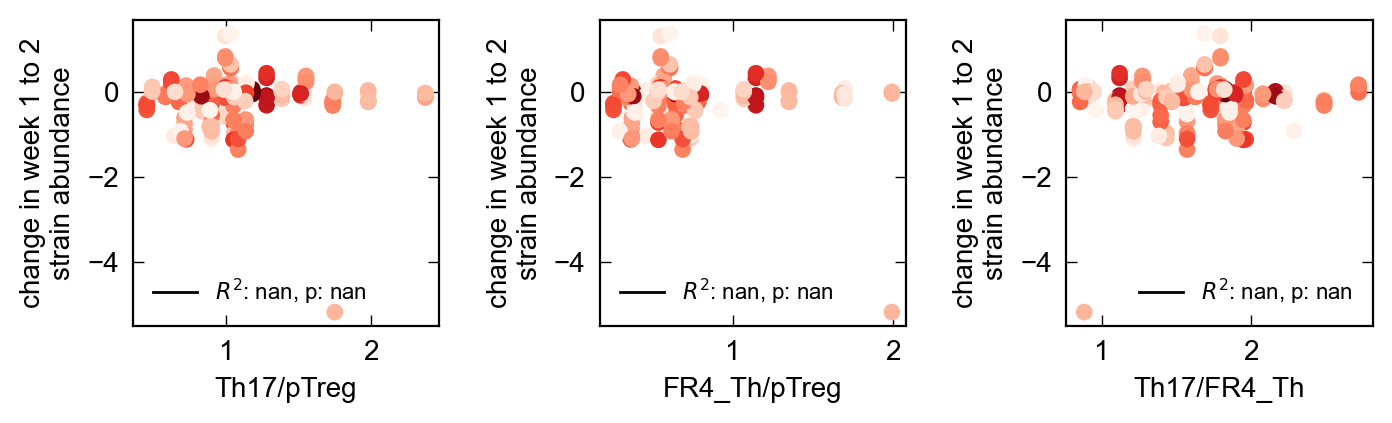

In [19]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

data = full_data[['Name', 'Batch1_week1', 'Batch1_week2', 'Batch1_week4'] + coverage_variables]
data.loc[:, "Th17_pTreg"] = ((data[coverage_variables[3]])/(data[coverage_variables[1]])).values
data.loc[:, "FR4_Th_pTreg"] = ((data[coverage_variables[5]])/(data[coverage_variables[1]])).values
data.loc[:, "Th17_FR4_Th"] = ((data[coverage_variables[3]])/(data[coverage_variables[5]])).values
var_list = ["Th17_pTreg", "FR4_Th_pTreg", "Th17_FR4_Th"]

for i, ax in enumerate(axs):
    x_data = data[var_list[i]]
    y_data = np.log10(data['Batch1_week2']/data['Batch1_week1'])
    mask = (data['Batch1_week1'] > 1e-1) & ~np.isinf(x_data) & ~np.isinf(y_data) & ~np.isnan(x_data) & ~np.isnan(y_data)
    ax.scatter(x_data[mask], 
               y_data[mask], 
               c = data['Batch1_week1'][mask],
               norm = mpl.colors.LogNorm(),
               cmap = 'Reds',
               marker = 'o')

    # mask = ~np.isnan(x_data) & ~np.isnan(y_data) & ~np.isinf(np.log10(y_data))
    m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data[mask], np.log10(y_data[mask]))
    # regression
    ax.plot(np.unique(x_data[mask]), m*np.unique(x_data[mask]) + b, color = 'black',
            label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ f', p: {p_value:.0e}')

for j, ax in enumerate(axs.flat):
    ax.legend(fontsize = 8)
    # ax.semilogx()
    ax.set_ylabel('change in week 1 to 2\nstrain abundance', fontsize = 10)
    ax.set_xlabel(["Th17/pTreg", "FR4_Th/pTreg", "Th17/FR4_Th"][j], fontsize = 10)
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# fig.savefig('_figs/fig_change_in_wk2_abundance_v_coverage_hcom1'+'.pdf', dpi=300, bbox_inches='tight')

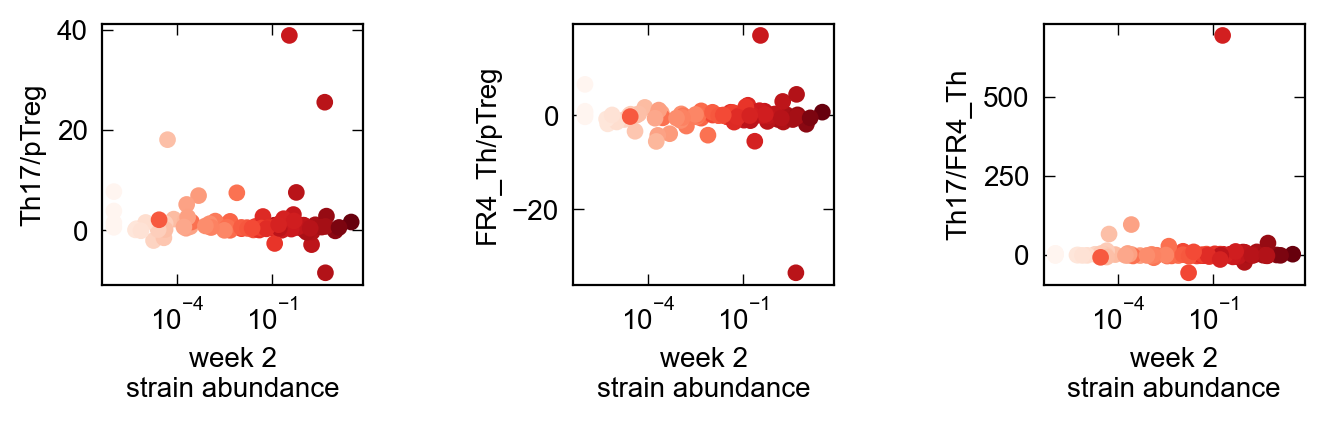

In [20]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

data = full_data[['Name', 'Batch1_week1', 'Batch1_week2', 'Batch1_week3'] + coverage_variables].groupby('Name', as_index = False).mean()
data.loc[:, "Th17_pTreg"] = ((data[coverage_variables[3]] - data[coverage_variables[2]])/(data[coverage_variables[1]] - data[coverage_variables[0]])).values
data.loc[:, "FR4_Th_pTreg"] = ((data[coverage_variables[5]] - data[coverage_variables[4]])/(data[coverage_variables[1]] - data[coverage_variables[0]])).values
data.loc[:, "Th17_FR4_Th"] = ((data[coverage_variables[3]] - data[coverage_variables[2]])/(data[coverage_variables[5]] - data[coverage_variables[4]])).values
var_list = ["Th17_pTreg", "FR4_Th_pTreg", "Th17_FR4_Th"]

for i, ax in enumerate(axs):
    x_data = data['Batch1_week2']
    y_data = data[var_list[i]]
    ax.scatter(x_data, 
               y_data, 
               c = data['Batch1_week1'],
               norm = mpl.colors.LogNorm(),
               cmap = 'Reds',
               marker = 'o')

    # mask = ~np.isnan(x_data) & ~np.isnan(y_data) & ~np.isinf(np.log10(y_data))
    # m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data[mask], np.log10(y_data[mask]))
    # # regression
    # ax.plot(np.unique(x_data[mask]), 10**(m*np.unique(x_data[mask]) + b), color = 'black',
    #         label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ r', $p$: ' + str("{:.3f}".format(p_value)))

for j, ax in enumerate(axs.flat):
    ax.semilogx()
    ax.set_xlabel('week 2\nstrain abundance', fontsize = 10)
    ax.set_ylabel(["Th17/pTreg", "FR4_Th/pTreg", "Th17/FR4_Th"][j], fontsize = 10)
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# fig.savefig('_figs/fig_change_in_wk2_abundance_v_coverage_hcom1'+'.pdf', dpi=300, bbox_inches='tight')

In [21]:
# Compare compositional variance of individual microbes and microbes targeted by the same receptors.
# Hypothesis is that collective abundance of targeted microbes should vary much less than individual abundance
# Contrast this with grouping by Phylum (or other genetic data) and random shuffling
# How can I measure this? Do I have the data?

#### Ecology of the microbial community
Using amino acid dropouts (Cheng et al. (2022)) and strain drop outs (Wang et al. (2023).

[0.77011303 0.15022279 0.07966418]


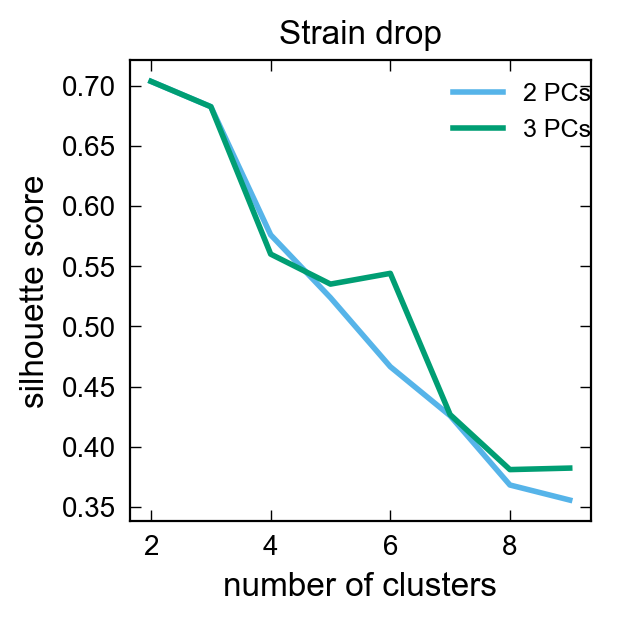

In [22]:
# Cluster based on strain drop outs
fig, axs = plt.subplots(1,1, figsize=(4, 3.0), sharex='row', sharey=False,layout='constrained')

# Scale and center data for clustering
cluster_vars = ['drop_Ch_abundance','drop_Cs_abundance','drop_ChCs_abundance']
input_data = strain_dropout_abundance_data[cluster_vars + ['week3_cecum_abundance']].replace([0.0], 1e-6).sort_values(by='week3_cecum_abundance', ascending= False).apply(clr_transform, axis=0).fillna(0)

cluster_input = input_data[cluster_vars].sub(input_data['week3_cecum_abundance'], axis=0)
mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars)
scaler = StandardScaler()
scaler.fit(cluster_input[cluster_vars].values[mask])
# do PCA
pca = PCA(n_components=len(cluster_vars))
pca.fit(np.abs(scaler.transform(cluster_input[cluster_vars].values[mask])))
print(pca.explained_variance_ratio_)

# dataset for clustering

for l in np.arange(2, np.minimum(len(cluster_vars), 7) + 1):
    for_clustering = PCA(n_components=l).fit_transform(np.abs(scaler.transform(cluster_input[cluster_vars].values[mask])))
    cluster_iter = np.arange(2,10)
    score = []
    # compute scores
    for k in cluster_iter:
        clustering_object = KMeans(n_clusters=k, n_init = 10, random_state=0)
        score += [silhouette_score(cluster_input[cluster_vars].values[mask], clustering_object.fit_predict(for_clustering))]
        
    axs.plot(cluster_iter, score, color = ito_colors[l], label = str(l)+' PCs', linewidth = 2.0)

axs.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
axs.set_title("Strain drop", fontsize = 12)  
axs.set_xlabel('number of clusters', fontsize = 12)
axs.set_ylabel('silhouette score', fontsize = 12)
axs.set_box_aspect(1)
axs.minorticks_off()
axs.tick_params(axis='both', which='major', labelsize=10)

#plt.savefig('_figs/figSI_'+comment+'-cluster_silhouette_scores'+'.pdf', format="pdf", transparent=True, dpi=300)

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/scipy/stats/_stats_py.py:239: RuntimeWarning: invalid value encountered in log
  log_a = xp.log(a)


[0.78736177 0.17477847 0.03785975]


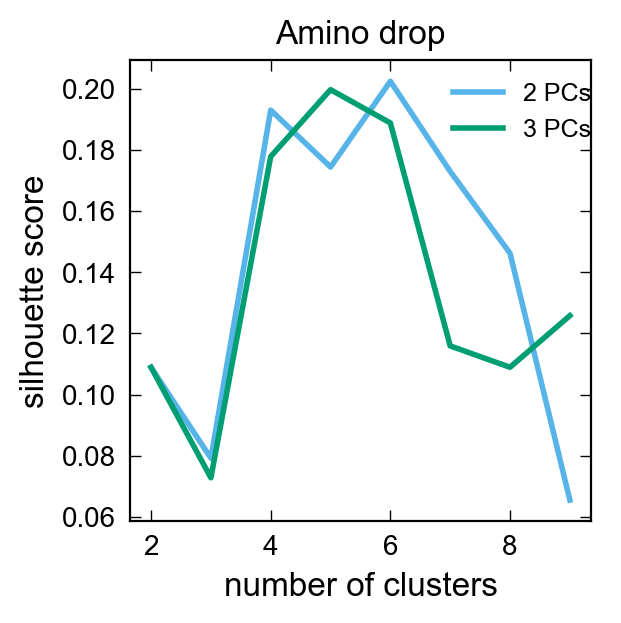

In [23]:
# Cluster based on amino acid drop outs
fig, axs = plt.subplots(1,1, figsize=(4, 3.0), sharex='row', sharey=False,layout='constrained')

# Scale and center data for clustering
cluster_vars = ['Arginine', 'Histidine', 'Tryptophan']

# cluster_vars = ['Methionine', 'Histidine', 'Isoleucine','Arginine',
#                 'Valine', 'Tyrosine', 'Leucine', 'Serine',  'Tryptophan']
# cluster_vars = ['Alanine', 'Arginine', 'Asparagine',
#        'AsparticAcid','GlutamicAcid', 'Glutamine', 'Glycine', # removed cysteine
#        'Histidine', 'Isoleucine', 'Leucine', 'Lysine', 'Methionine',
#        'Phenylalanine', 'Proline', 'Serine', 'Threonine', 'Tryptophan',
#        'Tyrosine', 'Valine']

input_data = 10**(amino_dropout_abundance_data[cluster_vars + ['day2_abundance']].sort_values(by='day2_abundance', ascending= False).fillna(-6)).apply(clr_transform, axis=0).fillna(0)

cluster_input = input_data[cluster_vars].sub(input_data['day2_abundance'], axis=0)
mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars)
scaler = StandardScaler()
scaler.fit(cluster_input[cluster_vars].values[mask])
# do PCA
pca = PCA(n_components=len(cluster_vars))
pca.fit(np.abs(scaler.transform(cluster_input[cluster_vars].values[mask])))
print(pca.explained_variance_ratio_)
# dataset for clustering
for l in np.arange(2, np.minimum(len(cluster_vars), 7) + 1):
    for_clustering = PCA(n_components=l).fit_transform(np.abs(scaler.transform(cluster_input[cluster_vars].values[mask])))
    cluster_iter = np.arange(2,10)
    score = []
    # compute scores
    for k in cluster_iter:
        clustering_object = KMeans(n_clusters=k, n_init = 10, random_state=0)
        score += [silhouette_score(cluster_input[cluster_vars].values[mask], clustering_object.fit_predict(for_clustering))]
        
    axs.plot(cluster_iter, score, color = ito_colors[l], label = str(l)+' PCs', linewidth = 2.0)

axs.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
axs.set_title("Amino drop", fontsize = 12)
axs.set_xlabel('number of clusters', fontsize = 12)
axs.set_ylabel('silhouette score', fontsize = 12)
axs.set_box_aspect(1)
axs.minorticks_off()
axs.tick_params(axis='both', which='major', labelsize=10)

#plt.savefig('_figs/figSI_'+comment+'-cluster_silhouette_scores'+'.pdf', format="pdf", transparent=True, dpi=300)

[7.77028170e-01 1.60848254e-01 5.66016496e-02 5.32792852e-03
 1.49990363e-04 4.40077515e-05]


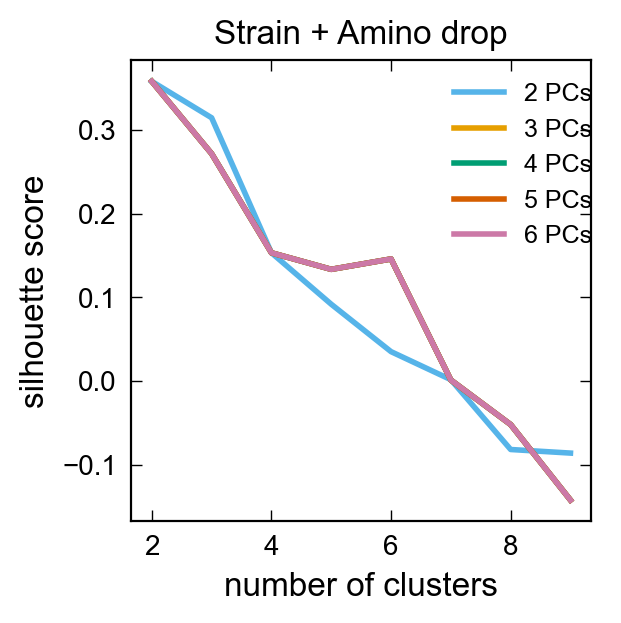

In [24]:
# Cluster based on combined strain and amino acid drop outs
fig, axs = plt.subplots(1,1, figsize=(4, 3.0), sharex='row', sharey=False,layout='constrained')

# Scale and center data for clustering
amino_vars = ['Arginine', 'Histidine', 'Tryptophan']
strain_vars = ['drop_Ch_abundance','drop_Cs_abundance','drop_ChCs_abundance']
cluster_vars = amino_vars + strain_vars

input_data = strain_dropout_abundance_data.loc[strain_dropout_abundance_data.strain_id.notna(), strain_vars + ['strain_id','week3_cecum_abundance']].merge(amino_dropout_abundance_data.loc[amino_dropout_abundance_data.strain_id.notna()], 
                                                                                                      how = 'left', on = 'strain_id', validate = 'one_to_one'
                                       ).sort_values(by='week3_cecum_abundance', ascending= False)
input_data[amino_vars + ['day2_abundance']] = 10**(input_data[amino_vars + ['day2_log10_abundance']].fillna(-6)).apply(clr_transform, axis=0).fillna(0)
input_data[strain_vars + ['week3_cecum_abundance']] = input_data[strain_vars + ['week3_cecum_abundance']].replace([0.0], 1e-6).sort_values(by='week3_cecum_abundance', ascending= False).apply(clr_transform, axis=0).fillna(0)

cluster_input = pd.concat([input_data[amino_vars].sub(input_data['day2_log10_abundance'], axis=0), 
                               input_data[strain_vars].sub(input_data['week3_cecum_abundance'], axis=0)],
                              axis = 1)
mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars)
scaler = RobustScaler()
scaler.fit(cluster_input[cluster_vars].values[mask])
# do PCA
pca = PCA(n_components=len(cluster_vars))
pca.fit(np.abs(scaler.transform(cluster_input[cluster_vars].values[mask])))
print(pca.explained_variance_ratio_)
# dataset for clustering
for l in np.arange(2, np.minimum(len(cluster_vars), 7) + 1):
    for_clustering = PCA(n_components=l).fit_transform(np.abs(scaler.transform(cluster_input[cluster_vars].values[mask])))
    cluster_iter = np.arange(2,10)
    score = []
    # compute scores
    for k in cluster_iter:
        clustering_object = KMeans(n_clusters=k, n_init = 10, random_state=0)
        score += [silhouette_score(cluster_input[cluster_vars].values[mask], clustering_object.fit_predict(for_clustering))]
        
    axs.plot(cluster_iter, score, label = str(l)+' PCs', linewidth = 2.0)

axs.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
axs.set_title("Strain + Amino drop", fontsize = 12)
axs.set_xlabel('number of clusters', fontsize = 12)
axs.set_ylabel('silhouette score', fontsize = 12)
axs.set_box_aspect(1)
axs.minorticks_off()
axs.tick_params(axis='both', which='major', labelsize=10)

#plt.savefig('_figs/figSI_'+comment+'-cluster_silhouette_scores'+'.pdf', format="pdf", transparent=True, dpi=300)

[0.26264358 0.16282535 0.15303984 0.11941838 0.07325837 0.06570379
 0.05494583 0.04031403 0.02256987 0.0179885  0.01185524 0.00568393
 0.00379529 0.00227647 0.00196629 0.00116157 0.00055368]


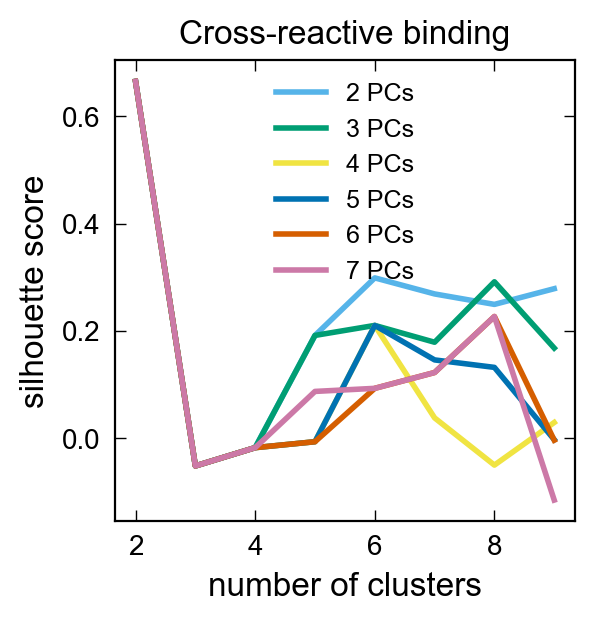

In [25]:
# Cluster based on immune receptor binding
fig, axs = plt.subplots(1,1, figsize=(4, 3.0), sharex='row', sharey=False,layout='constrained')

# Scale and center data for clustering
cluster_vars = ['H1-19','H1-38','H1-24','H1-26','H1-27','H1-09','H1-16',
            'H1-25',
            'H1-37','H1-39','H1-33','H1-34',
            'H1-41','H1-14','H1-08',
            'H1-28',
            'H1-23']

cluster_input = cross_reactivity_data[cluster_vars]
mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars)
# normalizer = Normalizer(norm='l2')
# cluster_input_norm = normalizer.fit_transform(cluster_input[cluster_vars].values[mask])
# # do PCA
# pca = PCA(n_components=len(cluster_vars))
# pca.fit(cluster_input_norm)
#pca.fit(cosine_similarity(cluster_input[cluster_vars].values[mask]))
scaler = StandardScaler()
scaler.fit(cluster_input[cluster_vars].values[mask])
# do PCA
pca = PCA(n_components=len(cluster_vars))
pca.fit(np.abs(scaler.transform(cluster_input[cluster_vars].values[mask])))
print(pca.explained_variance_ratio_)
# dataset for clustering
for l in np.arange(2, np.minimum(len(cluster_vars), 7) + 1):
    for_clustering = PCA(n_components=l).fit_transform(np.abs(scaler.transform(cluster_input[cluster_vars].values[mask])))
    # for_clustering = cluster_input_norm #PCA(n_components=l).fit_transform(cluster_input_norm)
    #for_clustering = PCA(n_components=l).fit_transform(cosine_similarity(cluster_input[cluster_vars].values[mask]))
    cluster_iter = np.arange(2,10)
    score = []
    # compute scores
    for k in cluster_iter:
        clustering_object = KMeans(n_clusters=k, n_init = 10, random_state=0)
        score += [silhouette_score(cluster_input[cluster_vars].values[mask], clustering_object.fit_predict(for_clustering))]
        
    axs.plot(cluster_iter, score, color = ito_colors[l], label = str(l)+' PCs', linewidth = 2.0)

axs.legend(fontsize=9, framealpha=0)
axs.set_title("Cross-reactive binding", fontsize = 12)
axs.set_xlabel('number of clusters', fontsize = 12)
axs.set_ylabel('silhouette score', fontsize = 12)
axs.set_box_aspect(1)
axs.minorticks_off()
axs.tick_params(axis='both', which='major', labelsize=10)

#plt.savefig('_figs/figSI_'+comment+'-cluster_silhouette_scores'+'.pdf', format="pdf", transparent=True, dpi=300)

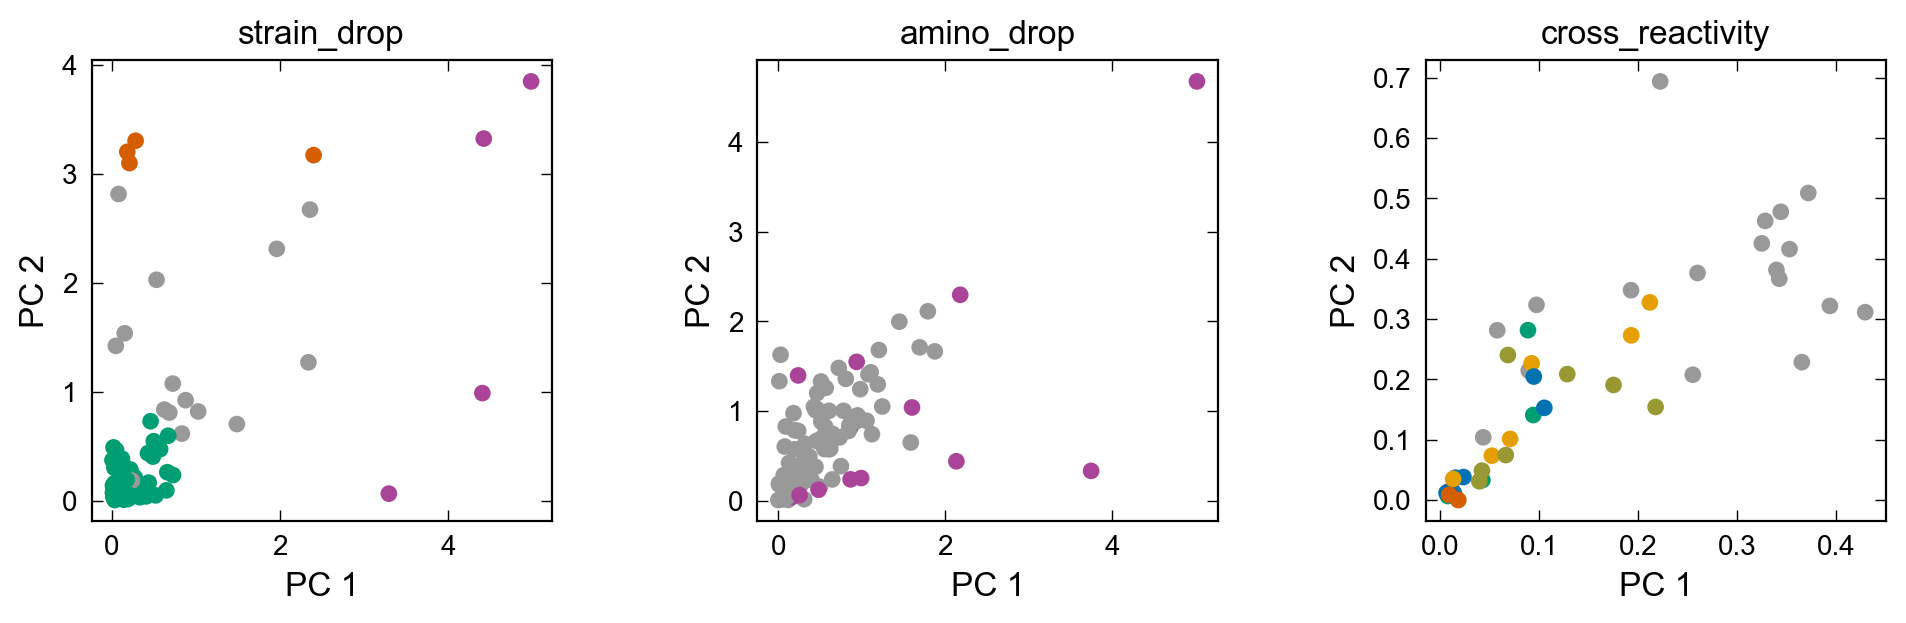

In [26]:
df_list = [strain_dropout_abundance_data, amino_dropout_abundance_data, cross_reactivity_data.loc[cross_reactivity_data.strain_id.notna()]]
cluster_vars_list = [['drop_Ch_abundance','drop_Cs_abundance', 'drop_ChCs_abundance'],
                     ['Arginine', 'Histidine', 'Tryptophan'],
                     ['H1-19','H1-38','H1-24','H1-26','H1-27','H1-09','H1-16',
                      'H1-25',
                      'H1-37','H1-39','H1-33','H1-34',
                      'H1-41','H1-14','H1-08',
                      'H1-28',
                      'H1-23']]
reference_vars_list = ['week3_cecum_abundance', 'day2_log10_abundance','GF']
label_list = ['strain_drop','amino_drop','cross_reactivity']
cluster_num_list = [4,2,7]
pca_num_list = [3,3,4]
full_data_w_clusters = full_data

fig, axs = plt.subplots(1, 3, figsize=(10.0, 3.0), sharex = False, constrained_layout=True)


for i, df in enumerate(df_list):
    if i == 0:
        input_data = df[cluster_vars_list[i] + [reference_vars_list[i]]].sort_values(by=reference_vars_list[i], ascending= False).replace([0.0], 1e-6).apply(clr_transform, axis=0).fillna(0)
        cluster_input = input_data[cluster_vars_list[i]].sub(input_data[reference_vars_list[i]], axis=0)
        mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars_list[i])
        scaler.fit(cluster_input[cluster_vars_list[i]].values[mask])
        for_clustering = np.abs(scaler.transform(cluster_input[cluster_vars_list[i]].values[mask]))
    elif i == 1:
        input_data = 10**(df[cluster_vars_list[i] + [reference_vars_list[i]]].fillna(-6)).sort_values(by=reference_vars_list[i], ascending= False).apply(clr_transform, axis=0).fillna(0).replace([-np.inf], 0.0)
        scaler = StandardScaler()
        cluster_input = input_data[cluster_vars_list[i]].sub(input_data[reference_vars_list[i]], axis=0)
        mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars_list[i])
        scaler.fit(cluster_input[cluster_vars_list[i]].values[mask])
        for_clustering = np.abs(scaler.transform(cluster_input[cluster_vars_list[i]].values[mask]))
    else:
        input_data = df[cluster_vars_list[i] + [reference_vars_list[i]]]
        normalizer = Normalizer(norm='l2')
        cluster_input = input_data[cluster_vars_list[i]]
        mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars_list[i])
        cluster_input_norm = normalizer.fit_transform(cluster_input[cluster_vars_list[i]].values[mask])
        for_clustering = cluster_input_norm

    cluster_input['strain_id'] = df.sort_values(by=reference_vars_list[i], ascending= False)['strain_id'] 
    clustering_object = KMeans(n_clusters=cluster_num_list[i], n_init = 10, random_state=0)
    clustering = clustering_object.fit(for_clustering)
    cluster_input.loc[mask,label_list[i]+'_cluster'] = (clustering.labels_ + 1).astype('int64')
    full_data_w_clusters = full_data_w_clusters.merge(cluster_input.loc[cluster_input.strain_id.notna(),['strain_id', label_list[i]+'_cluster'] + (cluster_vars_list[i] if i == 0 else [])], 
                               how = 'left', on = 'strain_id', validate = 'many_to_one')

    full_data_w_clusters.loc[:,label_list[i]+'_cluster'] = full_data_w_clusters[label_list[i]+'_cluster'].fillna(0).astype('int64')

    # Make plots
    axs[i].scatter(for_clustering[:,0], for_clustering[:,1],
                c = clustering.labels_,
              cmap = custom_cmap_discrete)

for j, ax in enumerate(axs.flat):
    ax.set_xlabel(r'PC 1', fontsize = 12)
    ax.set_ylabel(r'PC 2', fontsize = 12)
    ax.set_title(label_list[j], fontsize = 12)   
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33658/2697926103.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hybridoma_cluster_data.loc[:, "total_Treg"] = np.sum(hybridoma_cluster_data[['pTreg','tTreg']].values, axis = 1)
/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33658/2697926103.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hybridoma_cluster_data.loc[:, "total_effector"] = np.sum(hybridoma_cluster_data[['Th1','Th2', 'Th17', 'Other Effector Th']].values, axis = 1)

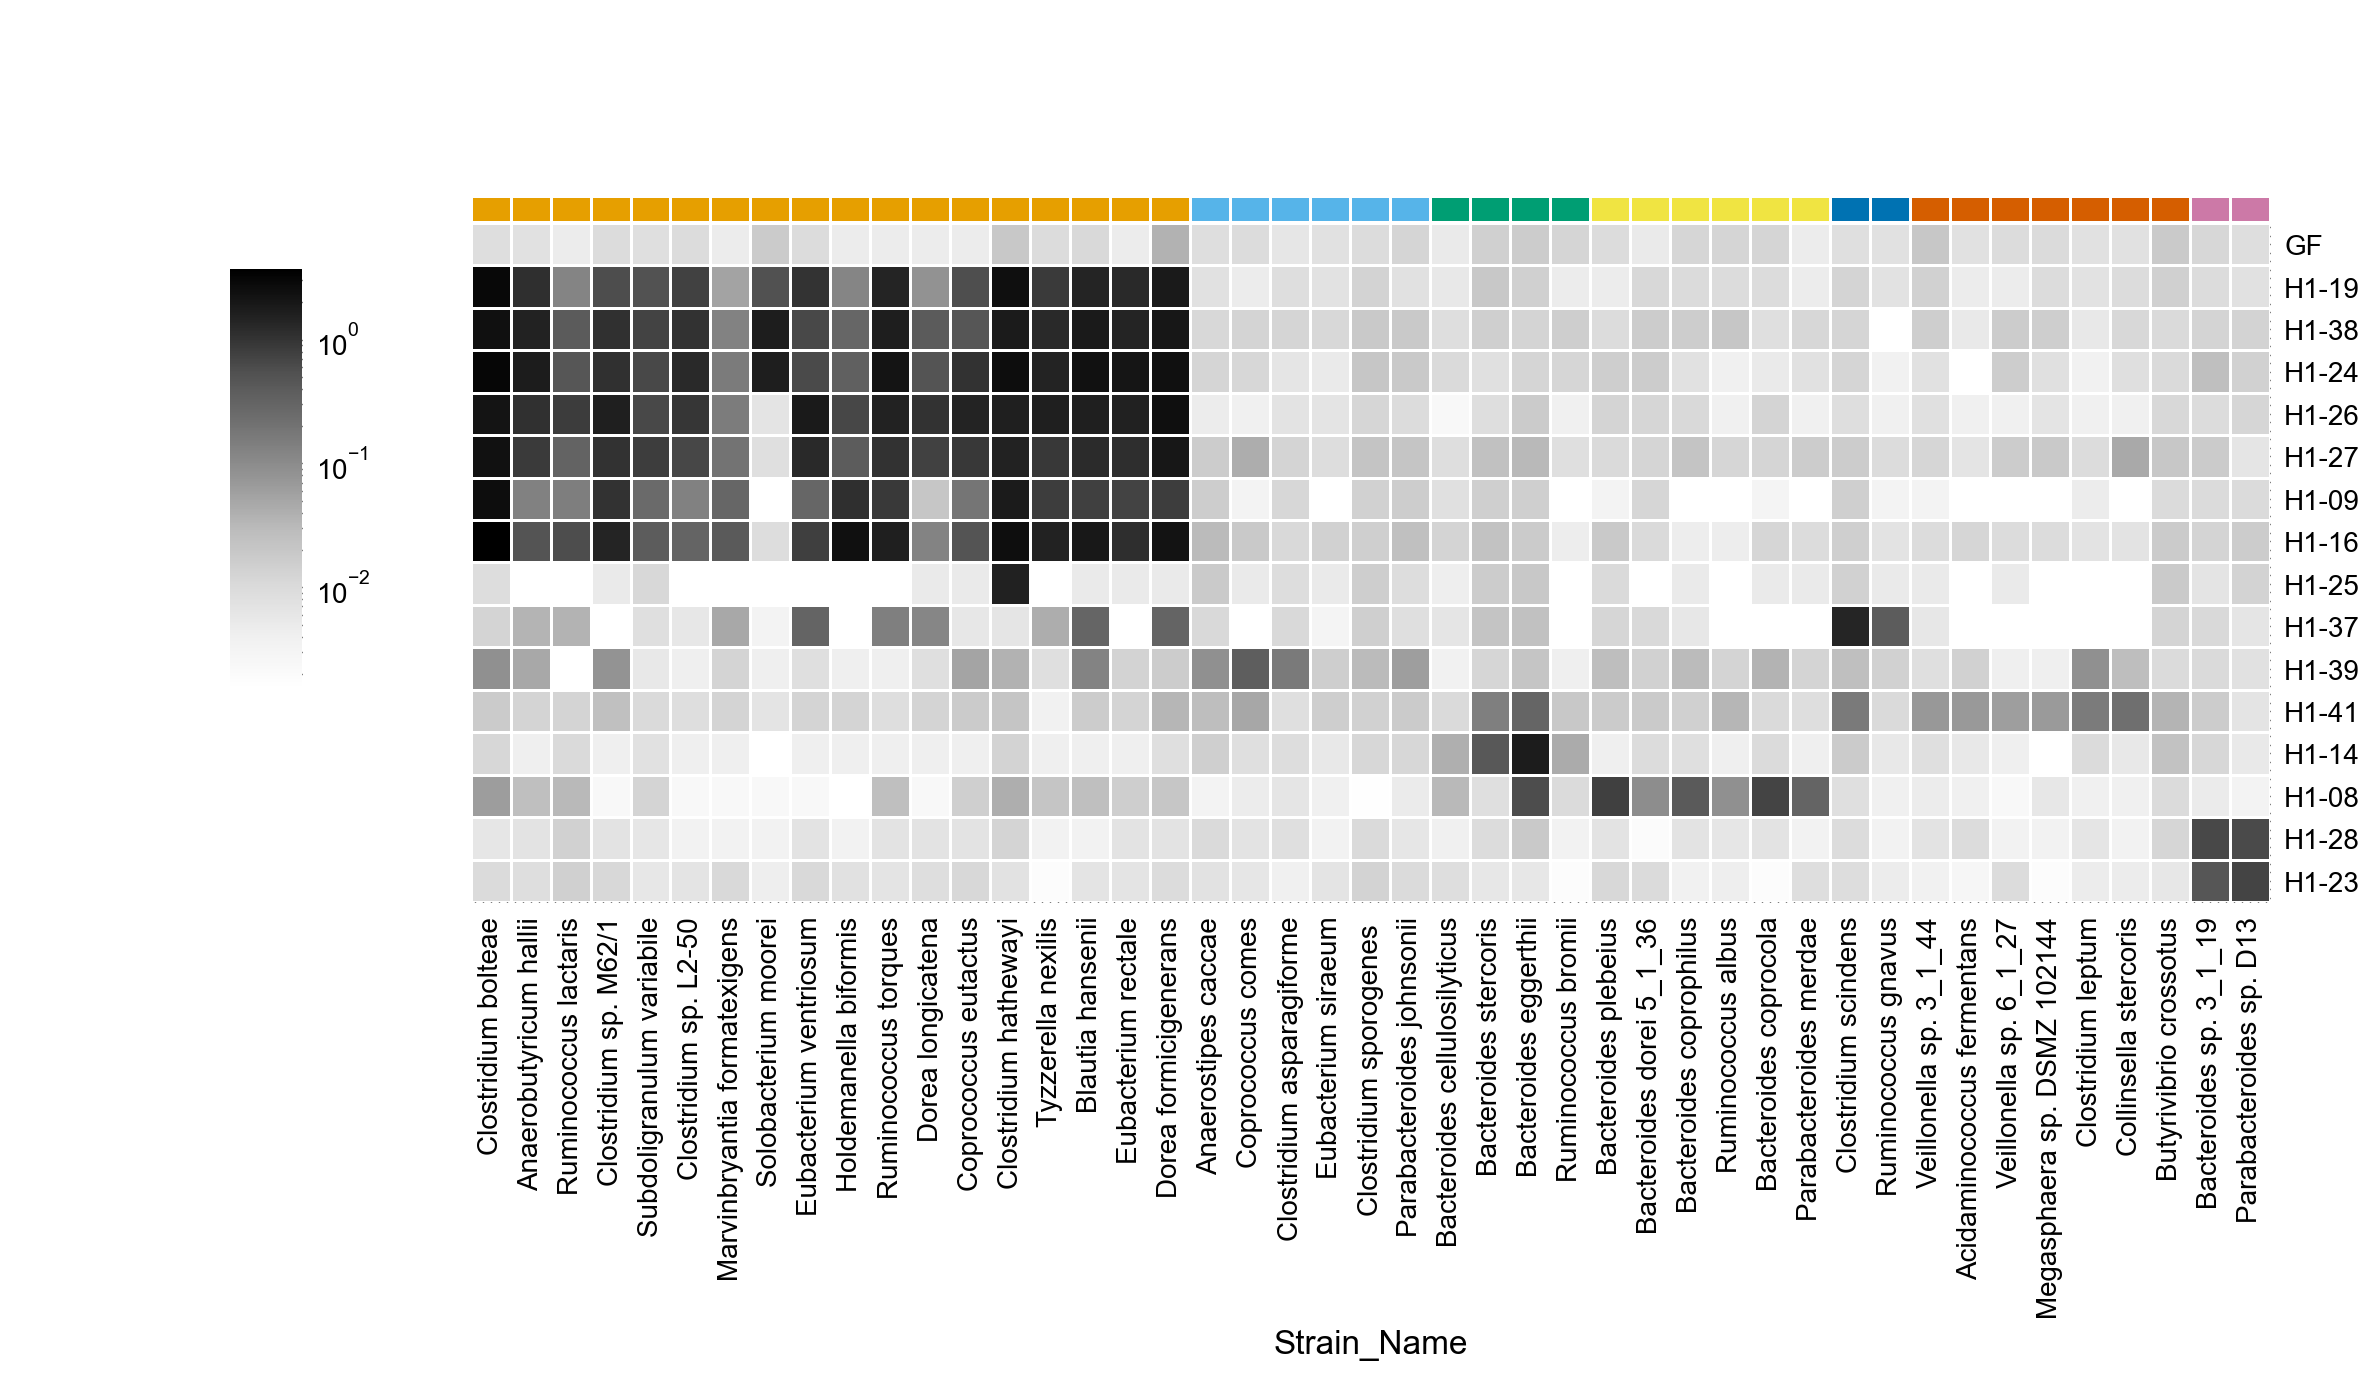

In [27]:
hybridoma_vars = ['H1-19','H1-38','H1-24','H1-26','H1-27','H1-09','H1-16',
            'H1-25',
            'H1-37','H1-39', # 'H1-33','H1-34', bind food
            'H1-41','H1-14','H1-08',
            'H1-28',
            'H1-23']

var_list = ['Th1','Th2', 'Th17', 'Other Effector Th', 'Fr4 Th', 'Memory', 'pTreg', 'tTreg']
extend_var_list = var_list + ["total_Treg", "total_effector", 'mean_sigma']

cross_reac_fig_data = cross_reactivity_data.loc[cross_reactivity_data.strain_id.notna()].merge(full_data_w_clusters[['strain_id','imm_resp_flag', 'sig_imm_resp_flag', 'cross_reactivity_cluster', 'replicate', 'Batch1_week1']], 
                                                                                                    how = 'left', on = 'strain_id', validate = 'one_to_many').sort_values(by='cross_reactivity_cluster', 
                                                                                                                            ascending= True)

hybridoma_abundance_data.loc[:, "total_Treg"] = np.sum(hybridoma_abundance_data[['pTreg','tTreg']].values, axis = 1)
hybridoma_abundance_data.loc[:, "total_effector"] = np.sum(hybridoma_abundance_data[['Th1','Th2', 'Th17', 'Other Effector Th']].values, axis = 1)
hybridoma_abundance_data.loc[:,'hybridoma_weight'] = hybridoma_abundance_data.groupby(['Community'], as_index = False)['total_effector'].transform(lambda x: x/np.sum(x))

cross_reac_fig_data.loc[:,'mean_sigma'] = np.sum([np.maximum(cross_reac_fig_data[hyb].values - cross_reac_fig_data['GF'].values, 0)*hybridoma_abundance_data.loc[hybridoma_abundance_data.Hybridoma == hyb]['hybridoma_weight'].item() for hyb in hybridoma_vars], axis = 0)
#np.amax(cross_reac_fig_data[hybridoma_vars].values, axis = 1)

hybridoma_cluster_data = cross_reac_fig_data[['cross_reactivity_cluster', 'strain_id', 'Batch1_week1', 'replicate', 'mean_sigma', 'GF'] + hybridoma_vars]
hybridoma_cluster_data.loc[:,var_list] = np.vstack([np.sum([np.maximum(hybridoma_cluster_data[hyb].values - hybridoma_cluster_data['GF'].values, 0)*hybridoma_abundance_data.loc[hybridoma_abundance_data.Hybridoma == hyb][var].item() for hyb in hybridoma_vars], axis = 0) for var in var_list]).T
hybridoma_cluster_data.loc[:, "total_Treg"] = np.sum(hybridoma_cluster_data[['pTreg','tTreg']].values, axis = 1)
hybridoma_cluster_data.loc[:, "total_effector"] = np.sum(hybridoma_cluster_data[['Th1','Th2', 'Th17', 'Other Effector Th']].values, axis = 1)
hybridoma_cluster_data.loc[:,'microbe_weight'] = hybridoma_cluster_data.groupby(['cross_reactivity_cluster', 'replicate'], as_index = False)['Batch1_week1'].transform(lambda x: x/np.sum(x))
hybridoma_cluster_data.loc[:,['weighted_' + var for var in extend_var_list]] = np.vstack([hybridoma_cluster_data['microbe_weight']*hybridoma_cluster_data[var] for var in extend_var_list]).T

plot_data = cross_reac_fig_data[['GF'] + hybridoma_vars + ['Strain_Name', 'cross_reactivity_cluster']].groupby('Strain_Name', as_index = True, sort = False).mean()
# plot_data.loc[:, hybridoma_vars] = plot_data[hybridoma_vars]

lut = {0: ito_colors[0], 1: ito_colors[1], 2: ito_colors[2], 3: ito_colors[3], 4: ito_colors[4], 5: ito_colors[5], 6: ito_colors[6], 7: ito_colors[7], 8: ito_colors[8]}
col_colors = plot_data['cross_reactivity_cluster'].map(lut)

ax = sns.clustermap(plot_data[['GF'] + hybridoma_vars].transpose(), col_colors=col_colors.values, row_cluster=False, col_cluster=False,
              norm=mpl.colors.LogNorm(), cmap='Greys', fmt=".2f", linewidths=.5,
              cbar_pos=(0.1, .5, .03, .3), figsize=(12, 7))

# The 'fig' object is accessible via the .figure attribute
fig = ax.figure
plt.show()

# To save the figure, use the savefig method of the ClusterGrid object to avoid clipping
ax.savefig('_figs/fig_receptor_clusters_H1'+'.pdf', dpi=300, bbox_inches='tight')

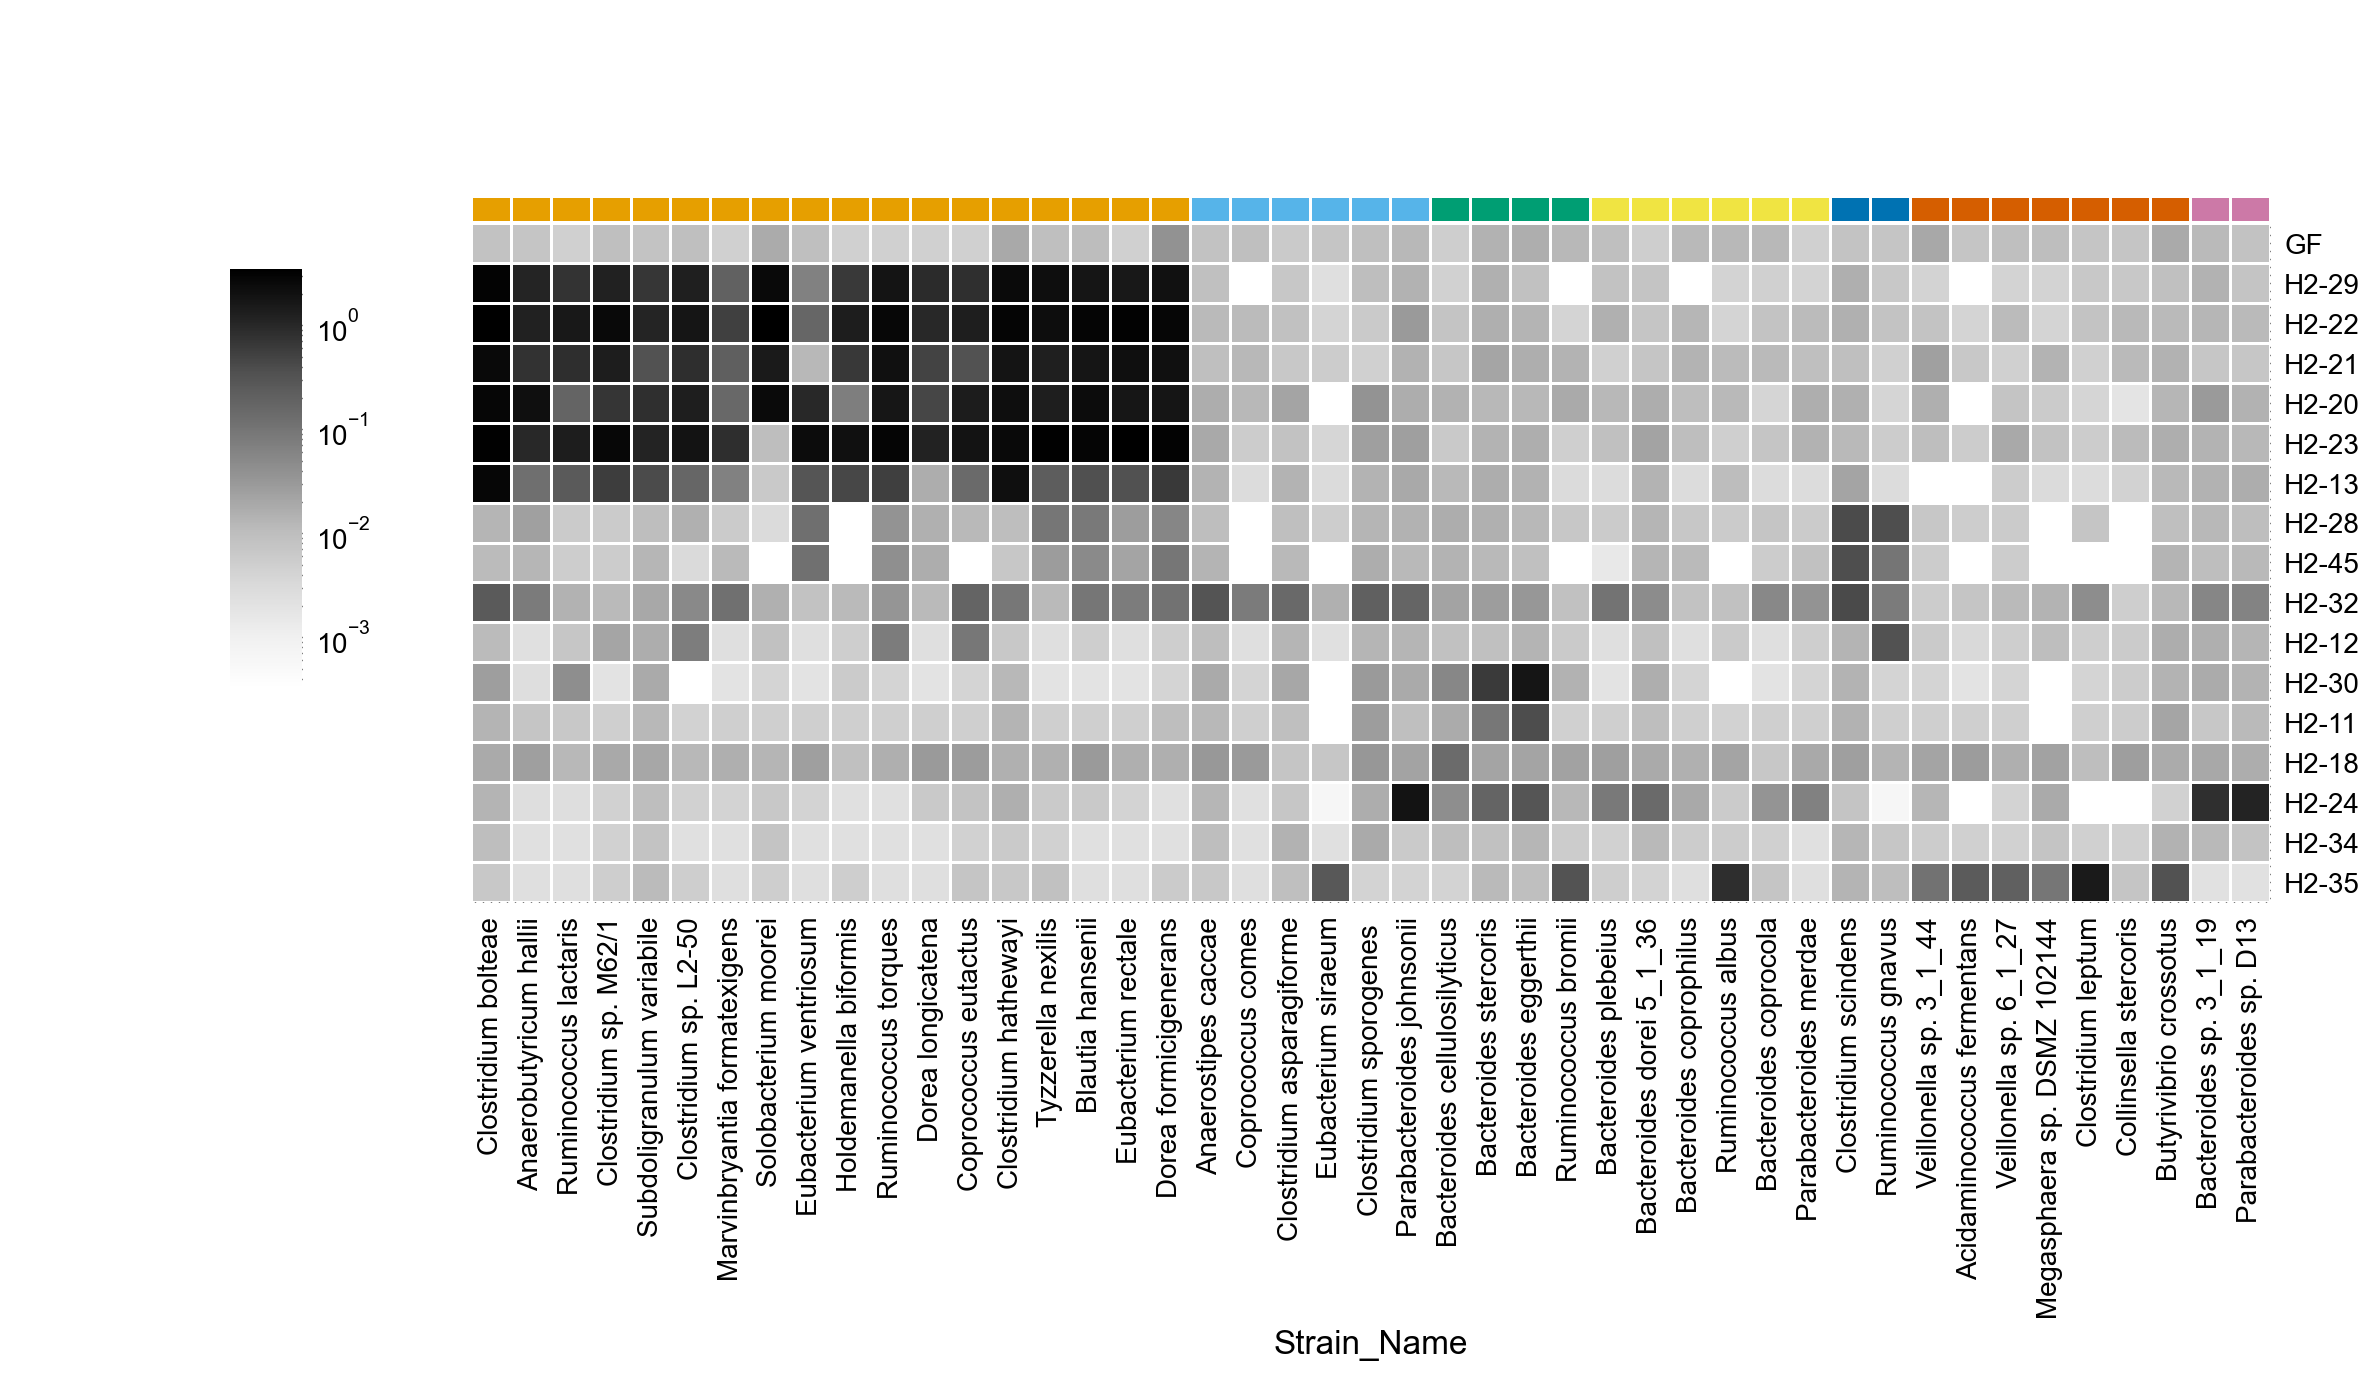

In [28]:
# Make plot for Hybridoma 2
hybridoma2_vars = ['H2-29','H2-22','H2-21','H2-20',
 'H2-23','H2-13','H2-28','H2-45',
 'H2-32','H2-12','H2-30','H2-11', #bind food: 'H2-04','H2-39',
 'H2-18','H2-24','H2-34','H2-35']

plot_data = cross_reac_fig_data[['GF'] + hybridoma2_vars + ['Strain_Name', 'cross_reactivity_cluster']].groupby('Strain_Name', as_index = True, sort = False).mean()
# plot_data.loc[:, hybridoma_vars] = plot_data[hybridoma_vars]

lut = {0: ito_colors[0], 1: ito_colors[1], 2: ito_colors[2], 3: ito_colors[3], 4: ito_colors[4], 5: ito_colors[5], 6: ito_colors[6], 7: ito_colors[7], 8: ito_colors[8]}
col_colors = plot_data['cross_reactivity_cluster'].map(lut)

ax = sns.clustermap(plot_data[['GF'] + hybridoma2_vars].transpose(), col_colors=col_colors.values, row_cluster=False, col_cluster=False,
              norm=mpl.colors.LogNorm(), cmap='Greys', fmt=".2f", linewidths=.5,
              cbar_pos=(0.1, .5, .03, .3), figsize=(12, 7))

# The 'fig' object is accessible via the .figure attribute
fig = ax.figure
plt.show()

# To save the figure, use the savefig method of the ClusterGrid object to avoid clipping
ax.savefig('_figs/fig_receptor_clusters_H2_w_H1_clusters'+'.pdf', dpi=300, bbox_inches='tight')

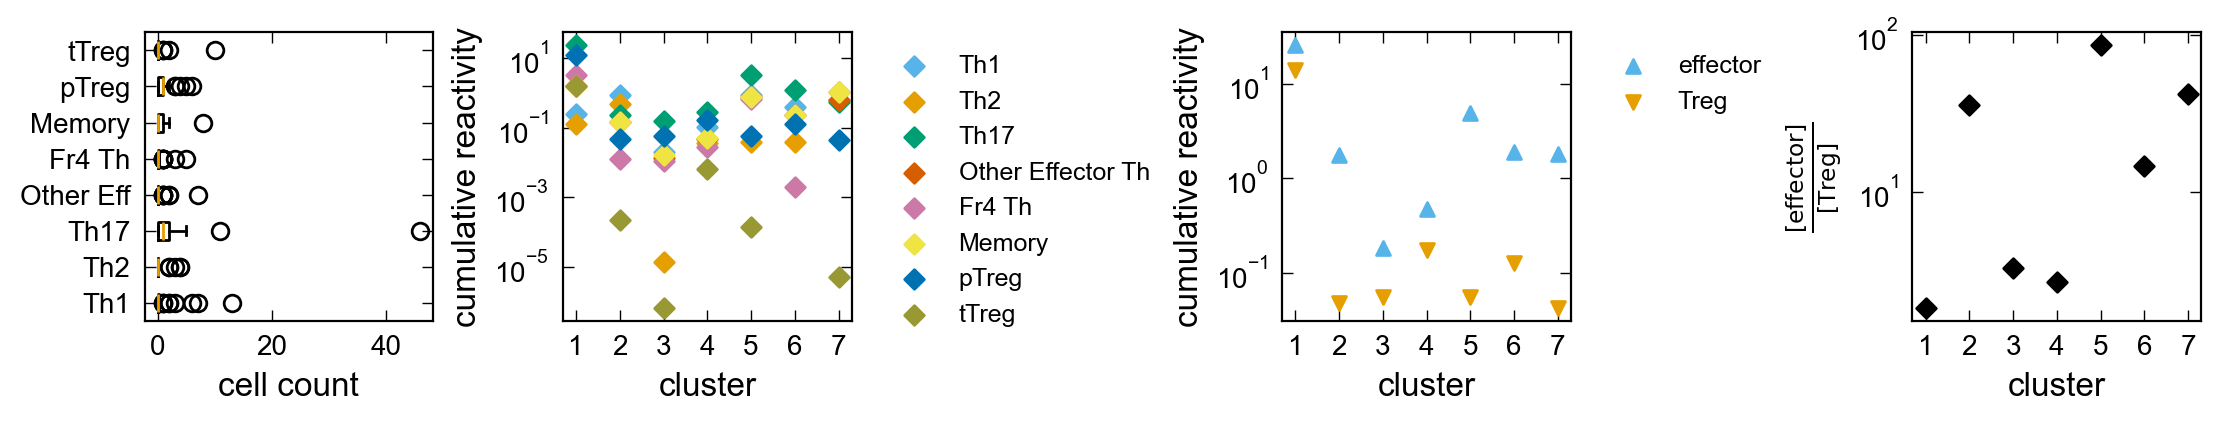

In [29]:
# Plot figures
fig, axs = plt.subplots(1, 4, figsize=(11.0, 2.0), sharex = False, constrained_layout=True)
          
var_list = ['Th1','Th2', 'Th17', 'Other Effector Th', 'Fr4 Th', 'Memory', 'pTreg', 'tTreg']
var_labels = ['Th1','Th2', 'Th17', 'Other Eff', 'Fr4 Th', 'Memory', 'pTreg', 'tTreg']

for_figb = hybridoma_cluster_data.drop(['strain_id'], axis=1).groupby(['cross_reactivity_cluster','replicate'], as_index = False).sum()

for_figc = for_figb.drop(['replicate'], axis=1).groupby('cross_reactivity_cluster', as_index = False).mean()

axs[0].boxplot(hybridoma_abundance_data[var_list], tick_labels= var_labels, orientation = 'horizontal')
axs[0].set_xlabel('cell count', fontsize = 12)

for var in var_list:
    axs[1].scatter(for_figc.cross_reactivity_cluster, for_figc['weighted_'+var], marker = 'D', label = var)

axs[2].scatter(for_figc.cross_reactivity_cluster, for_figc['weighted_total_effector'], marker = '^', label = 'effector')
axs[2].scatter(for_figc.cross_reactivity_cluster, for_figc['weighted_total_Treg'], marker = 'v', label = 'Treg')

axs[3].scatter(for_figc.cross_reactivity_cluster, for_figc['weighted_total_effector']/for_figc['weighted_total_Treg'], 
               marker = 'D', label = 'Treg', color = 'black')

axs[1].legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
axs[1].set_ylabel('cumulative reactivity', fontsize = 12)
axs[1].semilogy()
axs[1].set_xticks(for_figc.cross_reactivity_cluster)
axs[1].set_xlabel('cluster', fontsize = 12)

axs[2].legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
axs[2].set_ylabel('cumulative reactivity', fontsize = 12)
axs[2].semilogy()
axs[2].set_xticks(for_figc.cross_reactivity_cluster)
axs[2].set_xlabel('cluster', fontsize = 12)

axs[3].set_ylabel(r'$\frac{[\text{effector}]}{[\text{Treg}]}$', fontsize = 12)
axs[3].set_xlabel('cluster', fontsize = 12)
axs[3].semilogy()
axs[3].set_xticks(for_figc.cross_reactivity_cluster)


for j, ax in enumerate(axs.flat):
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_hybridoma_cell_count_by_type'+'.pdf', dpi=300, bbox_inches='tight')

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33658/3568557493.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[i, cluster].legend(fontsize=9, loc = 'upper right', framealpha=0)
/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33658/3568557493.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[i, cluster].legend(fontsize=9, loc = 'upper right', framealpha=0)
/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33658/3568557493.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[i, cluster].legend(fontsize=9, loc = 'upper right', framealpha=0)


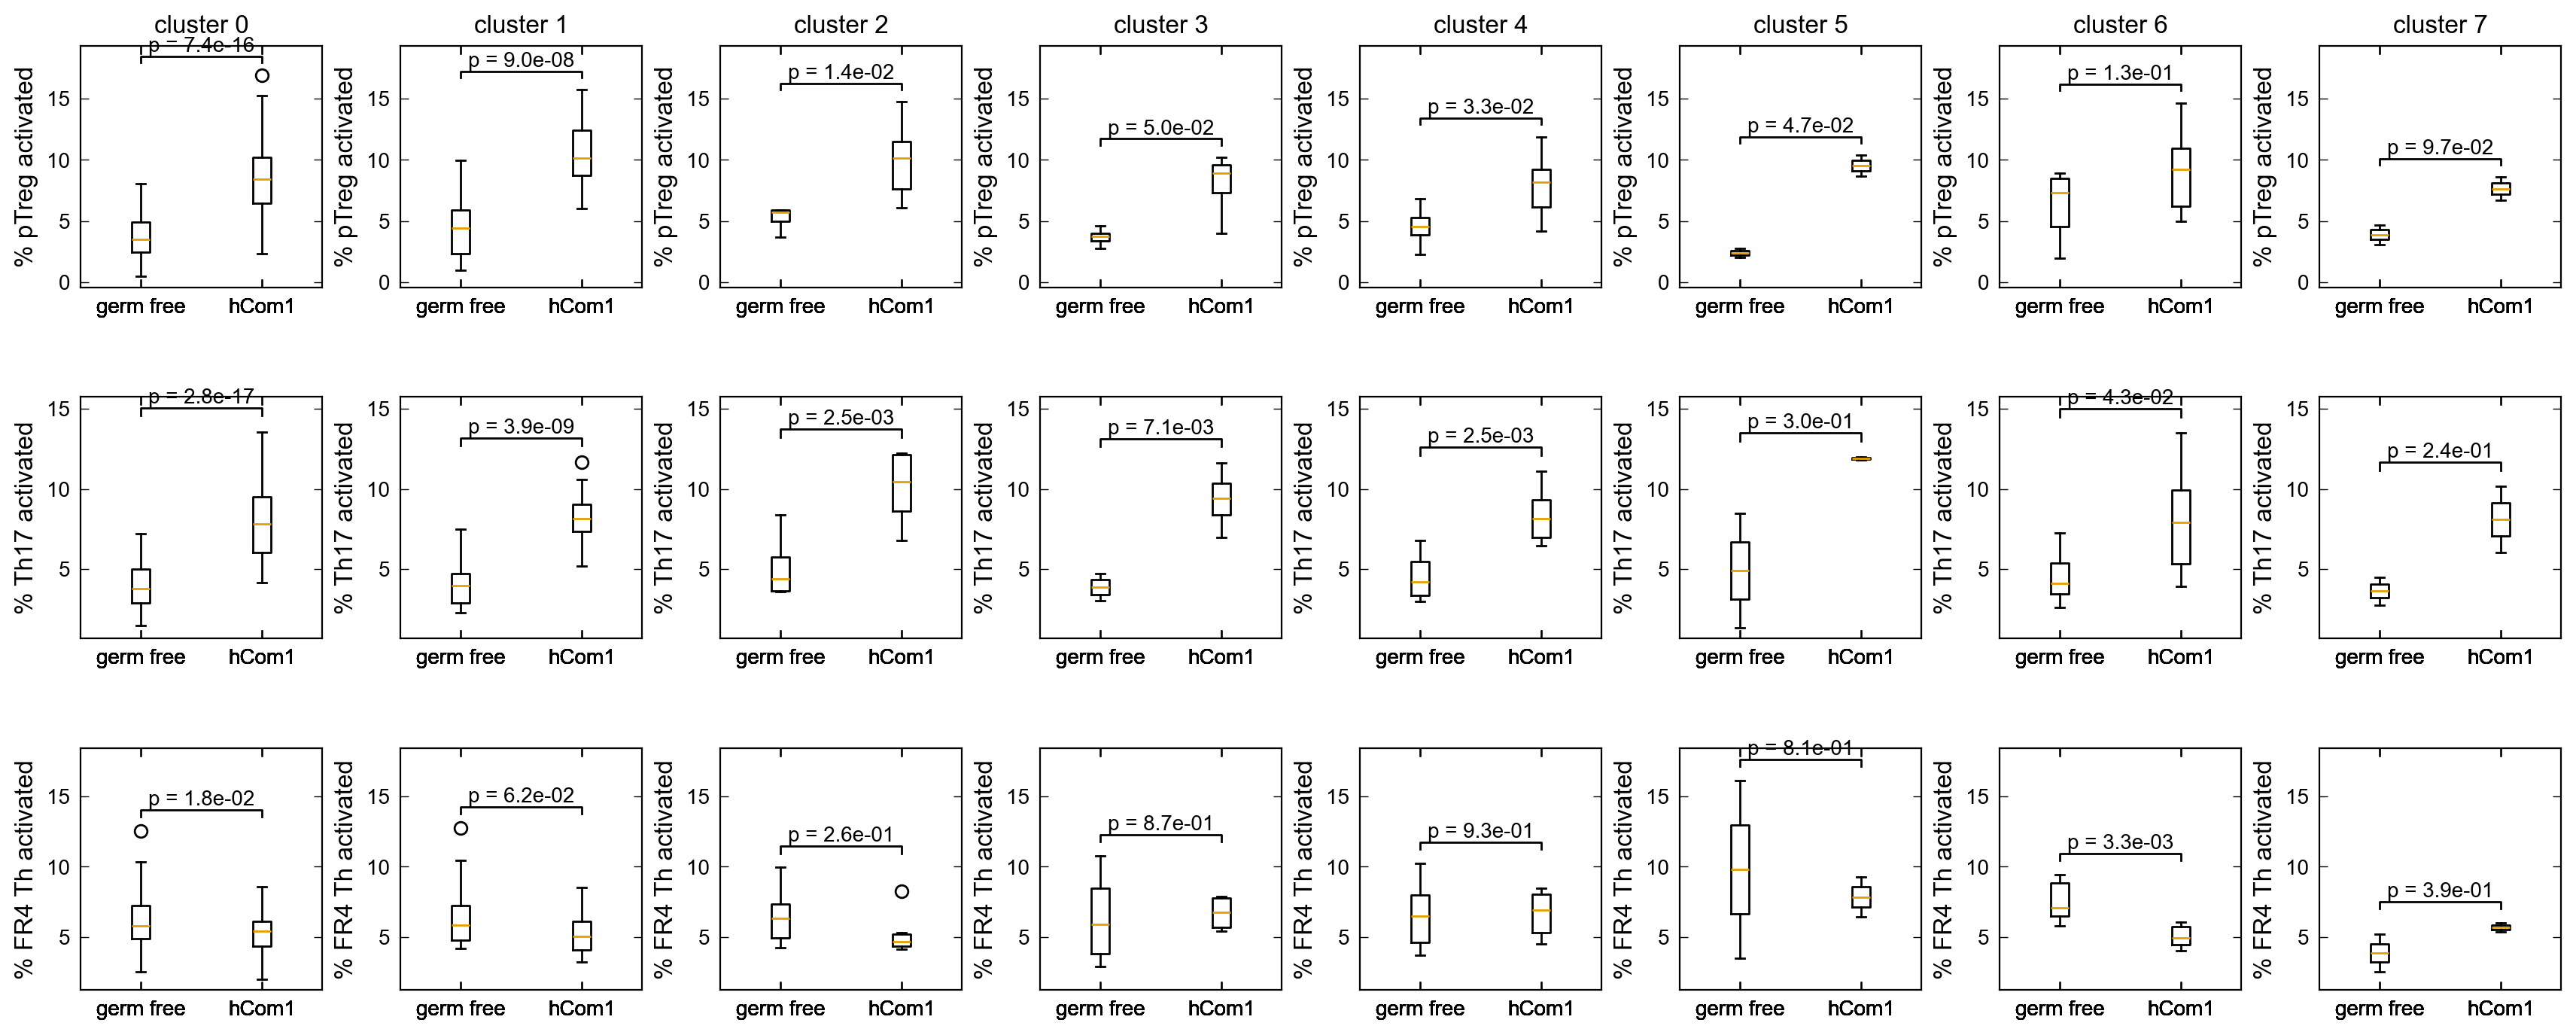

In [30]:
# Plot figures
fig, axs = plt.subplots(3, 8, figsize=(17.0, 7.0), sharex = 'row', sharey = 'row', constrained_layout=True)

coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']
var_list = [['GF_pTreg_Average', 'hCom1d_pTreg_Average'], 
                      ['GF_Th17_Average', 'hCom1d_Th17_Average'], 
                      ['GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']]

data = full_data_w_clusters[['Name', 'cross_reactivity_cluster'] + coverage_variables].groupby(['Name', 'cross_reactivity_cluster'], as_index = False).mean()

for i, var in enumerate(var_list):
    for (_, g) in data.groupby('cross_reactivity_cluster'):
        cluster = int(g['cross_reactivity_cluster'].values[0])
        GF_pop, hcom1_pop = g[var[0]], g[var[1]]
        axs[i, cluster].boxplot([GF_pop, hcom1_pop], tick_labels=['germ free', 'hCom1'])
        if i == 0:
            axs[i, cluster].set_title('cluster '+str(int(cluster)), fontsize = 12) 

        if cluster == 0:
            axs[i, cluster].legend(fontsize=9, loc = 'upper right', framealpha=0)
        
        axs[i, cluster].set_ylabel(['% pTreg activated', '% Th17 activated', '% FR4 Th activated'][i], fontsize = 12)
            

        # Run two-sided Mann-Whitney test with null that the two distribitions are identical
        tind_stat, p_value = ttest_ind(GF_pop, hcom1_pop, equal_var=False)
        x1, x2 = 1, 2   # columns 'Sat' and 'Sun' (first column: 0, see plt.xticks())
        y, h, col = np.amax(np.array([GF_pop, hcom1_pop])) + 1, 0.5, 'k'
        axs[i, cluster].plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.0, c=col)
        axs[i, cluster].text((x1+x2)*.5, y+h, f'p = {p_value:.1e}', ha='center', va='bottom', color=col)

        axs[i, cluster].set_box_aspect(1)
        axs[i, cluster].minorticks_off()
        axs[i, cluster].tick_params(axis='both', which='major', labelsize=10)
        axs[i, cluster].xaxis.set_tick_params(labeltop=False)
        axs[i, cluster].yaxis.set_tick_params(labelleft=True)

# fig.savefig('_figs/fig_immune_activation_GF_hcom1'+'.pdf', dpi=300, bbox_inches='tight')

In [31]:
# Create CLR datasets
plot_variables = ['GF_Th17_Average', 'hCom1d_Th17_Average']
cluster_variable= 'cross_reactivity_cluster'
var_list = ['day0_abundance_batch1', 'Batch1_week1', 'Batch1_week2', 'Batch1_week3', 'Batch1_week4']
additional_day0_vars = ['day0_abundance_batch2', 'day0_abundance_batch3']
additional_wk2_vars = ['day14_abundance']
additional_wk4_vars = ['Batch2_week4_m1', 'Batch2_week4_m2', 'Batch2_week4_m3',
                       'Batch3_week4_m1', 'Batch3_week4_m2', 'Batch3_week4_m3', 'Batch3_week4_m4', 'Batch3_week4_m5']

additional_abundance_vars = additional_day0_vars + additional_wk2_vars + additional_wk4_vars
replicate_num = 5

# Prepare cluster level data
cluster_abundance_data = full_data_w_clusters[var_list + [cluster_variable, 'replicate'] + additional_abundance_vars].groupby([cluster_variable, 'replicate'], as_index = False).sum()
cluster_abundance_data.loc[:, 'Batch1_peak'] = np.amax(cluster_abundance_data[['Batch1_week1', 'Batch1_week2', 'Batch1_week3', 'Batch1_week4']], axis = 1)
cluster_abundance_data.loc[:, 'Batch1_peak_1_2'] = np.amax(cluster_abundance_data[['Batch1_week1', 'Batch1_week2']], axis = 1)
cluster_clr_list = []
for (_, g) in cluster_abundance_data.groupby(['replicate'], sort = False):
    df = g.reset_index()
    df.loc[:,['day0_clr', 'wk1_clr', 'wk2_clr', 'wk3_clr', 'wk4_clr']] = df[['day0_abundance_batch1', 'Batch1_week1', 'Batch1_week2', 'Batch1_week3', 'Batch1_week4']].apply(clr_transform, axis=0).values
    cluster_clr_list.append(df)

cluster_clr_data = pd.concat(cluster_clr_list).reset_index(drop = True).replace([np.inf, -np.inf], np.nan)
cluster_clr_data.loc[:, 'peak_1_2_clr'] = np.amax(cluster_clr_data[['wk1_clr', 'wk2_clr']], axis = 1)
cluster_clr_data.loc[:, 'peak_clr'] = np.amax(cluster_clr_data[['wk1_clr', 'wk2_clr', 'wk3_clr', 'wk4_clr']], axis = 1)

# Prepare strain level data
strain_abundance_data = pd.concat([cluster_abundance_data.head(replicate_num),
                         full_data_w_clusters[var_list + [cluster_variable, 'replicate'] + additional_abundance_vars]]).reset_index(drop = True)
strain_abundance_data.loc[:,'strain_id'] = np.array(replicate_num*['nonimmunogenic_cluster'] + full_data_w_clusters.strain_id.tolist())
strain_abundance_data.loc[:, 'Batch1_peak'] = np.amax(strain_abundance_data[['Batch1_week1', 'Batch1_week2', 'Batch1_week3', 'Batch1_week4']], axis = 1)
strain_abundance_data.loc[:, 'Batch1_peak_1_2'] = np.amax(strain_abundance_data[['Batch1_week1', 'Batch1_week2']], axis = 1)

strain_clr_list = []
for (_, g) in strain_abundance_data.groupby(['replicate'], sort = False):
    df = g.reset_index()
    df.loc[:,['day0_clr', 'wk1_clr', 'wk2_clr', 'wk3_clr', 'wk4_clr']] = df[['day0_abundance_batch1', 'Batch1_week1', 'Batch1_week2', 'Batch1_week3', 'Batch1_week4']].apply(clr_transform, axis=0).values
    strain_clr_list.append(df)

strain_clr_data = pd.concat(strain_clr_list).reset_index(drop = True).replace([np.inf, -np.inf], np.nan)
strain_clr_data.loc[:, 'peak_1_2_clr'] = np.amax(strain_clr_data[['wk1_clr', 'wk2_clr']], axis = 1)
strain_clr_data.loc[:, 'peak_clr'] = np.amax(strain_clr_data[['wk1_clr', 'wk2_clr', 'wk3_clr', 'wk4_clr']], axis = 1)

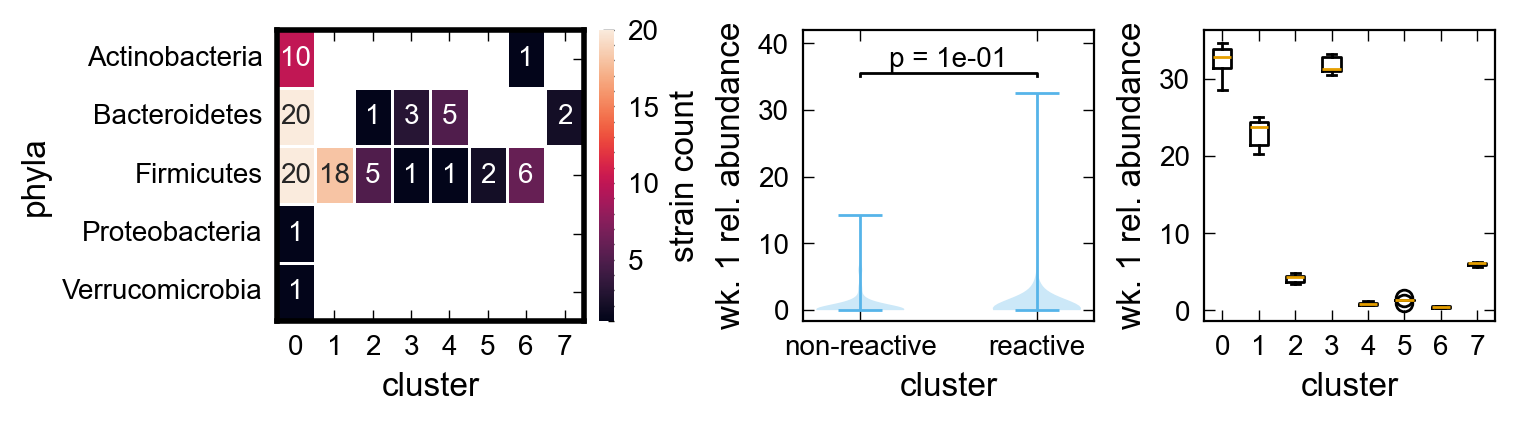

In [32]:
fig, axs = plt.subplots(1,3, figsize=(7.5, 2), sharex = False, constrained_layout=True)

# Fig a: phlya X cross-reactivity cluster
input_data = full_data_w_clusters.loc[full_data_w_clusters.replicate == 'm1'].groupby(['cross_reactivity_cluster', 'Phyla']).size().reset_index(name='count')
hmap_data= pd.pivot_table(input_data, values='count', index='Phyla', columns='cross_reactivity_cluster')
sns.heatmap(hmap_data, annot=True, linewidths=.5, ax=axs[0], cbar_kws={'label': 'strain count'}, xticklabels = ['0','1','2','3','4','5','6','7'])
axs[0].set(xlabel="cluster", ylabel="phyla")

for _, spine in axs[0].spines.items():
    spine.set_visible(True)
    spine.set_edgecolor('black') # Set the color of the outline
    spine.set_linewidth(2)      # Set the width of the outline

# Fig b: abundance distribution for cluster 0 v. 1-7
groups = [g['Batch1_week1'].values for (_, g) in full_data_w_clusters.groupby('imm_resp_flag')]
axs[1].violinplot(groups) #, positions=['0', '1-7'])

# Run two-sided Mann-Whitney test with null that the two distribitions are identical
from scipy.stats import mannwhitneyu
U1, p = mannwhitneyu(groups[0],groups[1], method="exact")

x1, x2 = 1, 2   # columns 'Sat' and 'Sun' (first column: 0, see plt.xticks())
y, h, col = np.amax(np.hstack(groups)) + 2.5, 0.5, 'k'
axs[1].set_ylim(top = y*(1.2))
axs[1].plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.0, c=col)
axs[1].text((x1+x2)*.5, y+h, f'p = {p:.0e}', ha='center', va='bottom', color=col)

axs[1].set_ylabel('wk. 1 rel. abundance', fontsize = 12)
axs[1].set_xticks([1,2])
axs[1].set_xticklabels(['non-reactive', 'reactive'])

axs[1].set_xlabel('cluster', fontsize = 12)
axs[1].set_box_aspect(1)

axs[2].boxplot([g['Batch1_week1'].values for (_, g) in cluster_abundance_data.groupby('cross_reactivity_cluster')], 
                  tick_labels=[str(int(i)) for i in np.unique(cluster_abundance_data.cross_reactivity_cluster)])

axs[2].set_ylabel('wk. 1 rel. abundance', fontsize = 12)
axs[2].set_xlabel('cluster', fontsize = 12)
axs[2].set_box_aspect(1)

for ax in axs.flat:
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_hmap_phyla_cluster_overlap'+'.pdf', dpi=300, bbox_inches='tight')

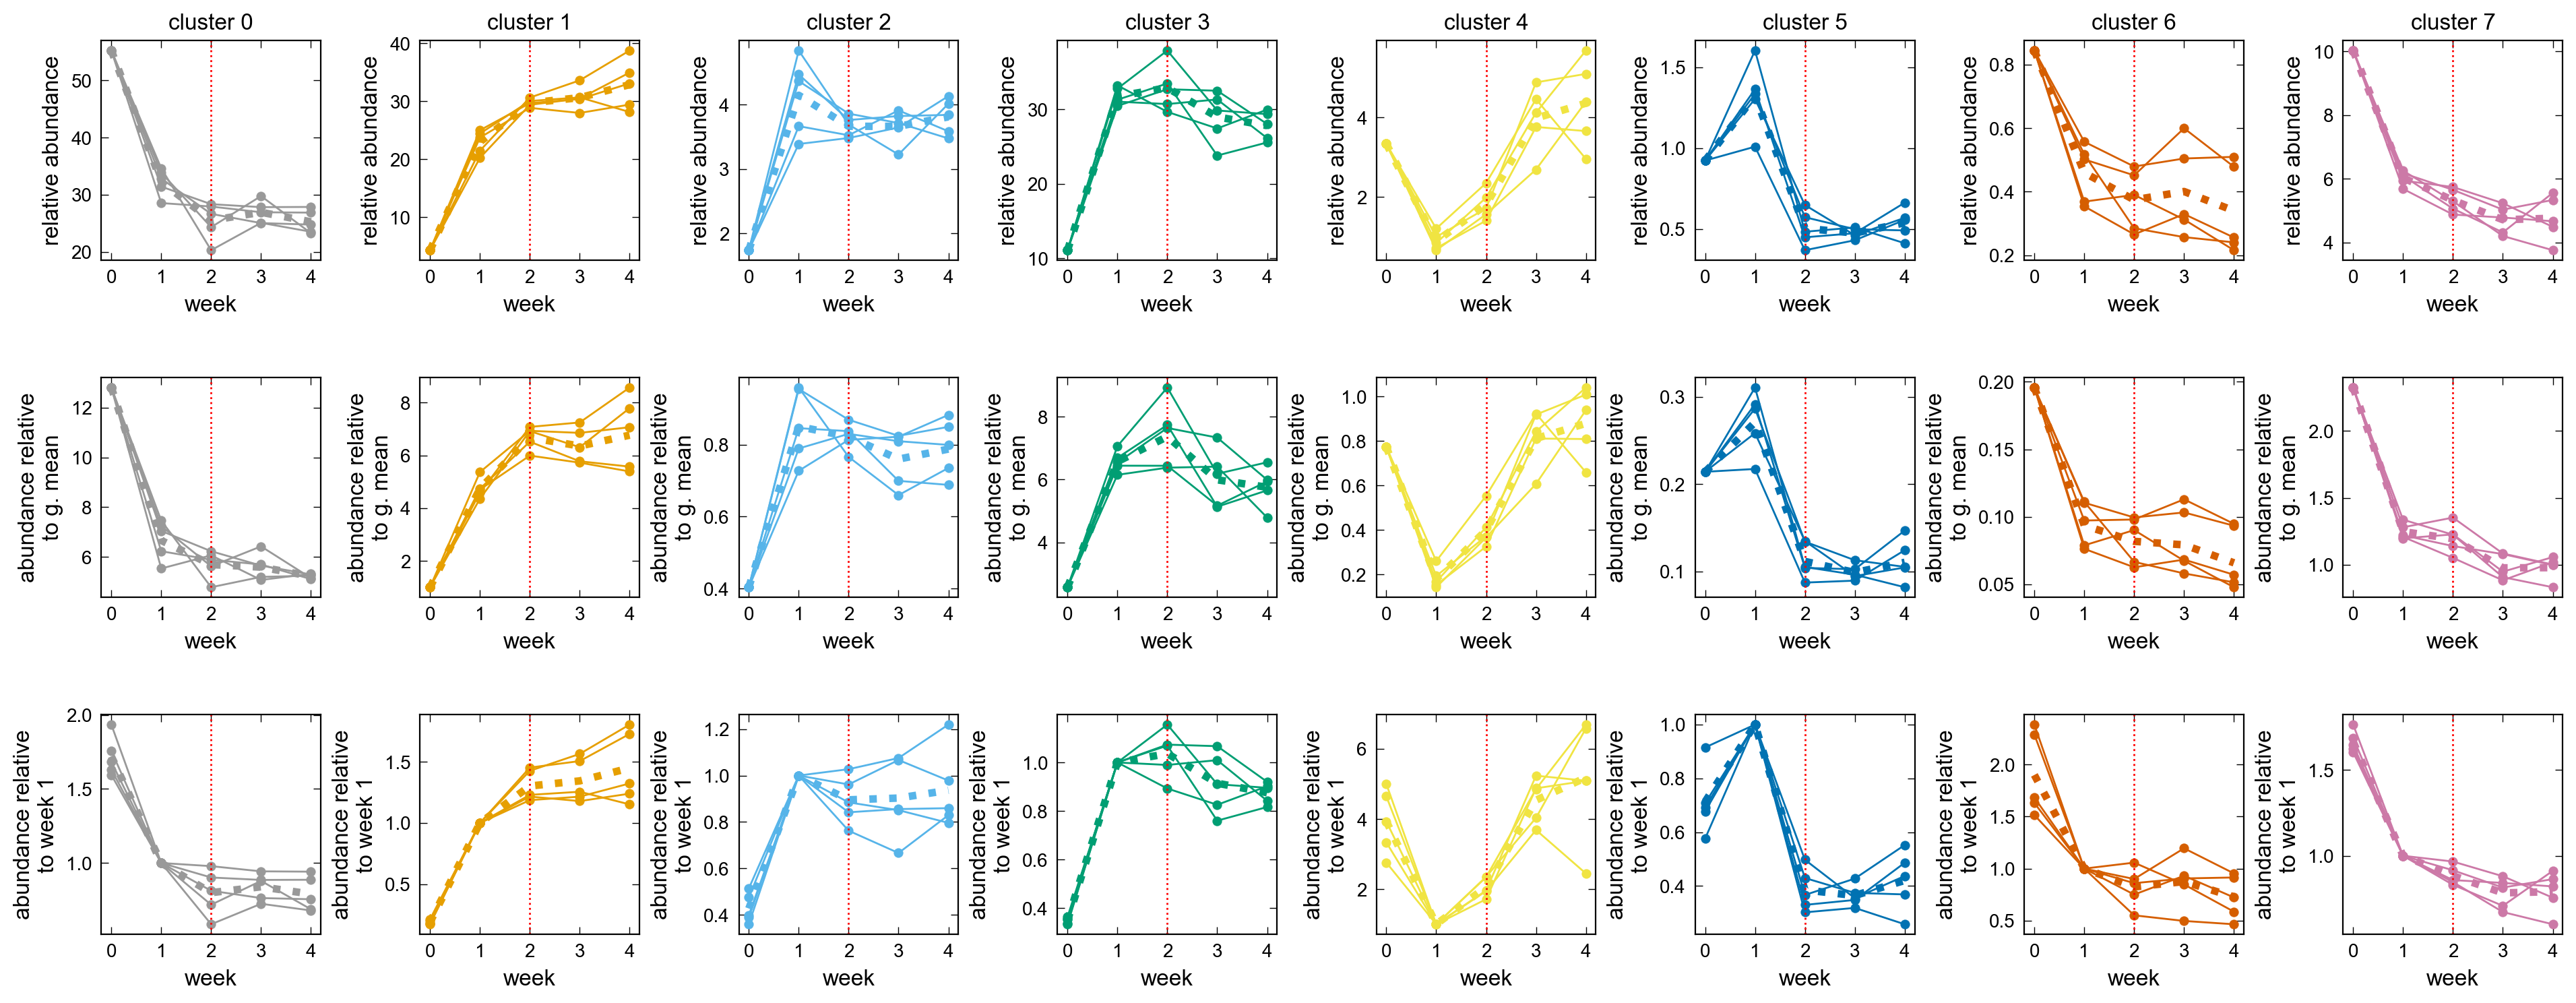

In [33]:
fig, axs = plt.subplots(3, 8, figsize=(19.0, 7.5), sharex = False, constrained_layout=True)

labels = [['day 0', 'week 1'], ['week 1', 'week 2'], ['week 2', 'week 3'], ['week 3', 'week 4']]
clr_var_list = ["day0_clr", "wk1_clr", "wk2_clr", "wk3_clr", "wk4_clr"]
abundance_var_list = ["day0_abundance_batch1", "Batch1_week1", "Batch1_week2", "Batch1_week3", "Batch1_week4"]

data = cluster_clr_data

for (_, g) in data.groupby('cross_reactivity_cluster'):
    cluster = g['cross_reactivity_cluster'].values[0]
    mean_g = g.drop('replicate', axis = 1).groupby('cross_reactivity_cluster', as_index = False).mean()
    axs[0, int(cluster)].set_title('cluster '+str(int(cluster)), fontsize = 12) 
    axs[0, int(cluster)].plot(mean_g[abundance_var_list].values.T, color = g['cross_reactivity_cluster'].map(lut).tolist()[0], linewidth = 4.0, linestyle = ':')
    axs[0, int(cluster)].plot(g[abundance_var_list].values.T, marker = 'o', color = g['cross_reactivity_cluster'].map(lut).tolist()[0])
    # axs[0, int(cluster)].scatter(len(additional_wk4_vars)*[4], mean_g[additional_wk4_vars].values.T.ravel(), color = g['cross_reactivity_cluster'].map(lut).tolist()[0], marker = '^', facecolor = 'none')
    # axs[0, int(cluster)].scatter(len(additional_wk2_vars)*[2], mean_g[additional_wk2_vars].values.T.ravel(), color = g['cross_reactivity_cluster'].map(lut).tolist()[0], marker = '^', facecolor = 'none')
    # axs[0, int(cluster)].scatter(len(additional_day0_vars)*[0], mean_g[additional_day0_vars].values.T.ravel(), color = g['cross_reactivity_cluster'].map(lut).tolist()[0], marker = '^', facecolor = 'none')
    axs[0, int(cluster)].set_ylabel('relative abundance', fontsize = 12)
    
    axs[1, int(cluster)].plot(10**np.mean(g[clr_var_list].values.T, axis = 1), color = g['cross_reactivity_cluster'].map(lut).tolist()[0], linewidth = 4.0, linestyle = ':')
    axs[1, int(cluster)].plot(10**g[clr_var_list].values.T, marker = 'o', color = g['cross_reactivity_cluster'].map(lut).tolist()[0])
    axs[1, int(cluster)].set_ylabel('abundance relative\nto g. mean', fontsize = 12)

    axs[2, int(cluster)].plot(np.mean(g[abundance_var_list].values.T/g[abundance_var_list].values.T[1, :], axis = 1), color = g['cross_reactivity_cluster'].map(lut).tolist()[0], linewidth = 4.0, linestyle = ':')
    axs[2, int(cluster)].plot(g[abundance_var_list].values.T/g[abundance_var_list].values.T[1, :], marker = 'o', color = g['cross_reactivity_cluster'].map(lut).tolist()[0])
    axs[2, int(cluster)].set_ylabel('abundance relative\nto week 1', fontsize = 12)

for j, ax in enumerate(axs.flat):
    ax.set_xlabel('week', fontsize = 12)
    ax.axvline(x = 2, ls = ':', color = 'red')
        
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)
    ax.set_xticks(np.arange(0,5))

fig.savefig('_figs/fig_rel_abundance_by_cluster_replicates'+'.pdf', dpi=300, bbox_inches='tight')

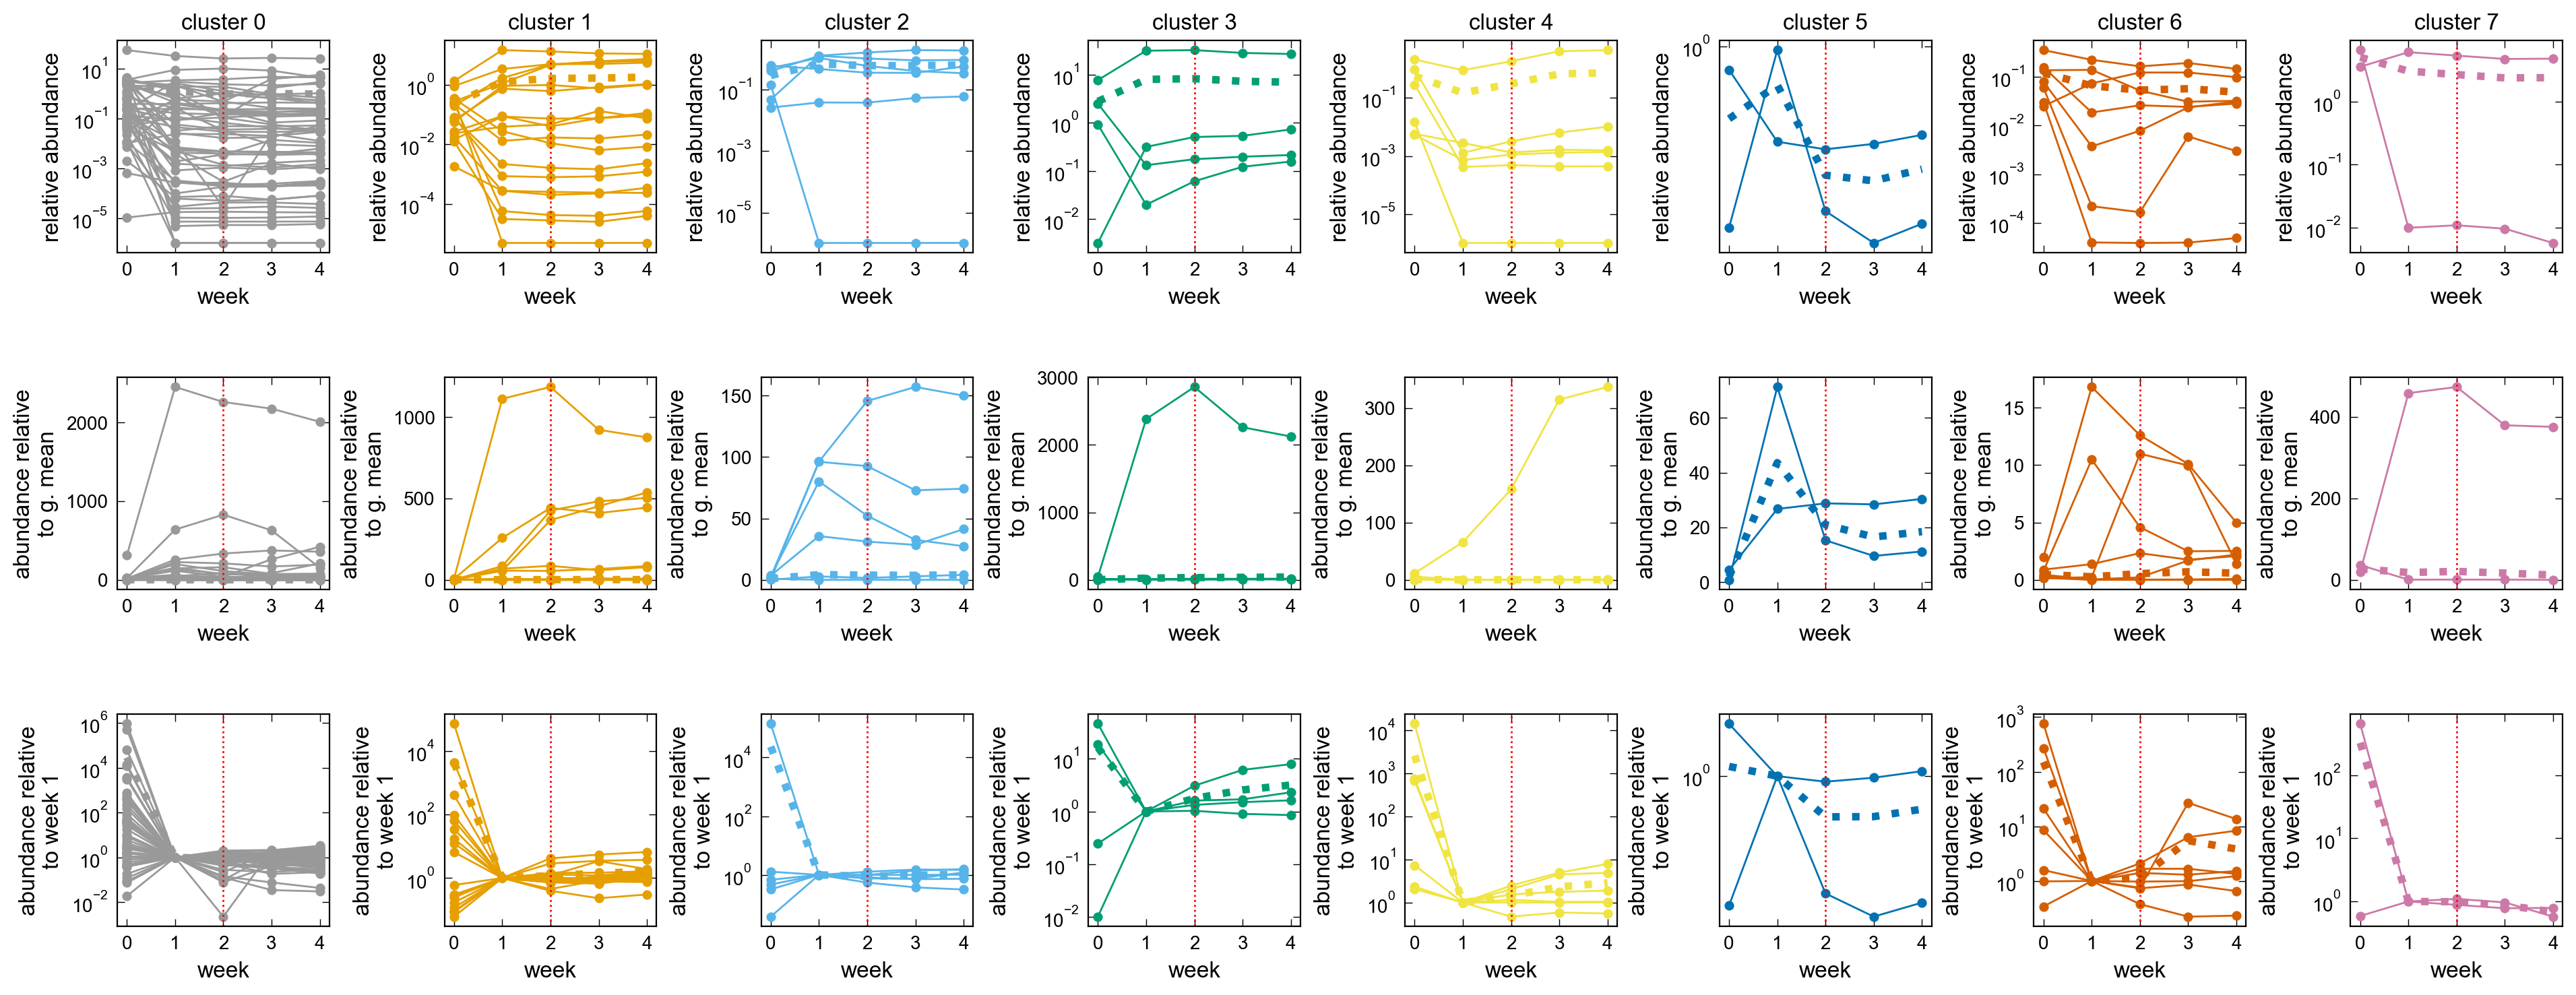

In [34]:
fig, axs = plt.subplots(3, 8, figsize=(19.0, 7.5), sharex = False, constrained_layout=True)

labels = [['day 0', 'week 1'], ['week 1', 'week 2'], ['week 2', 'week 3'], ['week 3', 'week 4']]
clr_var_list = ["day0_clr", "wk1_clr", "wk2_clr", "wk3_clr", "wk4_clr"]
abundance_var_list = ["day0_abundance_batch1", "Batch1_week1", "Batch1_week2", "Batch1_week3", "Batch1_week4"]

data = strain_clr_data.drop('replicate',axis = 1).groupby('strain_id', as_index = False).mean()

for (_, g) in data.groupby('cross_reactivity_cluster'):
    cluster = g['cross_reactivity_cluster'].values[0]
    mean_g = g.drop('strain_id', axis = 1).groupby('cross_reactivity_cluster', as_index = False).mean()
    axs[0, int(cluster)].set_title('cluster '+str(int(cluster)), fontsize = 12) 
    axs[0, int(cluster)].plot(mean_g[abundance_var_list].values.T, color = g['cross_reactivity_cluster'].map(lut).tolist()[0], linewidth = 4.0, linestyle = ':')
    axs[0, int(cluster)].plot(g[abundance_var_list].values.T, marker = 'o', color = g['cross_reactivity_cluster'].map(lut).tolist()[0])
    # axs[0, int(cluster)].scatter(len(additional_wk4_vars)*[4], mean_g[additional_wk4_vars].values.T.ravel(), color = g['cross_reactivity_cluster'].map(lut).tolist()[0], marker = '^', facecolor = 'none')
    # axs[0, int(cluster)].scatter(len(additional_wk2_vars)*[2], mean_g[additional_wk2_vars].values.T.ravel(), color = g['cross_reactivity_cluster'].map(lut).tolist()[0], marker = '^', facecolor = 'none')
    # axs[0, int(cluster)].scatter(len(additional_day0_vars)*[0], mean_g[additional_day0_vars].values.T.ravel(), color = g['cross_reactivity_cluster'].map(lut).tolist()[0], marker = '^', facecolor = 'none')
    axs[0, int(cluster)].semilogy()
    axs[0, int(cluster)].set_ylabel('relative abundance', fontsize = 12)
    
    axs[1, int(cluster)].plot(10**np.mean(g[clr_var_list].values.T, axis = 1), color = g['cross_reactivity_cluster'].map(lut).tolist()[0], linewidth = 4.0, linestyle = ':')
    axs[1, int(cluster)].plot(10**g[clr_var_list].values.T, marker = 'o', color = g['cross_reactivity_cluster'].map(lut).tolist()[0])
    axs[1, int(cluster)].set_ylabel('abundance relative\nto g. mean', fontsize = 12)

    axs[2, int(cluster)].plot(np.mean(g[abundance_var_list].values.T/g[abundance_var_list].values.T[1, :], axis = 1), color = g['cross_reactivity_cluster'].map(lut).tolist()[0], linewidth = 4.0, linestyle = ':')
    axs[2, int(cluster)].plot(g[abundance_var_list].values.T/g[abundance_var_list].values.T[1, :], marker = 'o', color = g['cross_reactivity_cluster'].map(lut).tolist()[0])
    axs[2, int(cluster)].set_ylabel('abundance relative\nto week 1', fontsize = 12)
    axs[2, int(cluster)].semilogy()

for j, ax in enumerate(axs.flat):
    ax.set_xlabel('week', fontsize = 12)
    ax.axvline(x = 2, ls = ':', color = 'red')
        
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)
    ax.set_xticks(np.arange(0,5))

fig.savefig('_figs/fig_rel_abundance_by_cluster_strains'+'.pdf', dpi=300, bbox_inches='tight')

Abundance ratio seems to obscure signals compared to the relative abundance. ruminococcus gnavus in cluster 5 is a known inflammatory bacteria and it's abundance shows a decline.

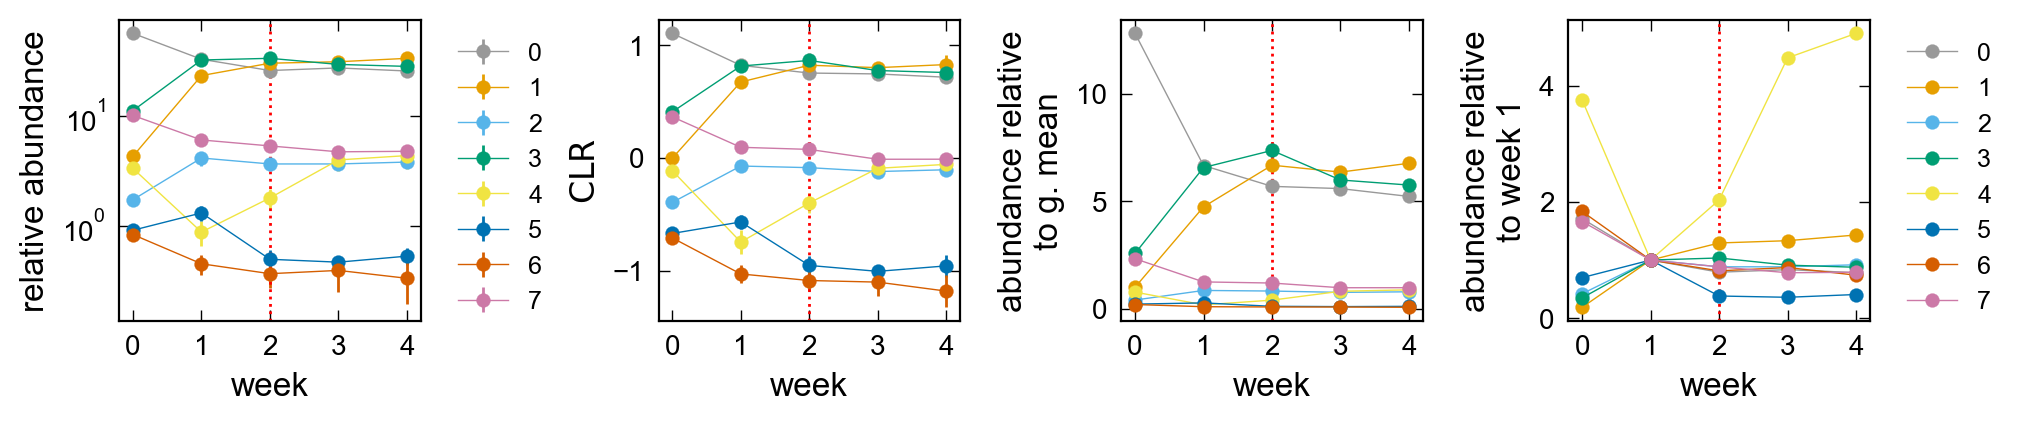

In [35]:
fig, axs = plt.subplots(1, 4, figsize=(10, 2.0), sharex = False, constrained_layout=True)

clr_var_list = ["day0_clr", "wk1_clr", "wk2_clr", "wk3_clr", "wk4_clr"]
abundance_var_list = ["day0_abundance_batch1", "Batch1_week1", "Batch1_week2", "Batch1_week3", "Batch1_week4"]

mean_data = cluster_clr_data.drop('replicate', axis = 1).groupby('cross_reactivity_cluster', as_index = False).mean()
std_data = cluster_clr_data.drop('replicate', axis = 1).groupby('cross_reactivity_cluster', as_index = False).std()

for (_, g) in mean_data.groupby('cross_reactivity_cluster'):
    cluster = g['cross_reactivity_cluster'].values[0]
    error = std_data.loc[std_data.cross_reactivity_cluster == cluster, abundance_var_list].values
    axs[0].errorbar(np.arange(0,5), g[abundance_var_list].values.ravel(), 
                    yerr = error.ravel(), elinewidth = 1.0,linewidth = 0.5,fmt = '-o', color = g['cross_reactivity_cluster'].map(lut).tolist()[0], label = int(cluster))
    axs[0].set_ylabel('relative abundance', fontsize = 12)
    axs[0].legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
    axs[0].semilogy()

    error = std_data.loc[std_data.cross_reactivity_cluster == cluster, clr_var_list].values
    axs[1].errorbar(np.arange(0,5), g[clr_var_list].values.ravel(), 
                    yerr = error.ravel(), elinewidth = 1.0,linewidth = 0.5,fmt = '-o', color = g['cross_reactivity_cluster'].map(lut).tolist()[0], label = int(cluster))
    axs[1].set_ylabel(r'$\text{CLR}$', fontsize = 12)

    error = std_data.loc[std_data.cross_reactivity_cluster == cluster, clr_var_list].values
    axs[2].errorbar(np.arange(0,5), 10**g[clr_var_list].values.ravel(), 
                    elinewidth = 1.0,linewidth = 0.5,fmt = '-o', color = g['cross_reactivity_cluster'].map(lut).tolist()[0], label = int(cluster))
    axs[2].set_ylabel('abundance relative\nto g. mean', fontsize = 12)

    axs[3].errorbar(np.arange(0,5), g[abundance_var_list].values.ravel()/g[abundance_var_list].values.ravel()[1], 
                    elinewidth = 1.0,linewidth = 0.5,fmt = '-o', color = g['cross_reactivity_cluster'].map(lut).tolist()[0], label = int(cluster))
    axs[3].set_ylabel('abundance relative\nto week 1', fontsize = 12)
    axs[3].legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)

for j, ax in enumerate(axs.flat):
    ax.set_xlabel('week', fontsize = 12)
    # ax.axvline(x = 1, ls = ':', color = 'grey')
    # ax.axvline(x = 4, ls = ':', color = 'grey')
    ax.axvline(x = 2, ls = ':', color = 'red')
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)
    ax.set_xticks(np.arange(0,5))

fig.savefig('_figs/fig_rel_abundance_by_cluster_average'+'.pdf', dpi=300, bbox_inches='tight')

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33658/744878949.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.loc[:,'diff'] = np.log10(data[u[1]]/data[u[0]]).values
/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


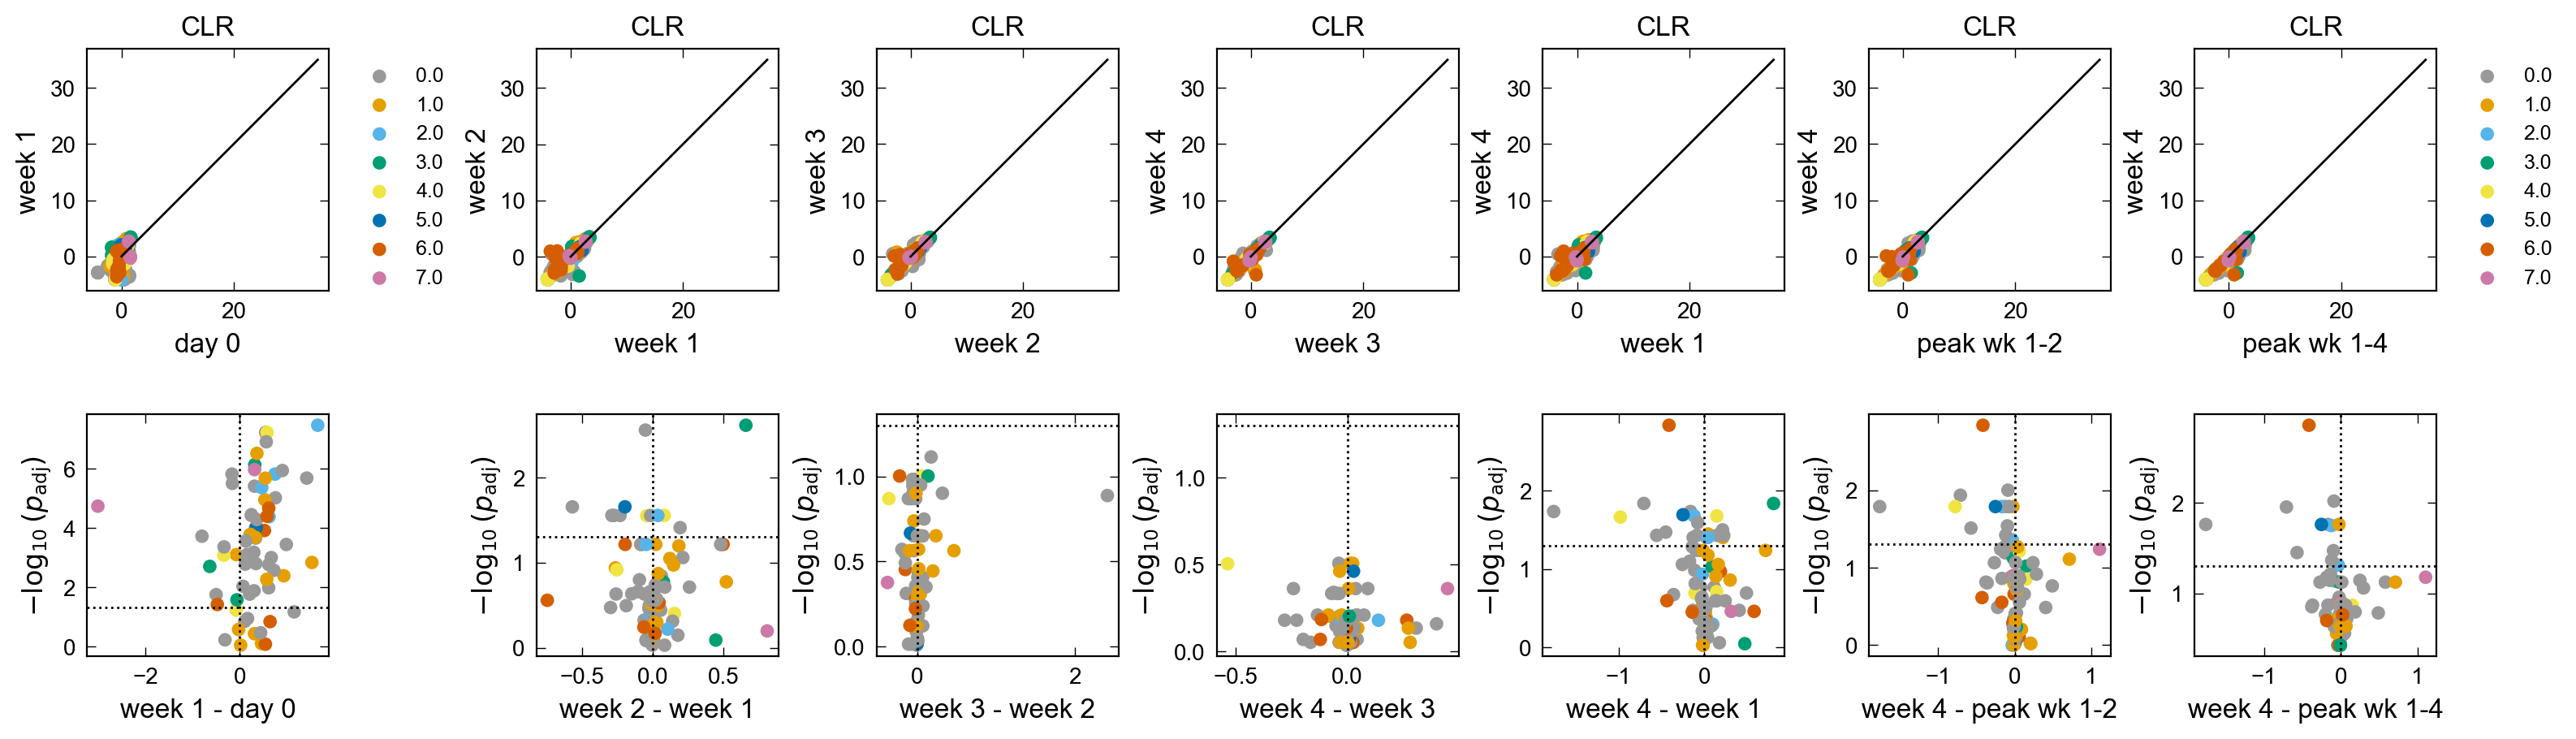

In [36]:
# Plot figures
labels = [['day 0', 'week 1'], ['week 1', 'week 2'], ['week 2', 'week 3'], ['week 3', 'week 4'], ['week 1', 'week 4'],  ['peak wk 1-2', 'week 4'], ['peak wk 1-4', 'week 4']]
var_list = [["day0_clr", "wk1_clr"],
            ["wk1_clr", "wk2_clr"],
            ["wk2_clr", "wk3_clr"],
            ["wk3_clr", "wk4_clr"],
            ["wk1_clr", "wk4_clr"],
            ["peak_1_2_clr", "wk4_clr"],
            ["peak_clr", "wk4_clr"]]

fig, axs = plt.subplots(2, len(var_list), figsize=(2.25*len(var_list), 4.5), sharex = False, constrained_layout=True)

data = strain_clr_data.loc[strain_clr_data.strain_id !='nonimmunogenic_cluster']

for i, u in enumerate(var_list):
    axs[0, i].plot(np.linspace(0,35,10), np.linspace(0,35,10), color = 'black')
    axs[0, i].set_title('CLR', fontsize = 12)
        
    axs[0, i].set_xlabel(labels[i][0], fontsize = 12)
    axs[0, i].set_ylabel(labels[i][1], fontsize = 12)

    # make volcano plots
    data.loc[:,'diff'] = np.log10(data[u[1]]/data[u[0]]).values

    strain_list = np.unique(data.strain_id)
    num_test = len(strain_list)
    fcs, ps, cs = [], [], []

    for strain in strain_list:
        single_data = data.loc[data.strain_id == strain]
        cluster = int(single_data.cross_reactivity_cluster.values[0])
        mean_clr = np.mean(single_data['diff'])
        trel_stat, trel_p_value = ttest_rel(single_data[u[1]], single_data[u[0]])
        fcs.append(mean_clr), ps.append(trel_p_value), cs.append(cluster)
    
    axs[1, i].scatter(np.array(fcs)[~np.isnan(ps)], -np.log10(stats.false_discovery_control(np.array(ps)[~np.isnan(ps)], method='bh')), 
                          color = np.array([lut[c] for c in np.array(cs)[~np.isnan(ps)]]))
        
    axs[1, i].set_xlabel(labels[i][1] +' - '+ labels[i][0], fontsize = 12)
    axs[1, i].set_ylabel(r'$-\log_{10}(p_\text{adj})$', fontsize = 12)
    axs[1, i].axhline(y = -np.log10(p_thresh), color = 'black', ls = ':')
    axs[1, i].axvline(x = 0, color = 'black', ls = ':')
    
    for (_, g) in data.groupby('cross_reactivity_cluster'):
        cluster = g['cross_reactivity_cluster'].values[0]
        axs[0, i].scatter(g[u[0]], g[u[1]], marker = 'o', color = g['cross_reactivity_cluster'].map(lut), label = cluster)
       
for j, ax in enumerate(axs.flat):
    if j == 6 or j == 0:
        ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
        
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)
    
fig.savefig('_figs/wk_clr_in_abundance_strain'+'.pdf', dpi=300, bbox_inches='tight')

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33658/2355951731.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.loc[:,'diff'] = np.log10(data[u[1]]/data[u[0]]).values
/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33658/2355951731.py:49: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)


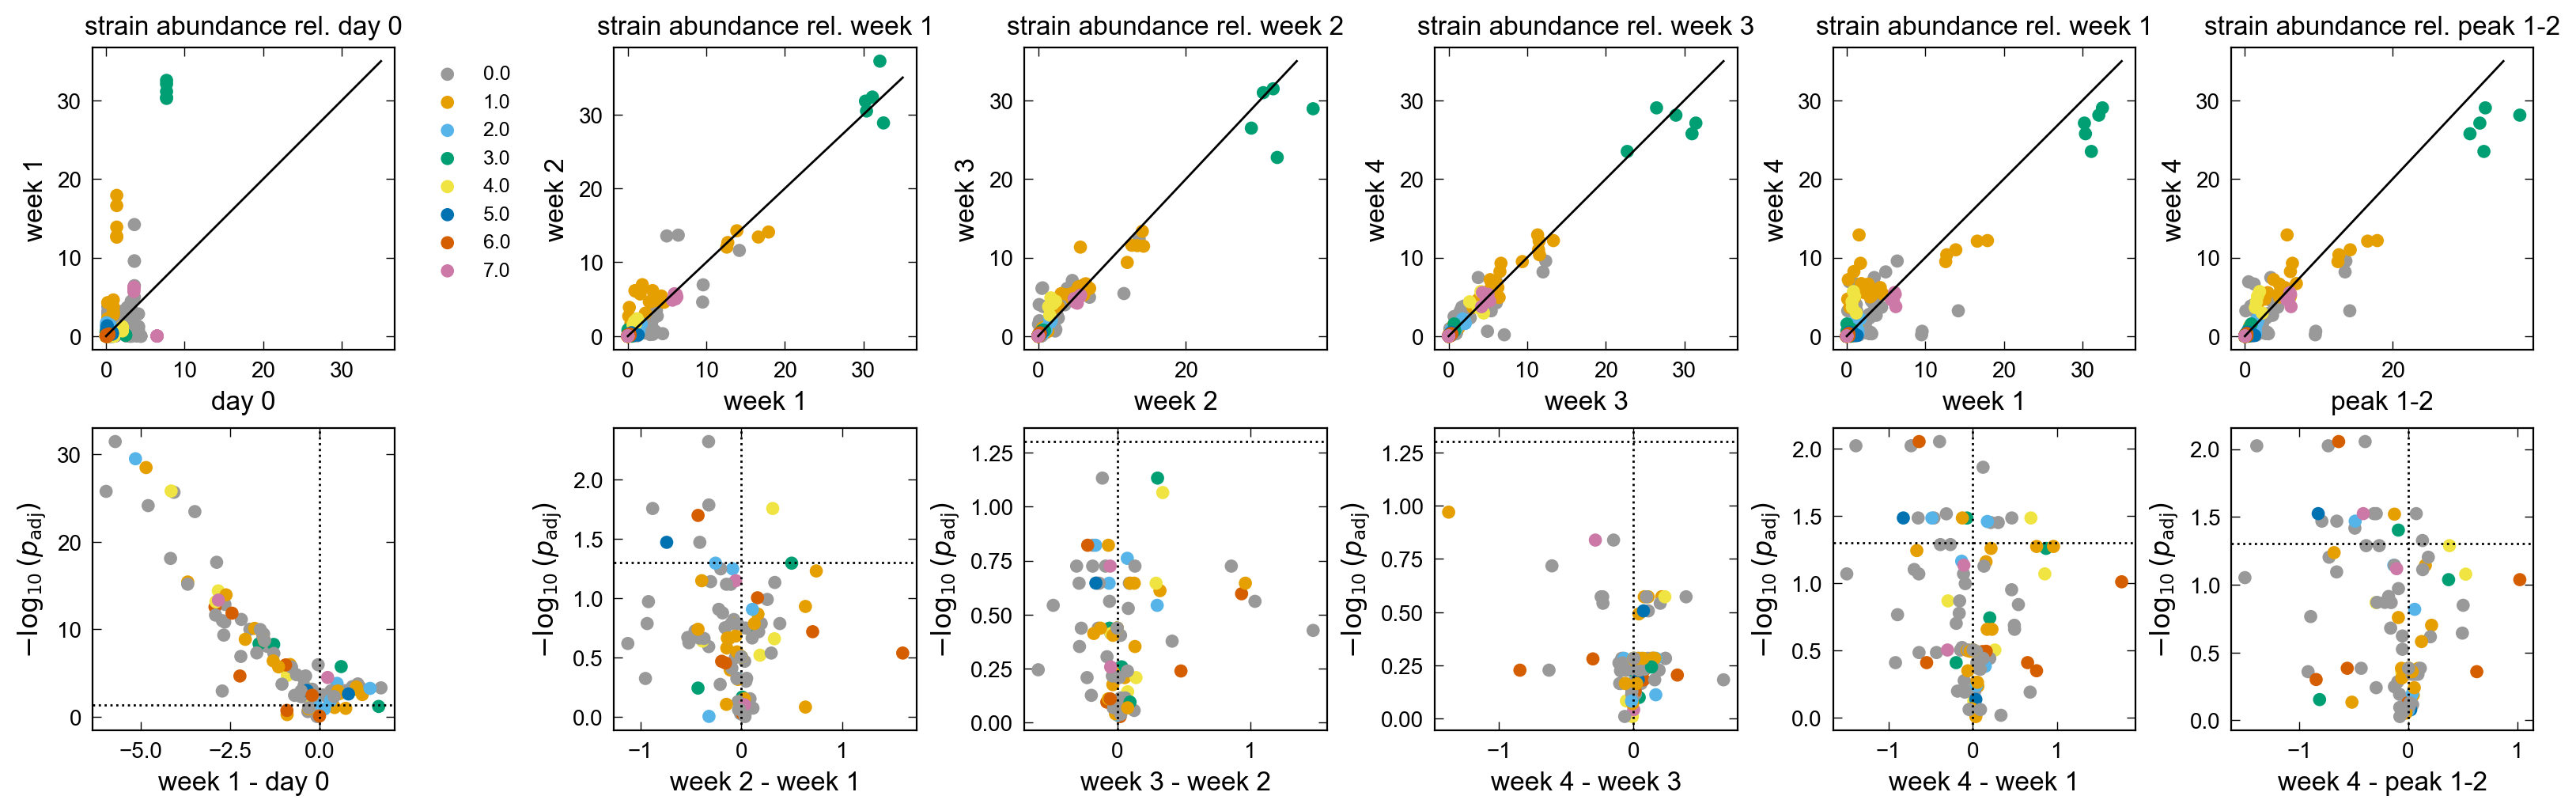

In [37]:
# Plot figures
fig, axs = plt.subplots(2, 6, figsize=(16.0, 5.0), sharex = False, constrained_layout=True)

labels = [['day 0', 'week 1'], ['week 1', 'week 2'], ['week 2', 'week 3'], ['week 3', 'week 4'], ['week 1', 'week 4'], ['peak 1-2', 'week 4']]
var_list = [["day0_abundance_batch1", "Batch1_week1"],
            ["Batch1_week1", "Batch1_week2"],
            ["Batch1_week2", "Batch1_week3"],
            ["Batch1_week3", "Batch1_week4"],
            ["Batch1_week1", "Batch1_week4"],
            ["Batch1_peak_1_2", "Batch1_week4"]]

data = strain_clr_data.loc[strain_clr_data.strain_id !='nonimmunogenic_cluster']

for i, u in enumerate(var_list):
    axs[0, i].plot(np.linspace(0,35,10), np.linspace(0,35,10), color = 'black')
    axs[0, i].set_title('strain abundance rel. '+labels[i][0], fontsize = 12)
        
    axs[0, i].set_xlabel(labels[i][0], fontsize = 12)
    axs[0, i].set_ylabel(labels[i][1], fontsize = 12)

    # make volcano plots
    data.loc[:,'diff'] = np.log10(data[u[1]]/data[u[0]]).values

    strain_list = np.unique(data.strain_id)
    num_test = len(strain_list)
    fcs, ps, cs = [], [], []

    for strain in strain_list:
        single_data = data.loc[data.strain_id == strain]
        cluster = int(single_data.cross_reactivity_cluster.values[0])
        mean_fc = np.mean(single_data['diff'])
        trel_stat, trel_p_value = ttest_rel(single_data[u[1]], single_data[u[0]])
        fcs.append(mean_fc), ps.append(trel_p_value), cs.append(cluster)
    
    axs[1, i].scatter(np.array(fcs)[~np.isnan(ps)], -np.log10(stats.false_discovery_control(np.array(ps)[~np.isnan(ps)], method='bh')), 
                          color = np.array([lut[c] for c in np.array(cs)[~np.isnan(ps)]]))
        
    axs[1, i].set_xlabel(labels[i][1] +' - '+ labels[i][0], fontsize = 12)
    axs[1, i].set_ylabel(r'$-\log_{10}(p_\text{adj})$', fontsize = 12)
    axs[1, i].axhline(y = -np.log10(p_thresh), color = 'black', ls = ':')
    axs[1, i].axvline(x = 0, color = 'black', ls = ':')
    
    for (_, g) in data.groupby('cross_reactivity_cluster'):
        cluster = g['cross_reactivity_cluster'].values[0]
        axs[0, i].scatter(g[u[0]], g[u[1]], marker = 'o', color = g['cross_reactivity_cluster'].map(lut), label = cluster)
       
for j, ax in enumerate(axs.flat):
    if j == 6 or j == 0:
        ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
        
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/wk_fc_in_abundance_strain'+'.pdf', dpi=300, bbox_inches='tight')

Remake these as volcano plots: log10(FC) vs. -log10(multiple-testing adjusted p-values (maybe Benjamini-Hochberg))

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33658/2463450310.py:51: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)


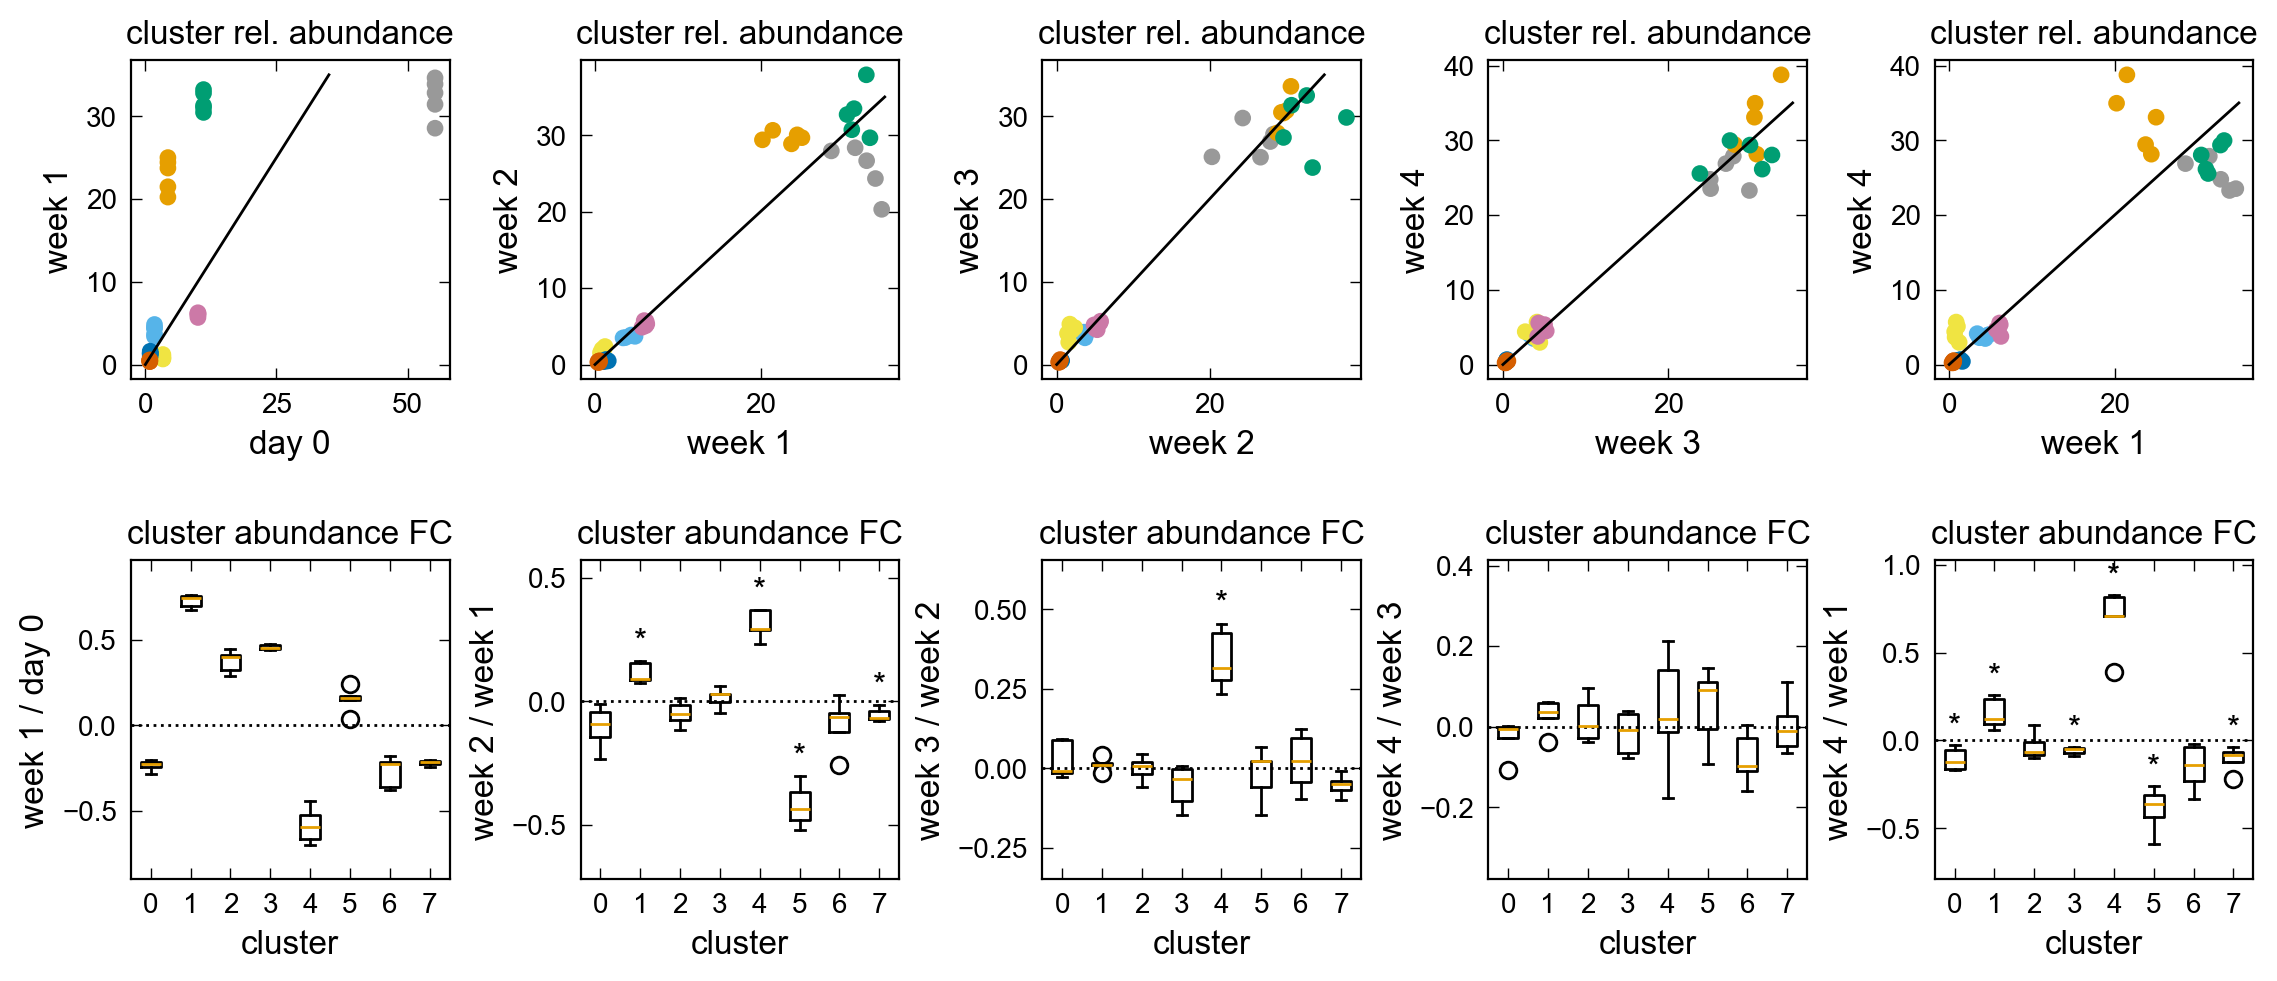

In [38]:
# Plot figures
labels = [['day 0', 'week 1'], ['week 1', 'week 2'], ['week 2', 'week 3'], ['week 3', 'week 4'], ['week 1', 'week 4']]
var_list = [["day0_abundance_batch1", "Batch1_week1"],
            ["Batch1_week1", "Batch1_week2"],
            ["Batch1_week2", "Batch1_week3"],
            ["Batch1_week3", "Batch1_week4"],
            ["Batch1_week1", "Batch1_week4"]]

data = cluster_clr_data
cluster_num = len(np.unique(data.cross_reactivity_cluster))

fig, axs = plt.subplots(2, len(labels), figsize=(2.25*len(labels), 5.0), sharey = False, constrained_layout=True)

for i, u in enumerate(var_list):
    #print(labels[i])
    axs[0, i].plot(np.linspace(0,35,10), np.linspace(0,35,10), color = 'black')
    axs[0, i].set_xlabel(labels[i][0], fontsize = 12)
    axs[0, i].set_ylabel(labels[i][1], fontsize = 12)
    data.loc[:,'diff'] = np.log10(data[u[1]]/data[u[0]]).values
    
    axs[1, i].boxplot([g['diff'].values for (_, g) in data.groupby('cross_reactivity_cluster')], 
                      tick_labels=[str(int(i)) for i in np.unique(data.cross_reactivity_cluster)])
    axs[1, i].axhline(y = 0.0, color = 'black', ls = ':')
    axs[1, i].set_ylim(np.amin(data['diff']) - 0.2, np.max(data['diff']) + 0.2)

    axs[1, i].set_ylabel(labels[i][1] +' / '+ labels[i][0], fontsize = 12)
    axs[1, i].set_xlabel('cluster', fontsize = 12)
    
    ps = []
    for (_, g) in data.groupby('cross_reactivity_cluster'):
        cluster = g['cross_reactivity_cluster'].values[0]
        axs[0, i].scatter(g[u[0]], g[u[1]], marker = 'o', color = g['cross_reactivity_cluster'].map(lut), label = cluster)
        
        if i >= 1:
            mask = ~np.isnan(g[u[0]]) & ~np.isnan(g[u[1]])
            trel_stat, trel_p_value = ttest_rel(g[u[1]][mask], g[u[0]][mask])

            ps.append(trel_p_value)

    ps_adj = stats.false_discovery_control(ps)
    for k,(_, g) in enumerate(data.groupby('cross_reactivity_cluster')):
        cluster = g['cross_reactivity_cluster'].values[0]
        if i >= 1:
            axs[1, i].text(cluster + 1, np.amax(g['diff']) + 0.01, '*' if ps_adj[k] <= p_thresh else '', ha='center', va='bottom', color='black', fontsize = 12)
            
    axs[0,i].set_title('cluster rel. abundance', fontsize = 12)
    axs[1,i].set_title('cluster abundance FC', fontsize = 12)
    
for j, ax in enumerate(axs.flat):
    if j == 5:
        ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
        
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_test_sig_abundance_ratio_over_time'+'.pdf', dpi=300, bbox_inches='tight')

Are the movements between cluster 0 and clusters 1 and 4 correlated?

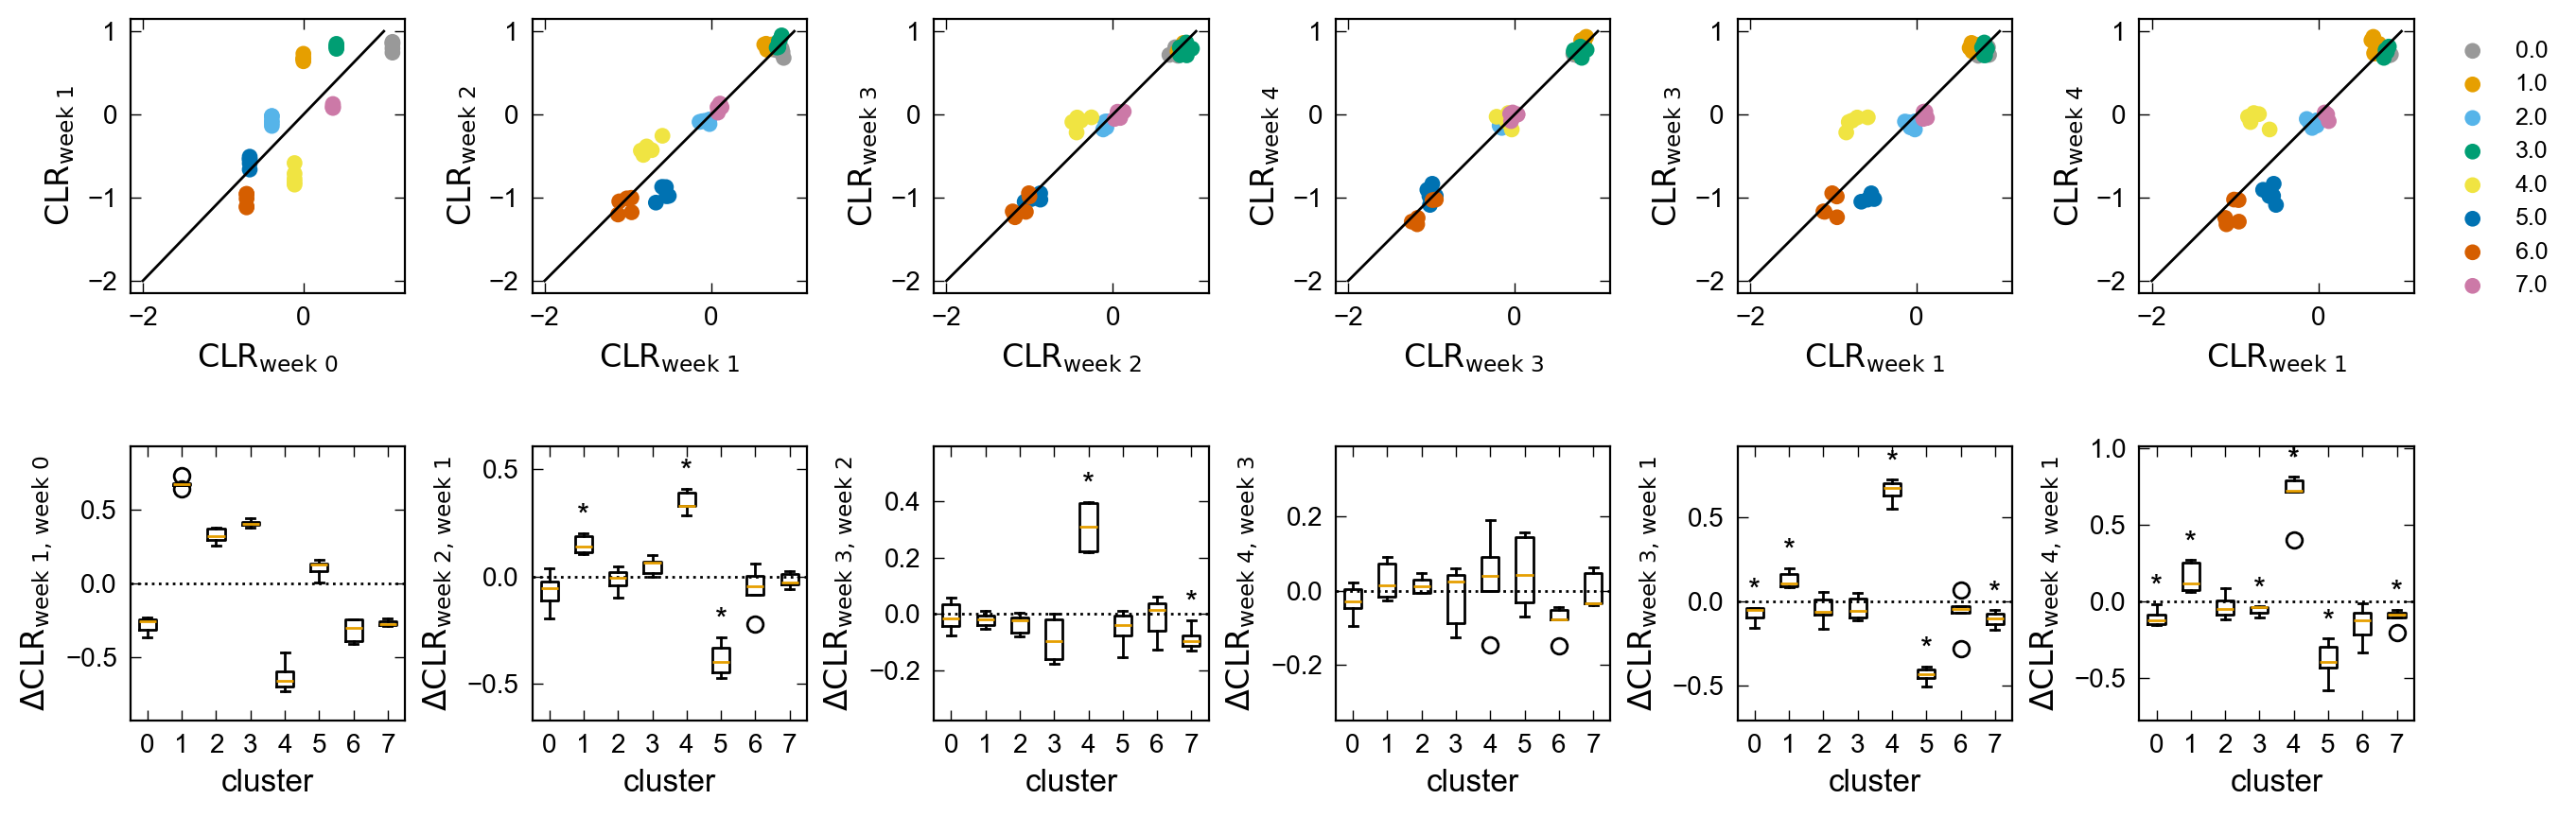

In [39]:
# Plot figures

labels = [['week 0', 'week 1'], ['week 1', 'week 2'], ['week 2', 'week 3'], ['week 3', 'week 4'], ['week 1', 'week 3'], ['week 1', 'week 4']]
var_list = [["day0_clr", "wk1_clr"],
            ["wk1_clr", "wk2_clr"],
            ["wk2_clr", "wk3_clr"],
            ["wk3_clr", "wk4_clr"],
            ["wk1_clr", "wk3_clr"],
            ["wk1_clr", "wk4_clr"]]

fig, axs = plt.subplots(2, len(labels), figsize=(2.25*len(labels), 4.5), sharex = False, constrained_layout=True)

data = cluster_clr_data
cluster_num = len(np.unique(data.cross_reactivity_cluster))

for i, u in enumerate(var_list):
    # print(labels[i])
    axs[0, i].plot(np.linspace(-2,1,10), np.linspace(-2,1,10), color = 'black')
    axs[0, i].set_xlabel(r'$\text{CLR}_\text{'+labels[i][0]+r'}$', fontsize = 12)
    axs[0, i].set_ylabel(r'$\text{CLR}_\text{'+labels[i][1]+r'}$', fontsize = 12)
    data.loc[:,'diff'] = (data[u[1]] - data[u[0]]).values
    
    axs[1, i].boxplot([g['diff'].values for (_, g) in data.groupby('cross_reactivity_cluster')], 
                      tick_labels=[str(int(i)) for i in np.unique(data.cross_reactivity_cluster)])
    axs[1, i].axhline(y = 0.0, color = 'black', ls = ':')
    axs[1, i].set_ylim(np.amin(data['diff']) - 0.2, np.max(data['diff']) + 0.2)
    
    axs[1, i].set_ylabel(r'$\Delta\text{CLR}_\text{'+labels[i][1] +', '+ labels[i][0]+r'}$', fontsize = 12)
    axs[1, i].set_ylim(np.amin(data['diff']) - 0.2, np.max(data['diff']) + 0.2)
    axs[1, i].set_xlabel('cluster', fontsize = 12)
    
    ps = []
    for (_, g) in data.groupby('cross_reactivity_cluster'):
        cluster = g['cross_reactivity_cluster'].values[0]
        axs[0, i].scatter(g[u[0]], g[u[1]], marker = 'o', color = g['cross_reactivity_cluster'].map(lut), label = cluster)
        
        if i >= 1:
            mask = ~np.isnan(g[u[0]]) & ~np.isnan(g[u[1]])
            trel_stat, trel_p_value = ttest_rel(g[u[1]][mask], g[u[0]][mask])

            ps.append(trel_p_value)

    ps_adj = stats.false_discovery_control(ps)
    for k,(_, g) in enumerate(data.groupby('cross_reactivity_cluster')):
        cluster = g['cross_reactivity_cluster'].values[0]
        if i >= 1:
            axs[1, i].text(cluster + 1, np.amax(g['diff']) + 0.005, '*' if ps_adj[k] <= p_thresh else '', ha='center', va='bottom', color='black', fontsize = 12)
    
for j, ax in enumerate(axs.flat):
    if j == 5:
        ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
        
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_test_sig_clr_over_time'+'.pdf', dpi=300, bbox_inches='tight')

Rework to use both relative abundance and CLR; compare wk4 - wk1  and wk4 - peak

Two-Level P-value: 0.1490
Two-Level P-value: 0.0001
Two-Level P-value: 0.0001
Two-Level P-value: 0.0001


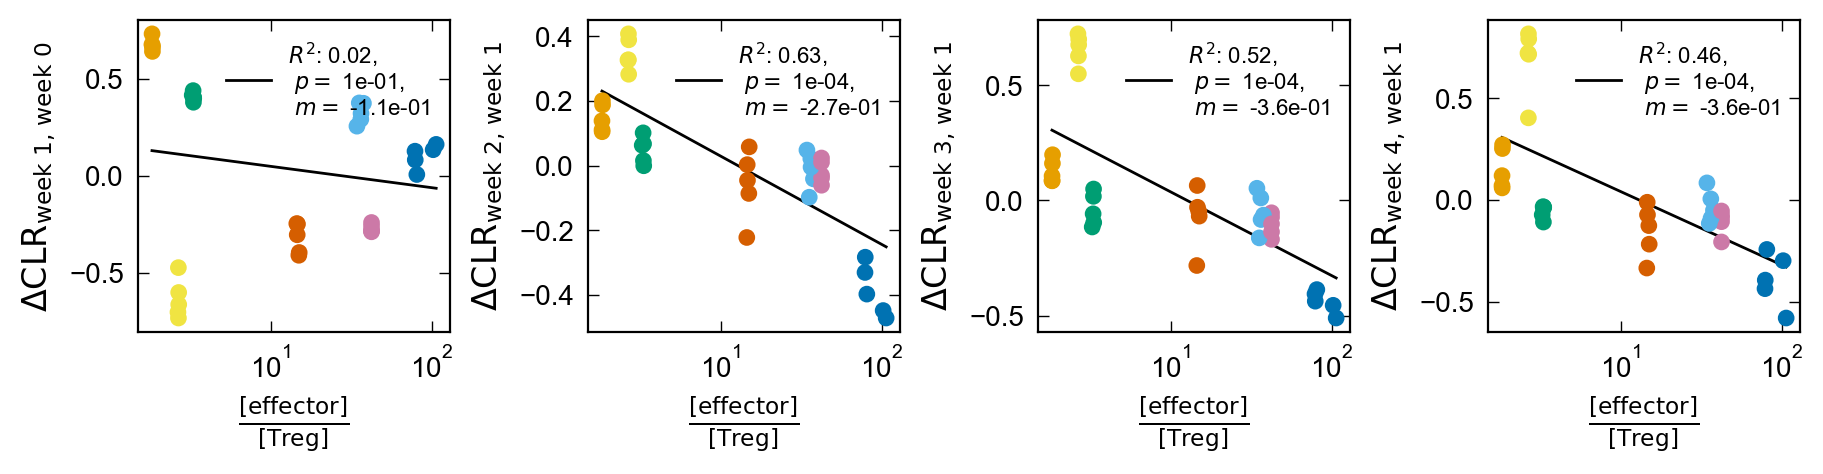

In [40]:
# Plot figures
labels = [['week 1', 'week 0'], ['week 2', 'week 1'], ['week 3', 'week 1'], ['week 4', 'week 1']]

var_list = [["day0_clr", "wk1_clr"],
            ["wk1_clr", "wk2_clr"],
            ["wk1_clr", "wk3_clr"],
            ["wk1_clr", "wk4_clr"]]

fig, axs = plt.subplots(1, len(labels), figsize=(2.25*len(labels), 2.5), sharex = False, constrained_layout=True)

hybridoma_abundance_fig_data = hybridoma_cluster_data.groupby(['cross_reactivity_cluster', 'replicate'], as_index = False).sum().drop('Batch1_week1', axis = 1)
data = cluster_clr_data.loc[cluster_clr_data.cross_reactivity_cluster != 0].merge(hybridoma_abundance_fig_data, 
                                                                                  how = 'left', on = ['cross_reactivity_cluster', 'replicate'], validate = 'one_to_one').replace([np.inf, -np.inf, np.nan], 0)
data.loc[:, 'eff_Treg_ratio'] = (data['weighted_total_effector']/data['weighted_total_Treg']).replace([np.inf, -np.inf], np.nan)

def get_slope(x, y):
    return LinearRegression().fit(x.reshape(-1, 1), y).coef_[0]

for i, var in enumerate(var_list):

    # 1. plot clusters
    x_data = data['eff_Treg_ratio']
    y_data = data[var[1]] - data[var[0]] #np.log10(data[var[1]]/data[var[0]])
    axs[i].scatter(x_data, y_data, s = 25, color = data['cross_reactivity_cluster'].map(lut), zorder = 2)
    
    obs_slope, b, r_value, p_value, std_err = scipy.stats.linregress(np.log10(x_data), y_data)

    # 2. Permutation Loop
    
    n_perms = 10000
    perm_results = []
    cluster_to_x_values = {c: data[data['cross_reactivity_cluster'] == c]['eff_Treg_ratio'].values for c in data['cross_reactivity_cluster'].unique()}
    unique_clusters = list(cluster_to_x_values.keys())

    for _ in range(n_perms):
        # STEP 1 & 2: Shuffle cluster assignments (Across-cluster)
        # We decide which cluster's data set each original cluster will "borrow"
        shuffled_labels = np.random.permutation(unique_clusters)
        cluster_map = dict(zip(unique_clusters, shuffled_labels))
        
        # STEP 3: Rebuild X by pulling the assigned set and shuffling WITHIN it
        x_perm_list = []
        for cluster_name in unique_clusters:
            source_cluster = cluster_map[cluster_name]
            data_set = cluster_to_x_values[source_cluster]
            
            # Shuffle the values within this specific assigned set
            x_perm_list.append(np.random.permutation(data_set))
        
        # Flatten back to a single array
        x_perm = np.concatenate(x_perm_list)
        perm_results.append(get_slope(np.log10(x_perm), y_data.values))
    
    p_val = (np.sum(np.abs(perm_results) >= np.abs(obs_slope)) + 1)/(n_perms + 1)
    print(f"Two-Level P-value: {p_val:.4f}")

    axs[i].plot(np.unique(x_data), 
            obs_slope*np.unique(np.log10(x_data)) + b, 
                  color = 'black',
                  zorder = 0,
                  linewidth = 1.0,
            label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)) + f',\n $p =$ {p_val:.0e}'+ f',\n $m =$ {obs_slope:.1e}')

    # Format figure
    axs[i].set_xlabel(r'$\frac{[\text{effector}]}{[\text{Treg}]}$', fontsize = 12)
    axs[i].set_ylabel(r'$\Delta\text{CLR}_\text{'+labels[i][0] +', '+ labels[i][1]+r'}$', fontsize = 12)
    axs[i].legend(fontsize=8)
    #axs[i].set_xlim(1,100)
    axs[i].semilogx()

    axs[i].set_box_aspect(1)
    axs[i].minorticks_off()
    axs[i].tick_params(axis='both', which='major', labelsize=10)
    axs[i].xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_robust_CLR_v_eff_Treg_ratio'+'.pdf', dpi=300, bbox_inches='tight')

Two-Level P-value: 0.0001
Two-Level P-value: 0.0001
Two-Level P-value: 0.0001
Two-Level P-value: 0.0001
Two-Level P-value: 0.0001
Two-Level P-value: 0.0001
Two-Level P-value: 0.0001


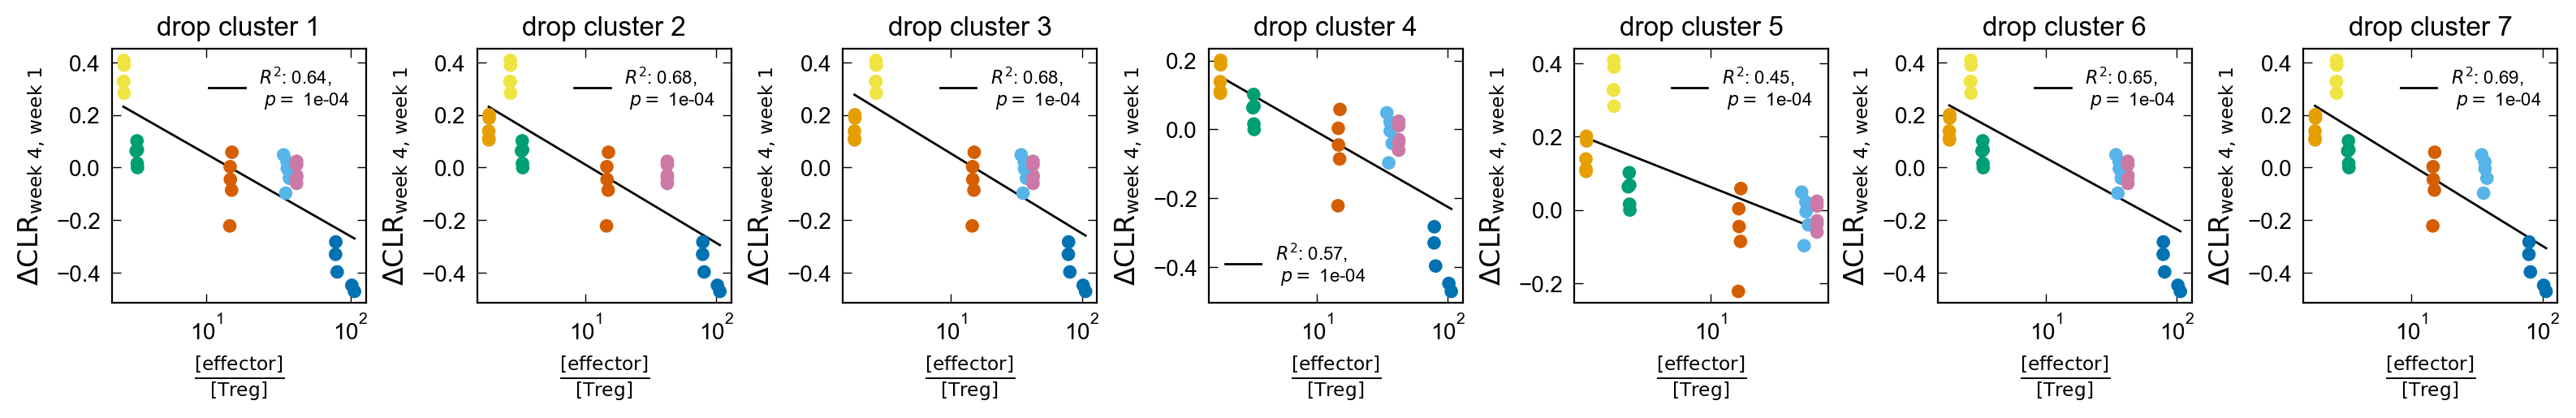

In [41]:
# Do cluster drop-outs for robustness
hybridoma_abundance_fig_data = hybridoma_cluster_data.groupby(['cross_reactivity_cluster', 'replicate'], as_index = False).sum().drop('Batch1_week1', axis = 1)
data = cluster_clr_data.loc[cluster_clr_data.cross_reactivity_cluster != 0].merge(hybridoma_abundance_fig_data, 
                                                                                  how = 'left', on = ['cross_reactivity_cluster', 'replicate'], validate = 'one_to_one').replace([np.inf, -np.inf, np.nan], 0)
data.loc[:, 'eff_Treg_ratio'] = (data['weighted_total_effector']/data['weighted_total_Treg']).replace([np.inf, -np.inf], np.nan)
cluster_list = np.unique(data.cross_reactivity_cluster)
fig, axs = plt.subplots(1, len(cluster_list), figsize=(2.25*len(cluster_list), 2.5), sharex = False, constrained_layout=True)

for i, c in enumerate(cluster_list):
    dropout = data.loc[data.cross_reactivity_cluster != c]
    # plot clusters
    x_data = dropout['eff_Treg_ratio']
    y_data =  dropout['wk2_clr'] - dropout['wk1_clr'] #wk2_clrnp.log10(dropout['Batch1_week2']/dropout['Batch1_week1'])
    axs[i].scatter(x_data, y_data, s = 25, color = dropout['cross_reactivity_cluster'].map(lut), zorder = 2)
    
    obs_slope, b, r_value, p_value, std_err = scipy.stats.linregress(np.log10(x_data), y_data)

    # 2. Permutation Loop
    
    n_perms = 10000
    perm_results = []
    cluster_to_x_values = {c: dropout[dropout['cross_reactivity_cluster'] == c]['eff_Treg_ratio'].values for c in dropout['cross_reactivity_cluster'].unique()}
    unique_clusters = list(cluster_to_x_values.keys())

    for _ in range(n_perms):
        # STEP 1 & 2: Shuffle cluster assignments (Across-cluster)
        # We decide which cluster's data set each original cluster will "borrow"
        shuffled_labels = np.random.permutation(unique_clusters)
        cluster_map = dict(zip(unique_clusters, shuffled_labels))
        
        # STEP 3: Rebuild X by pulling the assigned set and shuffling WITHIN it
        x_perm_list = []
        for cluster_name in unique_clusters:
            source_cluster = cluster_map[cluster_name]
            data_set = cluster_to_x_values[source_cluster]
            
            # Shuffle the values within this specific assigned set
            x_perm_list.append(np.random.permutation(data_set))
        
        # Flatten back to a single array
        x_perm = np.concatenate(x_perm_list)
        perm_results.append(get_slope(np.log10(x_perm), y_data.values))
    
    p_val = (np.sum(np.abs(perm_results) >= np.abs(obs_slope)) + 1)/(n_perms + 1)
    print(f"Two-Level P-value: {p_val:.4f}")

    axs[i].plot(np.unique(x_data), 
            obs_slope*np.unique(np.log10(x_data)) + b, 
                  color = 'black',
                  zorder = 0,
                  linewidth = 1.0,
            label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)) + f',\n $p =$ {p_val:.0e}')

    # Format figure
    axs[i].set_xlabel(r'$\frac{[\text{effector}]}{[\text{Treg}]}$', fontsize = 12)
    axs[i].set_ylabel(r'$\Delta\text{CLR}_\text{week 4, week 1}$', fontsize = 12)
    axs[i].set_title('drop cluster '+str(int(c)), fontsize = 12)
    axs[i].legend(fontsize=8)
    # axs[i].set_xlim(1,100)
    axs[i].semilogx()
        
    axs[i].set_box_aspect(1)
    axs[i].minorticks_off()
    axs[i].tick_params(axis='both', which='major', labelsize=10)
    axs[i].xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_cluster_dropout_FC_v_eff_Treg_ratio'+'.pdf', dpi=300, bbox_inches='tight')

Two-Level P-value: 0.0001
Two-Level P-value: 0.0001
Two-Level P-value: 0.0001
Two-Level P-value: 0.0001
Two-Level P-value: 0.0001


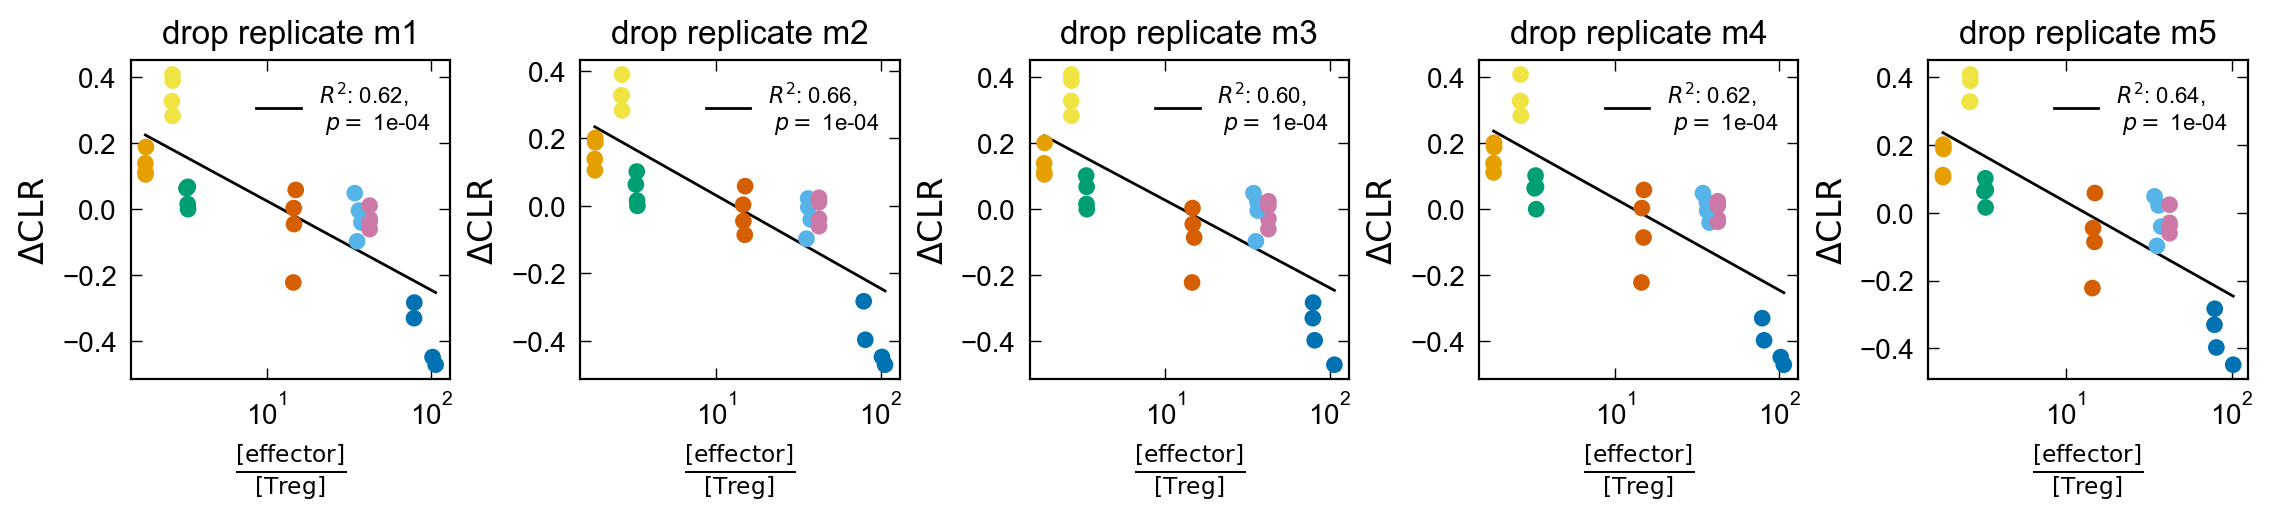

In [42]:
# Do replicate drop-outs for robustness
hybridoma_abundance_fig_data = hybridoma_cluster_data.groupby(['cross_reactivity_cluster', 'replicate'], as_index = False).sum().drop('Batch1_week1', axis = 1)
data = cluster_clr_data.loc[cluster_clr_data.cross_reactivity_cluster != 0].merge(hybridoma_abundance_fig_data, 
                                                                                  how = 'left', on = ['cross_reactivity_cluster', 'replicate'], validate = 'one_to_one').replace([np.inf, -np.inf, np.nan], 0)
data.loc[:, 'eff_Treg_ratio'] = (data['weighted_total_effector']/data['weighted_total_Treg']).replace([np.inf, -np.inf], np.nan)
replicate_list = np.unique(data.replicate)
fig, axs = plt.subplots(1, len(replicate_list), figsize=(2.25*len(replicate_list), 2.5), sharex = False, constrained_layout=True)

for i, c in enumerate(replicate_list):
    dropout = data.loc[data.replicate != c]
    # plot clusters
    x_data = dropout['eff_Treg_ratio']
    y_data = dropout['wk2_clr'] - dropout['wk1_clr'] #np.log10(dropout['Batch1_week2']/dropout['Batch1_week1'])
    axs[i].scatter(x_data, y_data, s = 25, color = dropout['cross_reactivity_cluster'].map(lut), zorder = 2)
    
    obs_slope, b, r_value, p_value, std_err = scipy.stats.linregress(np.log10(x_data), y_data)

    # 2. Permutation Loop
    n_perms = 10000
    perm_results = []
    cluster_to_x_values = {c: dropout[dropout['cross_reactivity_cluster'] == c]['eff_Treg_ratio'].values for c in dropout['cross_reactivity_cluster'].unique()}
    unique_clusters = list(cluster_to_x_values.keys())

    for _ in range(n_perms):
        # STEP 1 & 2: Shuffle cluster assignments (Across-cluster)
        # We decide which cluster's data set each original cluster will "borrow"
        shuffled_labels = np.random.permutation(unique_clusters)
        cluster_map = dict(zip(unique_clusters, shuffled_labels))
        
        # STEP 3: Rebuild X by pulling the assigned set and shuffling WITHIN it
        x_perm_list = []
        for cluster_name in unique_clusters:
            source_cluster = cluster_map[cluster_name]
            data_set = cluster_to_x_values[source_cluster]
            
            # Shuffle the values within this specific assigned set
            x_perm_list.append(np.random.permutation(data_set))
        
        # Flatten back to a single array
        x_perm = np.concatenate(x_perm_list)
        perm_results.append(get_slope(np.log10(x_perm), y_data.values))
    
    p_val = (np.sum(np.abs(perm_results) >= np.abs(obs_slope)) + 1)/(n_perms + 1)
    print(f"Two-Level P-value: {p_val:.4f}")

    axs[i].plot(np.unique(x_data), 
            obs_slope*np.unique(np.log10(x_data)) + b, 
                  color = 'black',
                  zorder = 0,
                  linewidth = 1.0,
            label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)) + f',\n $p =$ {p_val:.0e}')


    # Format figure
    axs[i].set_xlabel(r'$\frac{[\text{effector}]}{[\text{Treg}]}$', fontsize = 12)
    axs[i].set_ylabel(r'$\Delta\text{CLR}$', fontsize = 12)
    axs[i].set_title('drop replicate '+ c, fontsize = 12)
    axs[i].legend(fontsize=8)
    # axs[i].set_xlim(1,100)
    axs[i].semilogx()
        
    axs[i].set_box_aspect(1)
    axs[i].minorticks_off()
    axs[i].tick_params(axis='both', which='major', labelsize=10)
    axs[i].xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_replicate_dropout_FC_v_eff_Treg_ratio'+'.pdf', dpi=300, bbox_inches='tight')

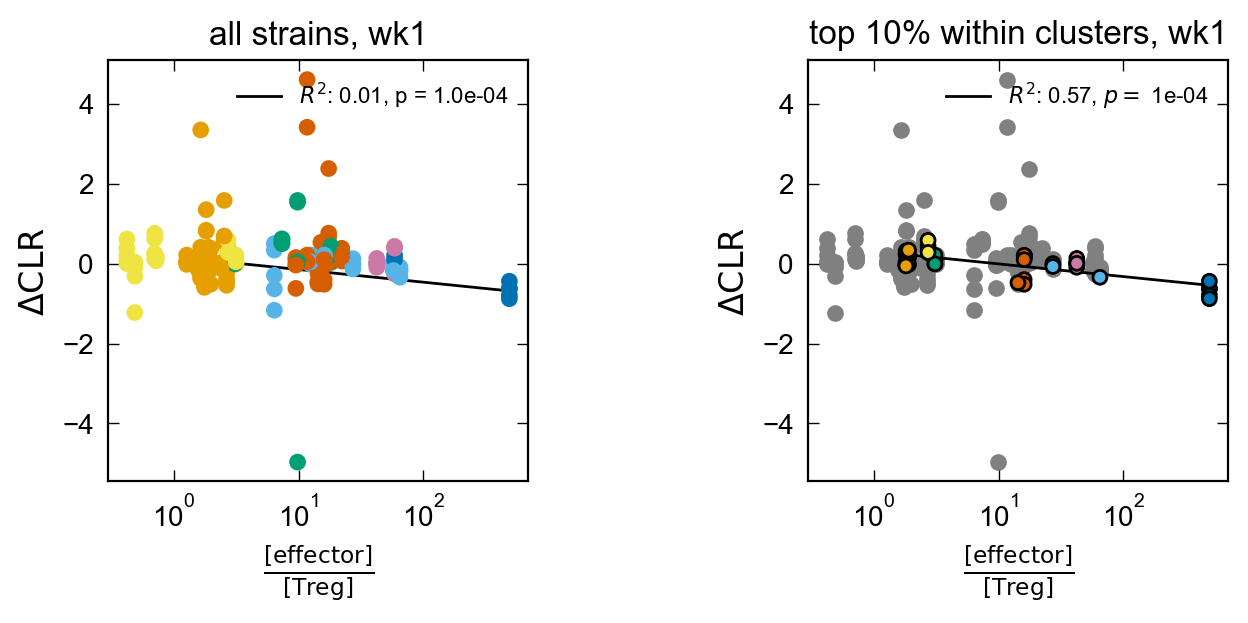

In [43]:
# Plot figures
fig, axs = plt.subplots(1, 2, figsize=(7, 3.0), sharex = False, constrained_layout=True)

hybridoma_abundance_fig_data = hybridoma_cluster_data[['replicate', 'strain_id','total_effector', 'total_Treg', 'mean_sigma']]
for_fig = strain_clr_data.loc[strain_clr_data.cross_reactivity_cluster != 0].merge(hybridoma_abundance_fig_data, 
                                                                                  how = 'left', on = ['strain_id', 'replicate'], validate = 'one_to_one').replace([np.inf, -np.inf, np.nan], 0)
for_fig.loc[:, 'eff_Treg_ratio'] = (for_fig['total_effector']/for_fig['total_Treg']).replace([np.inf, -np.inf], np.nan)
for_fig.loc[:, 'log_fc'] =  np.log10(for_fig['Batch1_week2']/for_fig['Batch1_week1'])
for_fig.loc[:, 'del_clr'] =  for_fig['wk2_clr'] - for_fig['wk1_clr']
for_fig.loc[:, 'cluster_quartile'] = for_fig.groupby(['cross_reactivity_cluster','replicate'])['wk1_clr'].transform(lambda x: pd.qcut(x, q=10, labels=False, duplicates='drop'))
for_fig.loc[:, 'strain_quartile'] = for_fig.groupby('replicate')['wk1_clr'].transform(lambda x: pd.qcut(x, q=10, labels=False, duplicates='drop'))
for_fig.loc[:, 'del_clr_std'] = for_fig.groupby('strain_id')['del_clr'].transform(lambda x: np.std(x))
for_fig.loc[:, 'cluster_rank'] = for_fig.groupby(['cross_reactivity_cluster','replicate'])['wk1_clr'].rank(ascending=False)
for_fig.loc[:, 'cluster_max'] = for_fig.groupby(['cross_reactivity_cluster','replicate'])['Batch1_week1'].transform(lambda x: np.amax(x))

# Fig a: Effect of immunity is undetectable on the least abundant strains within each cluster
mask = for_fig['cluster_quartile'] >= 0
x_data = for_fig['eff_Treg_ratio']
y_data = for_fig['del_clr'] #.replace([np.inf, -np.inf, np.nan], 1)
axs[0].scatter(x_data[mask], y_data[mask], s = 25, color = for_fig['cross_reactivity_cluster'][mask].map(lut), zorder = 2)

obs_slope, obs_b, obs_r_value, p_value, std_err = scipy.stats.linregress(np.log10(x_data[mask]), y_data[mask])

axs[0].set_title('all strains, wk1', fontsize = 12)
axs[0].set_xlabel(r'$\frac{[\text{effector}]}{[\text{Treg}]}$', fontsize = 12)
axs[0].set_ylabel(r'$\Delta\text{CLR}$', fontsize = 12)
# axs[0].set_xlim(0.5,100)
axs[0].semilogx()

# Fig b: Effect of immunity is most evident on the most abundant strains within each cluster
mask = for_fig['cluster_quartile'] >= 9
x_data = for_fig['eff_Treg_ratio']
y_data = for_fig['del_clr'] #.replace([np.inf, -np.inf, np.nan], 1)
axs[1].scatter(x_data[mask], y_data[mask], 
                 s = 25, color = for_fig['cross_reactivity_cluster'][mask].map(lut), zorder = 2,
                edgecolors='black', linewidths=1)
axs[1].scatter(x_data[~mask], y_data[~mask], 
                 s = 25, color = 'grey', zorder = 0)

m, b, r_value, p_value, std_err = scipy.stats.linregress(np.log10(x_data[mask]), y_data[mask])

# Fig b.2: permutation test for statistical significance
n_perms = 10000
perm_results = []
strain_to_x_values = {c: for_fig[for_fig['strain_id'] == c]['eff_Treg_ratio'].values for c in for_fig['strain_id'].unique()}
unique_strains = list(strain_to_x_values.keys())

for _ in range(n_perms):
    # STEP 1 & 2: Shuffle cluster assignments (Across-cluster)
    # We decide which cluster's data set each original cluster will "borrow"
    shuffled_labels = np.random.permutation(unique_strains)
    strain_map = dict(zip(unique_strains, shuffled_labels))
    
    # STEP 3: Rebuild X by pulling the assigned set and shuffling WITHIN it
    x_perm_list = []
    for strain_name in unique_strains:
        source_strain = strain_map[strain_name]
        data_set = strain_to_x_values[source_strain]
        
        # Shuffle the values within this specific assigned set
        x_perm_list.append(np.random.permutation(data_set))
    
    # Flatten back to a single array
    x_perm = np.concatenate(x_perm_list)
    perm_results.append(get_slope(np.log10(x_perm), y_data.values))

p_val = (np.sum(np.abs(perm_results) >= np.abs(m)) + 1)/(n_perms + 1)

axs[1].plot(np.unique(x_data[mask]), 
        m*np.unique(np.log10(x_data[mask])) + b, 
              color = 'black',
              zorder = 0,
              linewidth = 1.0,
        label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)) + f', $p =$ {p_val:.0e}')

axs[1].set_title('top 10% within clusters, wk1', fontsize = 12)
axs[1].set_xlabel(r'$\frac{[\text{effector}]}{[\text{Treg}]}$', fontsize = 12)
axs[1].set_ylabel(r'$\Delta\text{CLR}$', fontsize = 12)
# axs[1].set_xlim(0.5,100)
axs[1].semilogx()
axs[1].legend(fontsize=8)

# Fig a, part 2: test null hypothesis
n_perms = 10000
perm_results = []

for _ in range(n_perms):
    y_noise = m*np.log10(for_fig['eff_Treg_ratio']) + b + np.random.normal(loc = 0.0, scale = for_fig.del_clr_std)
    
    perm_results.append(get_slope(x_data.values, y_noise.values))

p_val = (np.sum(np.abs(perm_results) >= np.abs(obs_slope)) + 1)/(n_perms + 1)
axs[0].plot(np.unique(x_data[mask]), 
        m*np.unique(np.log10(x_data[mask])) + obs_b, 
              color = 'black',
              zorder = 0,
              linewidth = 1.0,
        label = r'$R^2$: ' + str("{:.2f}".format(obs_r_value**2))+ f', p = {p_val:.1e}')
axs[0].legend(fontsize=8)

# Format figures
for ax in axs.flat:
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# fig.savefig('_figs/fig_most_abundant_delCLR_v_eff_Treg_ratio'+'.pdf', dpi=300, bbox_inches='tight')

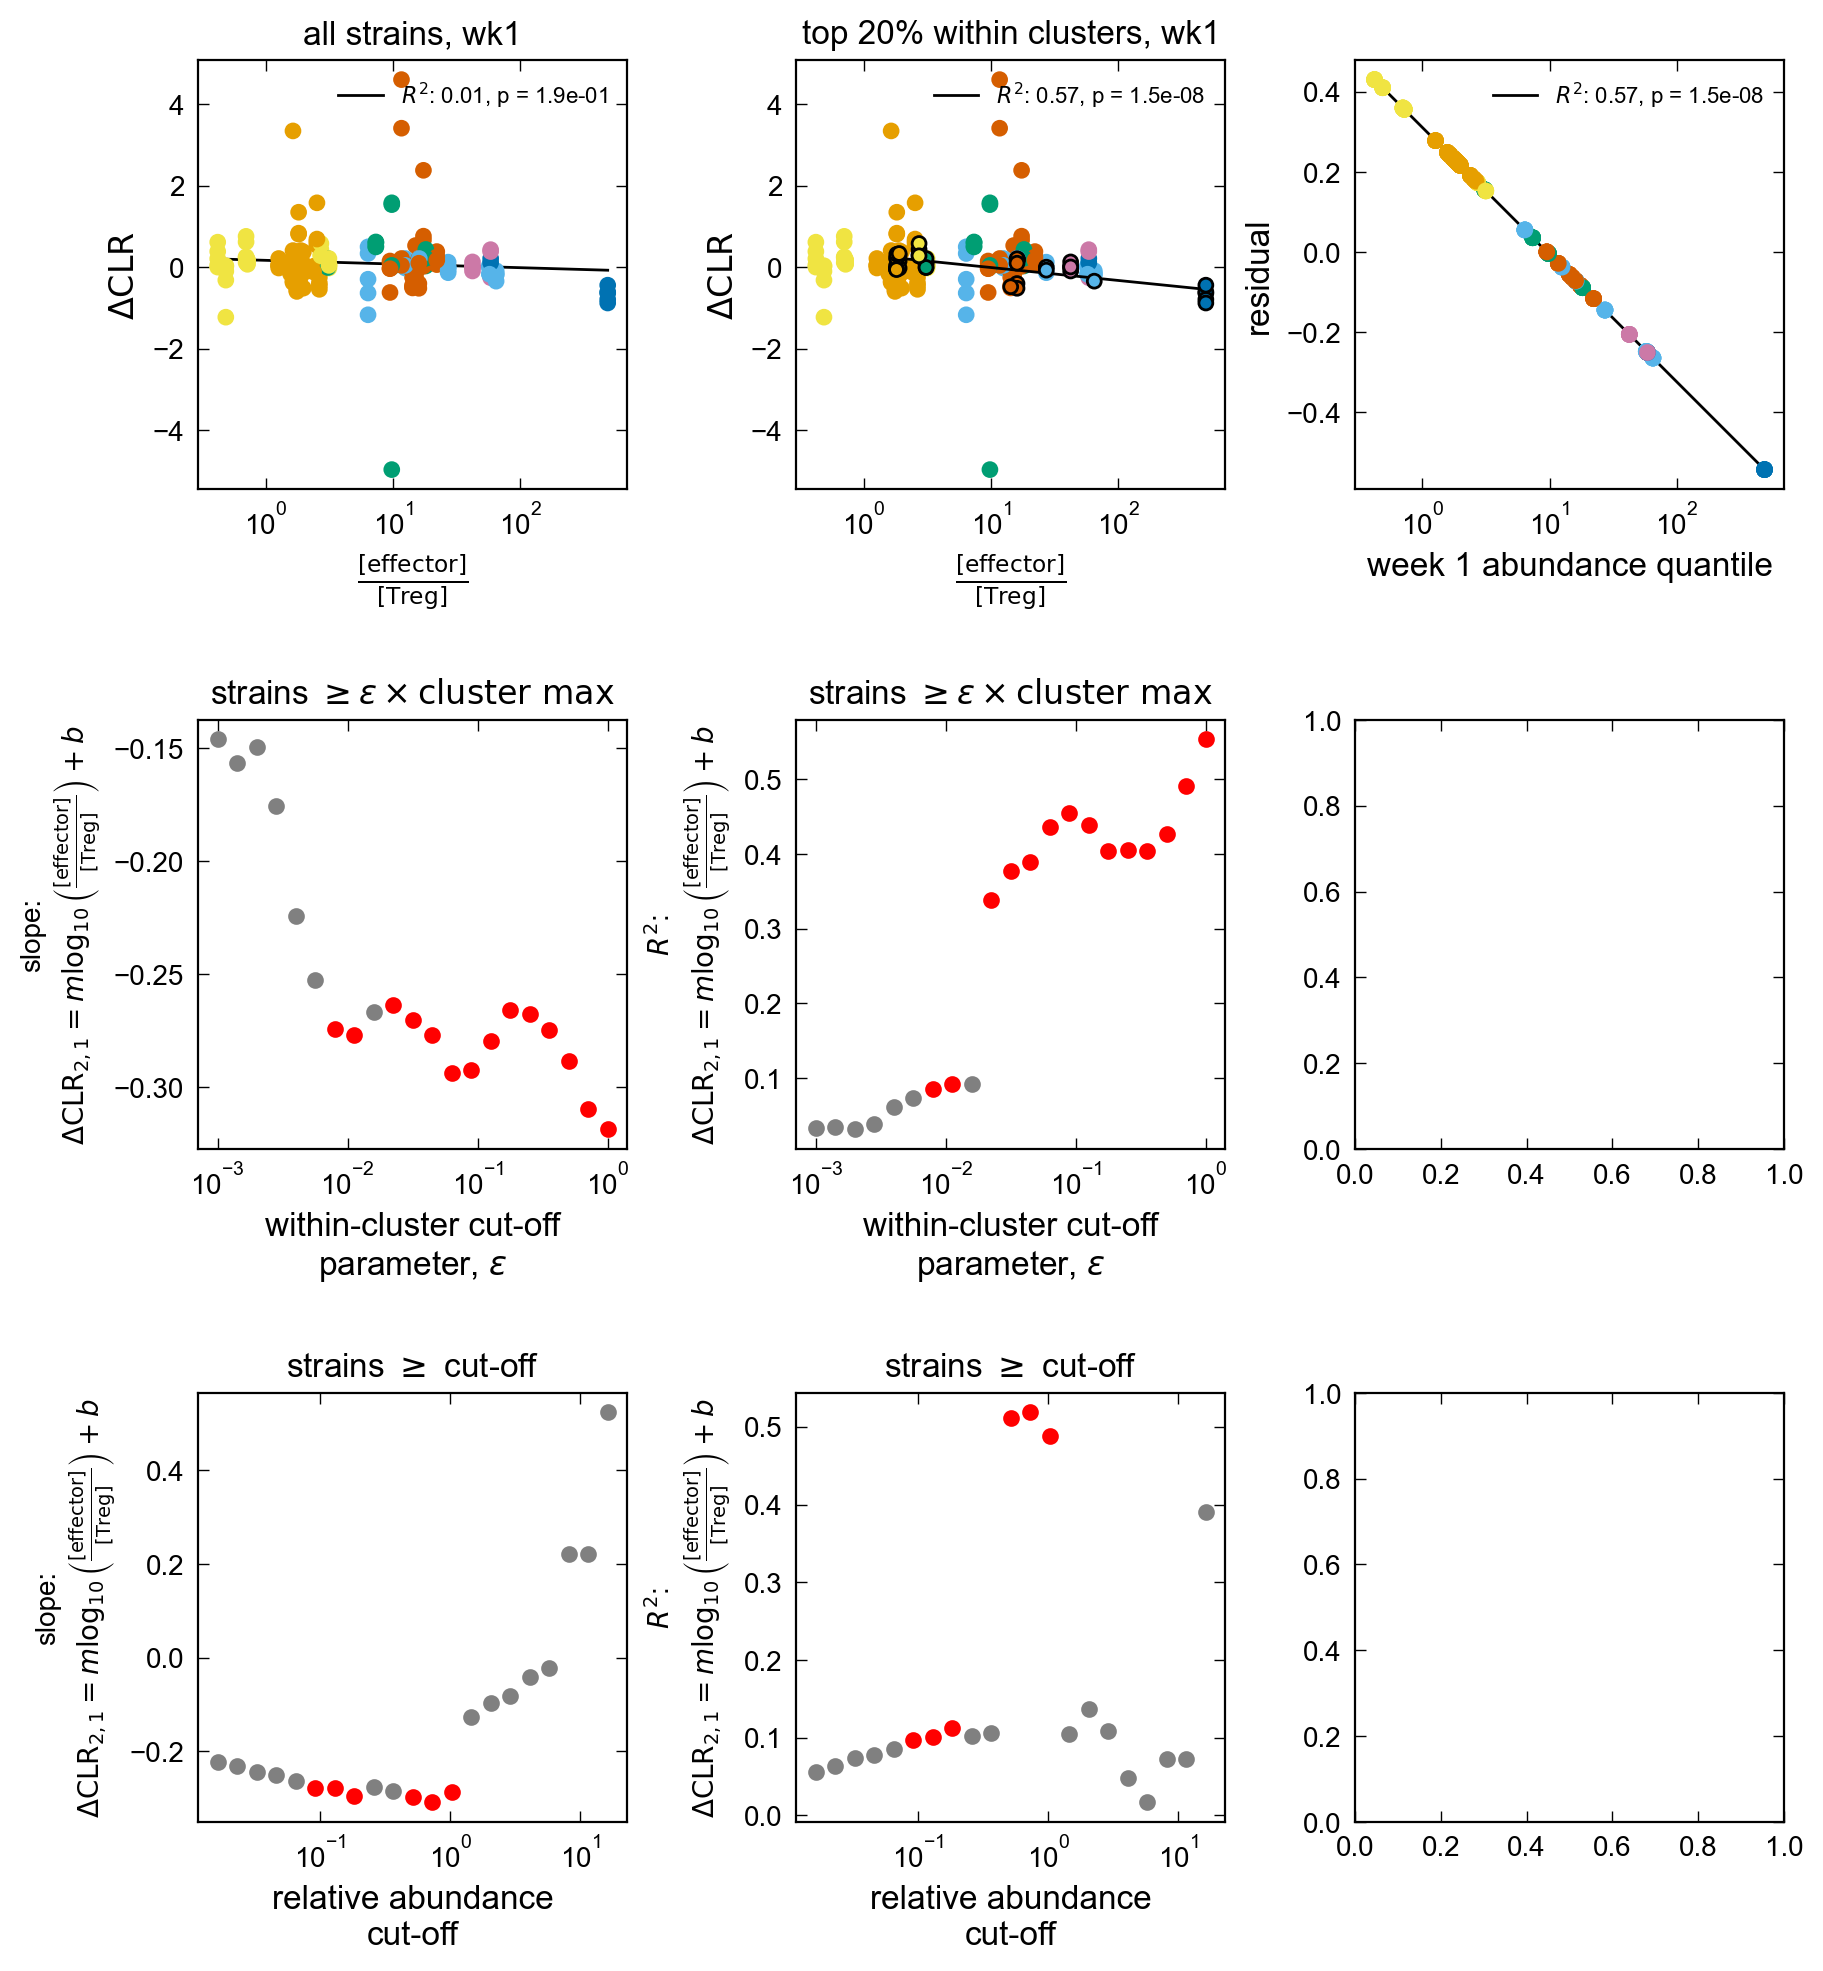

In [44]:
# Plot figures
fig, axs = plt.subplots(3, 3, figsize=(9, 10.0), sharex = False, constrained_layout=True)

hybridoma_abundance_fig_data = hybridoma_cluster_data[['replicate', 'strain_id','total_effector', 'total_Treg','mean_sigma']]
for_fig = strain_clr_data.loc[strain_clr_data.cross_reactivity_cluster != 0].merge(hybridoma_abundance_fig_data, 
                                                                                  how = 'left', on = ['strain_id', 'replicate'], validate = 'one_to_one').replace([np.inf, -np.inf, np.nan], 0)
for_fig.loc[:, 'eff_Treg_ratio'] = (for_fig['total_effector']/for_fig['total_Treg']).replace([np.inf, -np.inf], np.nan)
for_fig.loc[:, 'log_fc'] =  np.log10(for_fig['Batch1_week2']/for_fig['Batch1_week1'])
for_fig.loc[:, 'del_clr'] =  for_fig['wk2_clr'] - for_fig['wk1_clr']
for_fig.loc[:, 'cluster_quartile'] = for_fig.groupby(['cross_reactivity_cluster','replicate'])['wk1_clr'].transform(lambda x: pd.qcut(x, q=10, labels=False, duplicates='drop'))
for_fig.loc[:, 'strain_quartile'] = for_fig.groupby('replicate')['wk1_clr'].transform(lambda x: pd.qcut(x, q=10, labels=False, duplicates='drop'))
for_fig.loc[:, 'del_clr_variance'] = for_fig.groupby('strain_id')['del_clr'].transform(lambda x: np.std(x))
for_fig.loc[:, 'cluster_rank'] = for_fig.groupby(['cross_reactivity_cluster','replicate'])['wk1_clr'].rank(ascending=False)
for_fig.loc[:, 'cluster_max'] = for_fig.groupby(['cross_reactivity_cluster','replicate'])['Batch1_week1'].transform(lambda x: np.amax(x))

# Fig a: Effect of immunity is undetectable on the least abundant strains within each cluster
mask = for_fig['cluster_quartile'] >= 0
x_data = for_fig['eff_Treg_ratio']
y_data = for_fig['del_clr'] #.replace([np.inf, -np.inf, np.nan], 1)
axs[0,0].scatter(x_data[mask], y_data[mask], s = 25, color = for_fig['cross_reactivity_cluster'][mask].map(lut), zorder = 2)

m, b, r_value, p_value, std_err = scipy.stats.linregress(np.log10(x_data[mask]), y_data[mask])
axs[0,0].plot(np.unique(x_data[mask]), 
        m*np.unique(np.log10(x_data[mask])) + b, 
              color = 'black',
              zorder = 0,
              linewidth = 1.0,
        label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ f', p = {p_value:.1e}')

axs[0,0].set_title('all strains, wk1',  fontsize = 12)
axs[0,0].set_xlabel(r'$\frac{[\text{effector}]}{[\text{Treg}]}$', fontsize = 12)
axs[0,0].set_ylabel(r'$\Delta\text{CLR}$', fontsize = 12)
# axs[0,0].set_xlim(0.5,100)
axs[0,0].semilogx()
axs[0,0].legend(fontsize=8)

# Fig b: Effect of immunity is most evident on the most abundant strains within each cluster
mask = for_fig['cluster_quartile'] >= 9
x_data = for_fig['eff_Treg_ratio']
y_data = for_fig['del_clr'] #.replace([np.inf, -np.inf, np.nan], 1)
axs[0,1].scatter(x_data[mask], y_data[mask], 
                 s = 25, color = for_fig['cross_reactivity_cluster'][mask].map(lut), zorder = 2,
                edgecolors='black', linewidths=1)
axs[0,1].scatter(x_data[~mask], y_data[~mask], 
                 s = 25, color = for_fig['cross_reactivity_cluster'][~mask].map(lut), zorder = 0)

m, b, r_value, p_value, std_err = scipy.stats.linregress(np.log10(x_data[mask]), y_data[mask])
axs[0,1].plot(np.unique(x_data[mask]), 
        m*np.unique(np.log10(x_data[mask])) + b, 
              color = 'black',
              zorder = 0,
              linewidth = 1.0,
        label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ f', p = {p_value:.1e}')

axs[0,1].set_title('top 20% within clusters, wk1', fontsize = 12)
axs[0,1].set_xlabel(r'$\frac{[\text{effector}]}{[\text{Treg}]}$', fontsize = 12)
axs[0,1].set_ylabel(r'$\Delta\text{CLR}$', fontsize = 12)
# axs[0,1].set_xlim(0.5,100)
axs[0,1].semilogx()
axs[0,1].legend(fontsize=8)

# Fig c: Residuals as a function of rank
x_data = for_fig['eff_Treg_ratio']
y_data = m*np.log10(for_fig['eff_Treg_ratio']) + b
axs[0,2].scatter(x_data, y_data, s = 25, color = for_fig['cross_reactivity_cluster'].map(lut), zorder = 2)

axs[0,2].plot(np.unique(x_data), 
        m*np.unique(np.log10(x_data)) + b, 
              color = 'black',
              zorder = 0,
              linewidth = 1.0,
        label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ f', p = {p_value:.1e}')

# axs[0,2].set_title('top 20% within clusters, wk1', fontsize = 12)
axs[0,2].set_xlabel(r'week 1 abundance quantile', fontsize = 12)
axs[0,2].set_ylabel(r'residual', fontsize = 12)
axs[0,2].semilogx()
axs[0,2].legend(fontsize=8)

# Fig d-x: Additional support for the claim that immunity is most evident on the most abundant strains within each cluster
x_data = for_fig['eff_Treg_ratio']
y_data = for_fig['del_clr']
ks = np.logspace(-3,0,21)

axs[1,0].set_title(r'strains $\geq \epsilon\times\text{cluster max}$', fontsize = 12)
axs[1,0].set_xlabel('within-cluster cut-off\nparameter, '+r'$\epsilon$', fontsize = 12)
axs[1,0].set_ylabel('slope:\n'+ r'$\Delta\text{CLR}_{2,1} = m\log_{10}\left(\frac{[\text{effector}]}{[\text{Treg}]}\right) +b$', fontsize = 10)
axs[1,0].semilogx()

axs[1,1].set_title(r'strains $\geq \epsilon\times\text{cluster max}$', fontsize = 12)
axs[1,1].set_xlabel('within-cluster cut-off\nparameter, '+r'$\epsilon$', fontsize = 12)
axs[1,1].set_ylabel(r'$R^2$:'+'\n'+ r'$\Delta\text{CLR}_{2,1} = m\log_{10}\left(\frac{[\text{effector}]}{[\text{Treg}]}\right) +b$', fontsize = 10)
axs[1,1].semilogx()

for k in ks:
    mask = for_fig['cluster_max']*k <= for_fig['Batch1_week1']
    
    m, b, r_value, p_value, std_err = scipy.stats.linregress(np.log10(x_data[mask]), y_data[mask])
    axs[1,0].scatter(k, m,
                  color = 'red' if p_value <= 0.05/len(ks) else 'grey')

    axs[1,1].scatter(k, r_value**2,
                  color = 'red' if p_value <= 0.05/len(ks) else 'grey')

# Fig d: However, immunity is not detectable if we look at only the most abundant strains in the community
x_data = for_fig['eff_Treg_ratio']
y_data = for_fig['del_clr']
ks = np.logspace(-3,0,21)

axs[2,0].set_title(r'strains $\geq$ cut-off', fontsize = 12)
axs[2,0].set_xlabel('relative abundance\ncut-off', fontsize = 12)
axs[2,0].set_ylabel('slope:\n'+ r'$\Delta\text{CLR}_{2,1} = m\log_{10}\left(\frac{[\text{effector}]}{[\text{Treg}]}\right) +b$', fontsize = 10)
axs[2,0].semilogx()

axs[2,1].set_title(r'strains $\geq$ cut-off', fontsize = 12)
axs[2,1].set_xlabel('relative abundance\ncut-off', fontsize = 12)
axs[2,1].set_ylabel(r'$R^2$:'+'\n'+ r'$\Delta\text{CLR}_{2,1} = m\log_{10}\left(\frac{[\text{effector}]}{[\text{Treg}]}\right) +b$', fontsize = 10)
axs[2,1].semilogx()

for k in ks:
    mask = k*(np.amax(for_fig['Batch1_week1'])/2) <= for_fig['Batch1_week1']
    
    m, b, r_value, p_value, std_err = scipy.stats.linregress(np.log10(x_data[mask]), y_data[mask])
    axs[2,0].scatter(k*(np.amax(for_fig['Batch1_week1'])/2), m,
                  color = 'red' if p_value <= 0.05/len(ks) else 'grey')

    axs[2,1].scatter(k*(np.amax(for_fig['Batch1_week1'])/2), r_value**2,
                  color = 'red' if p_value <= 0.05/len(ks) else 'grey')

# Format figure
for ax in axs.flat:
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_most_abundant_delCLR_v_eff_Treg_ratio'+'.pdf', dpi=300, bbox_inches='tight')

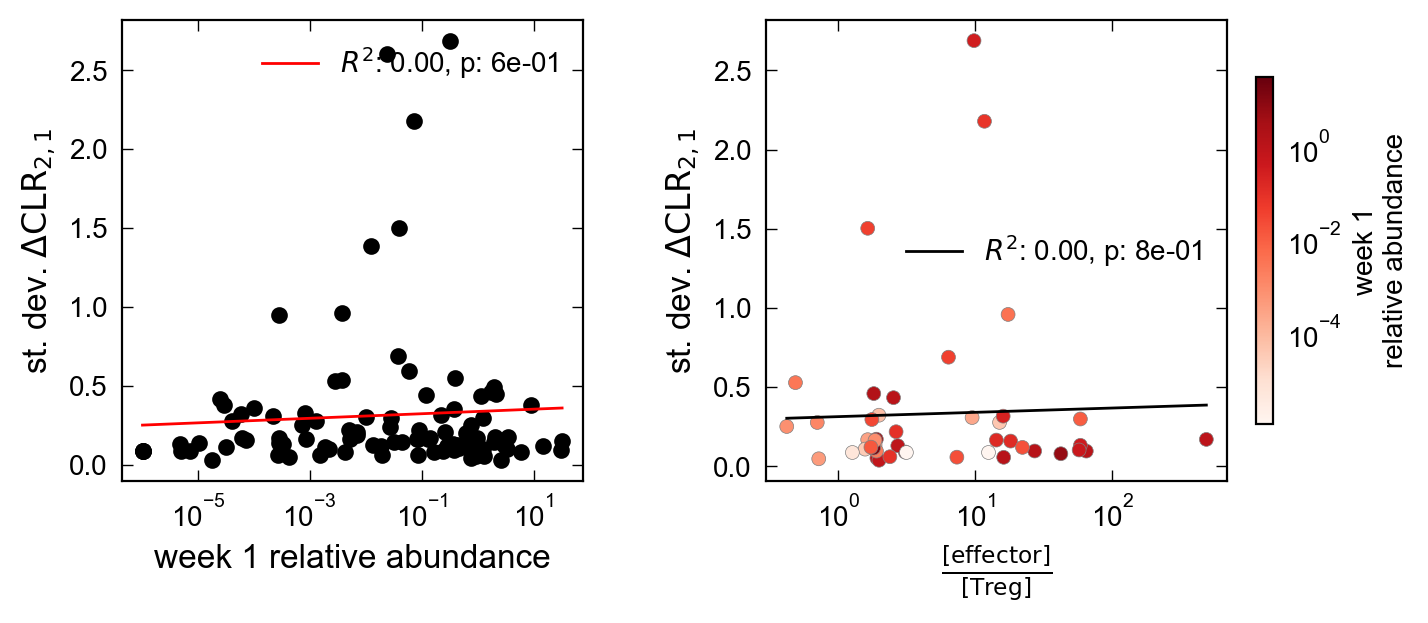

In [45]:
# Understand the structure of noise in the model
fig, axs = plt.subplots(1, 2, figsize=(7.0, 3.0), sharex = False, constrained_layout=True)

hybridoma_abundance_fig_data = hybridoma_cluster_data[['replicate', 'strain_id','total_effector', 'total_Treg', 'mean_sigma']]
data = strain_clr_data.merge(hybridoma_abundance_fig_data, how = 'left', on = ['strain_id', 'replicate'], validate = 'one_to_one')

var_list = ["Batch1_week1", "Batch1_week2", "Batch1_week3", "Batch1_week4"]
var_labels = ['week 1', 'week 2', 'week 3', 'week 4']
data.loc[:,'log_FC'] = np.log10(data.Batch1_week2/data.Batch1_week1)
data.loc[:, 'del_clr'] =  data['wk2_clr'] - data['wk1_clr']
data.loc[:, 'eff_Treg_ratio'] = (data['total_effector']/data['total_Treg']).replace([np.inf, -np.inf, np.nan], 0.0)
mean_data = data[['strain_id', 'cross_reactivity_cluster','del_clr', 'eff_Treg_ratio'] + var_list].groupby(['strain_id'], as_index = False).mean()
std_data = data[['strain_id', 'cross_reactivity_cluster','del_clr', 'eff_Treg_ratio'] + var_list].groupby(['strain_id'], as_index = False).std()

# fig a: plot variation as a function of abundance
y_data = std_data['del_clr']
x_data = mean_data['Batch1_week1']
axs[0].scatter(x_data, y_data, color = 'black')

m, b, r_value, p_value, std_err = scipy.stats.linregress(np.log10(x_data), y_data)
axs[0].plot(np.unique(x_data), m*np.unique(np.log10(x_data)) + b, color = 'red',
            label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ f', p: {p_value:.0e}')

axs[0].set_ylabel(r'st. dev. $\Delta\text{CLR}_{2,1}$', fontsize = 12)
axs[0].set_xlabel('week 1 relative abundance', fontsize = 12)

# fig b: plot variation as a function of immune pressure
y_data = std_data.loc[mean_data.cross_reactivity_cluster > 0]['del_clr']
x_data = mean_data.loc[mean_data.cross_reactivity_cluster > 0]['eff_Treg_ratio']
im = axs[1].scatter(x_data, y_data, 
               c = mean_data.loc[mean_data.cross_reactivity_cluster > 0]['Batch1_week1'],
               cmap = 'Reds', norm = mpl.colors.LogNorm(),
                   edgecolors = 'grey', linewidth = 0.25)

m, b, r_value, p_value, std_err = scipy.stats.linregress(np.log10(x_data), y_data)
axs[1].plot(np.unique(x_data), m*np.unique(np.log10(x_data)) + b, color = 'black',
            label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ f', p: {p_value:.0e}')

axs[1].set_ylabel(r'st. dev. $\Delta\text{CLR}_{2,1}$', fontsize = 12)
axs[1].set_xlabel(r'$\frac{[\text{effector}]}{[\text{Treg}]}$', fontsize = 12)
cb = fig.colorbar(im, ax=axs[1], location='right', shrink = 0.75, pad = 0.05)
cb.set_label('week 1\nrelative abundance', fontsize = 10)
cb.ax.tick_params(labelsize=10)

for ax in axs.flat:
    ax.legend()
    # ax.semilogy()
    ax.semilogx()
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)
    # ax.locator_params(axis='x', nbins=5)

fig.savefig('_figs/fig_variation_in_CLR_replicates'+'.pdf', dpi=300, bbox_inches='tight')

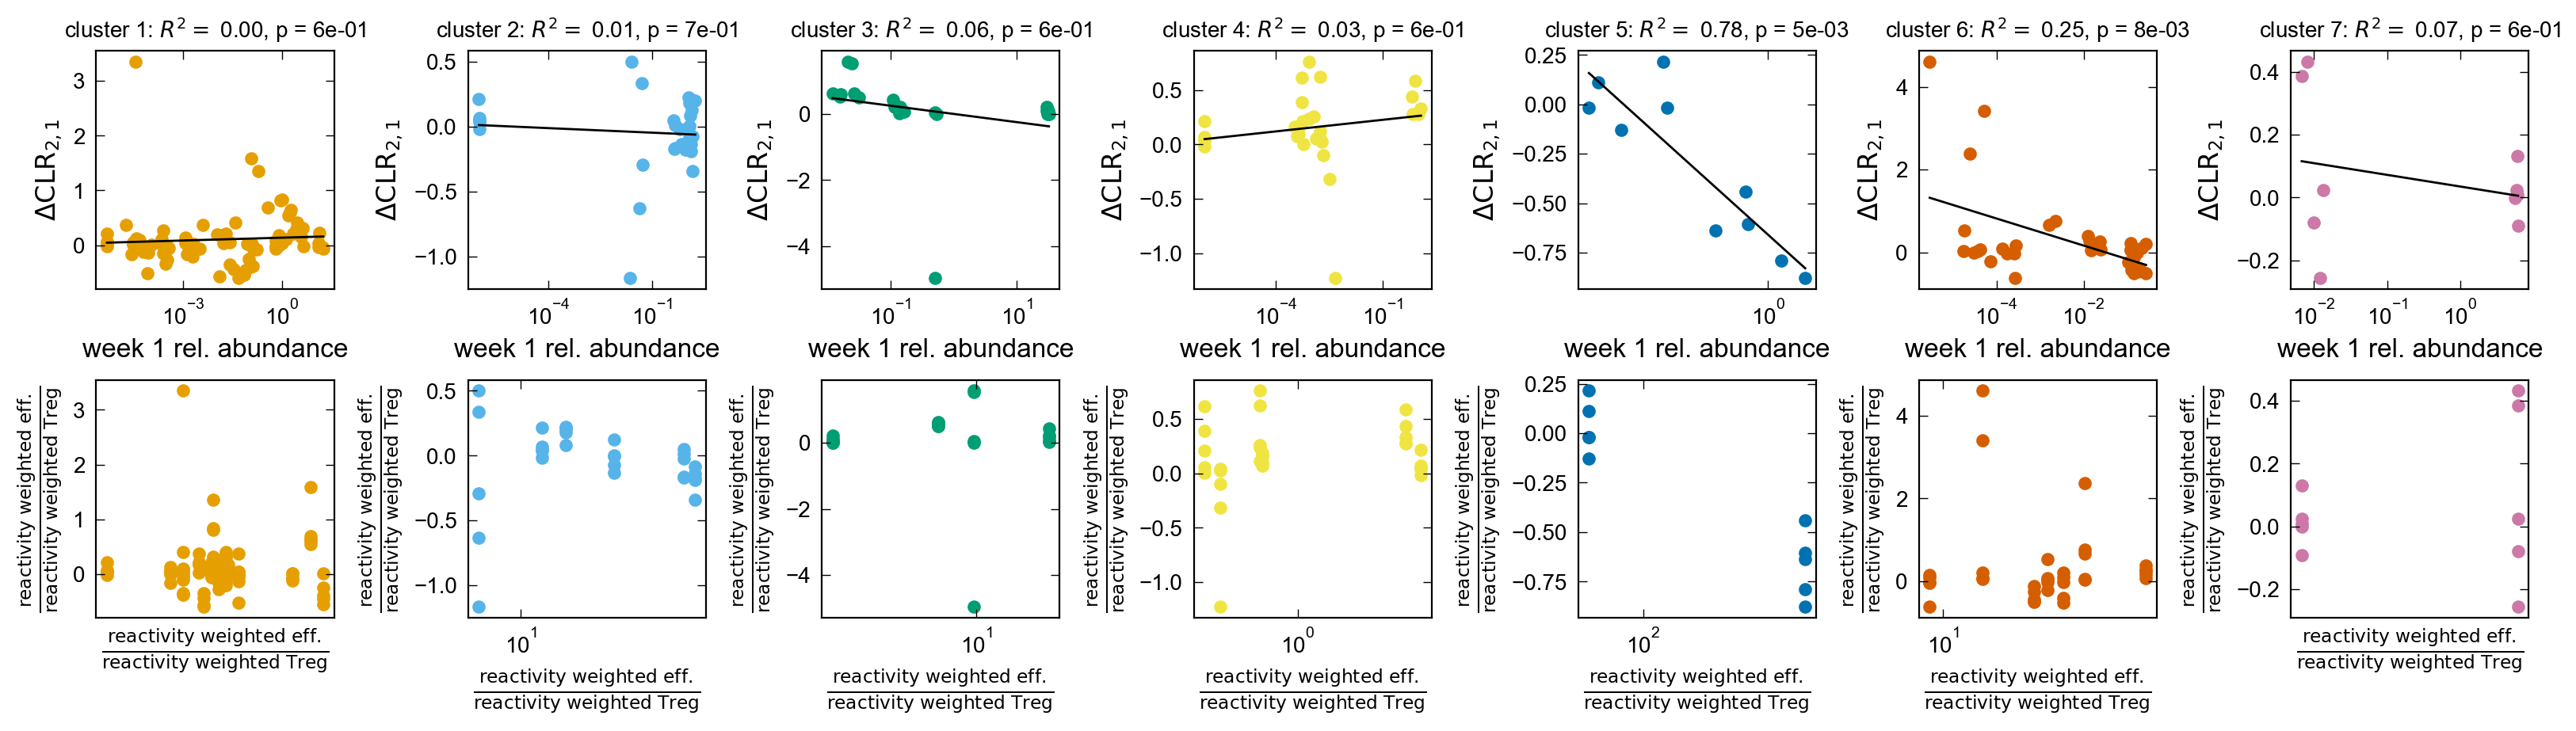

In [46]:
# Plot figures
plot_variables = ['GF_Th17_Average', 'hCom1d_Th17_Average']
cluster_variable= 'cross_reactivity_cluster'

fig, axs = plt.subplots(2, 7, figsize=(16, 4.5), sharex = False, constrained_layout=True)

hybridoma_abundance_fig_data = hybridoma_cluster_data[['replicate', 'strain_id','total_effector', 'total_Treg', 'mean_sigma']]
data = strain_clr_data.loc[strain_clr_data.cross_reactivity_cluster != 0].merge(hybridoma_abundance_fig_data,
                                                                                how = 'left', on = ['strain_id', 'replicate'], validate = 'one_to_one')

data.loc[:, 'log_fc'] =  np.log10(data['Batch1_week2']/data['Batch1_week1'])
data.loc[:, 'del_clr'] =  data['wk2_clr'] - data['wk1_clr']
data.loc[:, 'eff_Treg_ratio'] = (data['total_effector']/data['total_Treg']).replace([np.inf, -np.inf], np.nan)
data.loc[:, 'cluster_quartile'] = data.groupby(['cross_reactivity_cluster','replicate'])['wk1_clr'].transform(lambda x: pd.qcut(x, q=10, labels=False, duplicates='drop'))
data.loc[:, 'cluster_max'] = data.groupby(['cross_reactivity_cluster','replicate'])['Batch1_week1'].transform(lambda x: np.amax(x))

y_var_list = ['del_clr', 'del_clr']
x_var_list = ['Batch1_week1', 'eff_Treg_ratio']
ps = []
rs = []
for (_, g) in data.groupby('cross_reactivity_cluster'):
    cluster = g['cross_reactivity_cluster'].values[0]
    for i, var in enumerate(y_var_list):
        x_data, max_x = g[x_var_list[i]], np.amin(g['cluster_max'])
        y_data = g[y_var_list[i]]
    
        axs[i,int(cluster - 1)].scatter(x_data , y_data, s = 25, color = lut[cluster], zorder = 0) #, label = f'$R^2$: {}')
        #axs[i,int(cluster - 1)].axvline(x = max_x*0.01, ls = ':', color = 'grey')
        if i == 0:
            mask = g['cluster_max'] > 0 #*0.000001 <= g['Batch1_week1']
            m, b, r_value, p_value, std_err = scipy.stats.linregress(np.log10(x_data[mask]), y_data[mask])
            axs[i,int(cluster - 1)].plot(np.unique(x_data[mask]),
                    m*np.unique(np.log10(x_data[mask])) + b,
                          color = 'black',
                          zorder = 0,
                          linewidth = 1.0)
            ps.append(p_value)
            rs.append(r_value)

        axs[i,int(cluster - 1)].set_ylabel([r'$\Delta\text{CLR}_{2,1}$', r'$\frac{\text{reactivity weighted eff.}}{\text{reactivity weighted Treg}}$'][i], fontsize = 12)
        axs[i,int(cluster - 1)].set_xlabel([r'week 1 rel. abundance', r'$\frac{\text{reactivity weighted eff.}}{\text{reactivity weighted Treg}}$'][i], fontsize = 12)

    # axs[0,int(cluster - 1)].legend(fontsize=8, framealpha=0)

adj_ps = stats.false_discovery_control(ps)
r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ f', p = {p_value:.0e}'

# Format figure
for j, ax in enumerate(axs.flat):
    if j < 7:
        ax.set_title('cluster '+str(j + 1)+r': $R^2=$ ' + str("{:.2f}".format(rs[j]**2))+ f', p = {adj_ps[j]:.0e}', fontsize = 10)
    ax.semilogx()
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_within_cluster_rel_abundance_v_FC'+'.pdf', dpi=300, bbox_inches='tight')

In [47]:
# color the points in these plots by strain and not by cluster

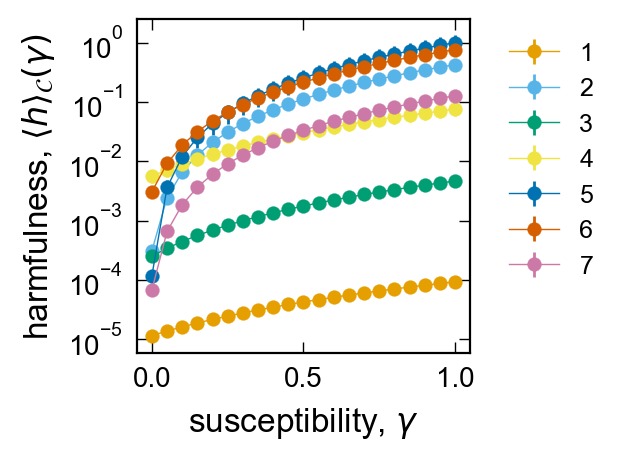

In [48]:
# Plot figures
plot_variables = ['GF_Th17_Average', 'hCom1d_Th17_Average']
cluster_variable= 'cross_reactivity_cluster'

fig, axs = plt.subplots(1, 1, figsize=(3.0, 3.0), sharex = False, constrained_layout=True)

hybridoma_abundance_fig_data = hybridoma_cluster_data[['replicate', 'cross_reactivity_cluster','weighted_total_effector', 'weighted_total_Treg', 'weighted_mean_sigma']].groupby(['cross_reactivity_cluster', 'replicate'], as_index = False).mean()

# plot figure (b)
data = cluster_clr_data.loc[cluster_clr_data.cross_reactivity_cluster != 0].merge(hybridoma_abundance_fig_data, how = 'left', on = ['cross_reactivity_cluster', 'replicate'], validate = 'one_to_one')
data.loc[:, 'log_fc'] =  np.log10(data['Batch1_week2']/data['Batch1_week1'])
data.loc[:, 'del_clr'] =  data['wk2_clr'] - data['wk1_clr']
data.loc[:, 'eff_Treg_ratio'] = (data['weighted_total_effector']/data['weighted_total_Treg']).replace([np.inf, -np.inf, np.nan], 0)
# data.loc[:, 'est_h'] = -2*(data['del_clr'] - data['del_clr'][0]).values - np.log10(data['mean_sigma']/data['mean_sigma'][0]).values - (data['peak_clr'] - data['peak_clr'][0]).values

alphas = np.linspace(0, 1, 21)
h_data, a_data, h_data_err = [], [], []
clusters = np.unique(data.cross_reactivity_cluster)
for a in alphas:
    data.loc[:, 'est_h'] = ((1 + a*data['eff_Treg_ratio'])**2/(data['weighted_mean_sigma']*data['Batch1_week1'])).values

    # plot figure (c)
    mean_data, std_data = data.drop('replicate', axis = 1).groupby('cross_reactivity_cluster', as_index = False).mean(), data.drop('replicate', axis = 1).groupby('cross_reactivity_cluster', as_index = False).std()
    h_data.append(mean_data['est_h'].values)
    a_data.append(a*np.ones(len(mean_data)))
    h_data_err.append(std_data['est_h'].values)

y_data = np.vstack(h_data)/np.amax(np.vstack(h_data))#/np.vstack(h_data).max(axis=1, keepdims=True)
x_data = np.vstack(a_data)
yerr = np.vstack(h_data_err)/np.amax(np.vstack(h_data))

for c in clusters:
    axs.errorbar(x_data[:,int(c - 1)], y_data[:,int(c - 1)], yerr = yerr[:,int(c - 1)],
                    elinewidth = 1.0,linewidth = 0.5,fmt = '-o', color = lut[int(c)], label = str(int(c)))

# Format figure
axs.set_xlabel(r'susceptibility, $\gamma$', fontsize = 12)
axs.set_ylabel(r'harmfulness, $\langle h\rangle_\mathcal{C}(\gamma)$', fontsize = 12)
axs.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
axs.semilogy()
    
axs.set_box_aspect(1)
axs.minorticks_off()
axs.tick_params(axis='both', which='major', labelsize=10)
axs.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_estimated_harm_by_cluster'+'.pdf', dpi=300, bbox_inches='tight')

Note that cluster 4 only has regulatory T-cell coverage present.

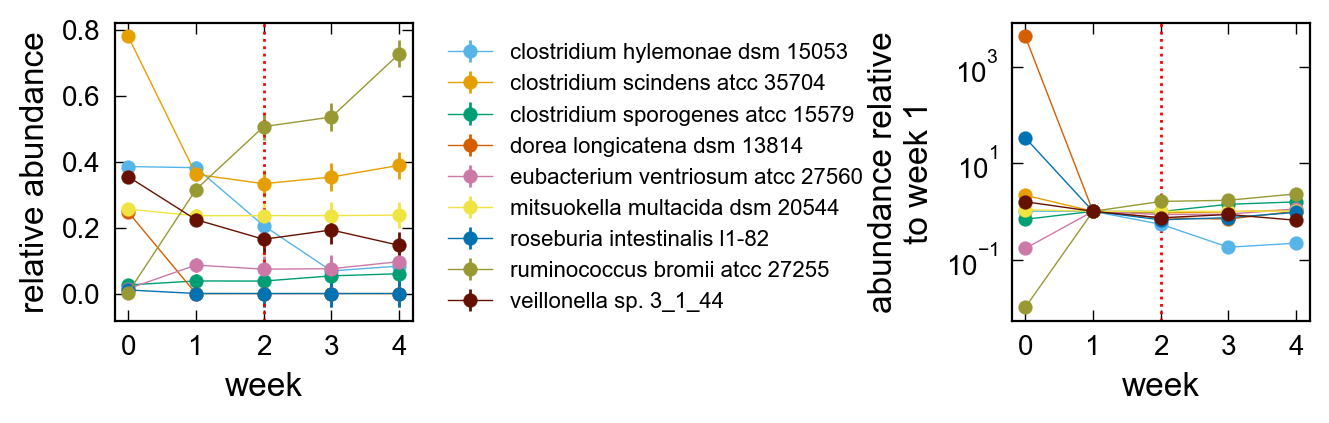

In [49]:
strains_of_interest = ['eubacterium ventriosum atcc 27560', 
                       'clostridium scindens atcc 35704',
                       # 'ruminococcus albus 8',
                       'ruminococcus bromii atcc 27255', # missing ruminococus obeum
                       # 'ruminococcus gnavus atcc 29149',
                       # 'ruminococcus lactaris atcc 29176',
                       # 'ruminococcus torques atcc 27756',
                       'mitsuokella multacida dsm 20544',
                       'clostridium hylemonae dsm 15053',
                       'roseburia intestinalis l1-82',
                       'dorea longicatena dsm 13814',
                       'clostridium sporogenes atcc 15579',
                       'veillonella sp. 3_1_44',
                       # 'veillonella sp. 6_1_27'
                      ]

data = strain_clr_data.loc[strain_clr_data.strain_id.isin(strains_of_interest)].drop('replicate',axis = 1).groupby('strain_id', as_index = False).mean()

fig, axs = plt.subplots(1, 2, figsize=(6.5, 2.0), sharex = False, constrained_layout=True)

clr_var_list = ["day0_clr", "wk1_clr", "wk2_clr", "wk3_clr", "wk4_clr"]
abundance_var_list = ["day0_abundance_batch1", "Batch1_week1", "Batch1_week2", "Batch1_week3", "Batch1_week4"]

for i, (_, g) in enumerate(data.groupby('strain_id')):
    strain = g.strain_id.item()
    axs[0].errorbar(np.arange(0,5), g[abundance_var_list].values.ravel(), 
                    yerr = error.ravel(), elinewidth = 1.0,linewidth = 0.5,fmt = '-o', label = strain)
    axs[0].set_ylabel('relative abundance', fontsize = 12)
    axs[0].legend(bbox_to_anchor=(1.05, 1.0), fontsize=8, framealpha=0)
    # axs[0].semilogy()

    axs[1].errorbar(np.arange(0,5), g[abundance_var_list].values.ravel()/g[abundance_var_list].values.ravel()[1], 
                    elinewidth = 1.0,linewidth = 0.5,fmt = '-o', label = strain)
    axs[1].set_ylabel('abundance relative\nto week 1', fontsize = 12)
    axs[1].semilogy()

for j, ax in enumerate(axs.flat):
    ax.set_xlabel('week', fontsize = 12)
    ax.axvline(x = 2, ls = ':', color = 'red')
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)
    ax.set_xticks(np.arange(0,5))

# fig.savefig('_figs/fig_rel_abundance_by_cluster_average'+'.pdf', dpi=300, bbox_inches='tight')

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33658/1025044771.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.loc[:,'fc10'] = np.log10(data.Batch1_week1/data.day0_abundance_batch1)
/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33658/1025044771.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.loc[:,'fc21'] = np.log10(data.Batch1_week2/data.Batch1_week1)
/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_33658/1025044771.py:22: SettingWithCopyWarning: 
A v

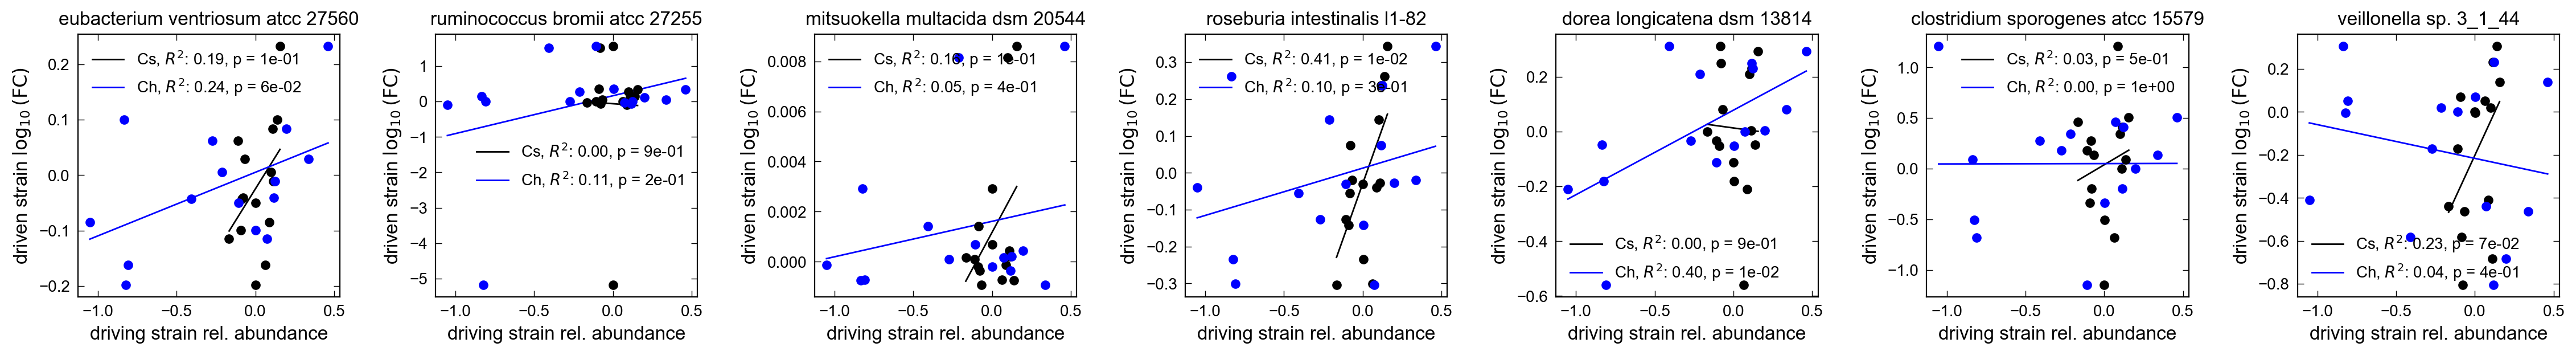

In [50]:
# Can we recover signatures of the ecological interaction network in Wang et al (2023) by doing regressions?
driven_strains = ['eubacterium ventriosum atcc 27560', 
                       # 'ruminococcus albus 8',
                       'ruminococcus bromii atcc 27255', # missing ruminococus obeum
                       # 'ruminococcus gnavus atcc 29149',
                       # 'ruminococcus lactaris atcc 29176',
                       # 'ruminococcus torques atcc 27756',
                       'mitsuokella multacida dsm 20544',
                       'roseburia intestinalis l1-82',
                       'dorea longicatena dsm 13814',
                       'clostridium sporogenes atcc 15579',
                       'veillonella sp. 3_1_44',
                       # 'veillonella sp. 6_1_27'
                      ]

driving_strains = ['clostridium scindens atcc 35704', 'clostridium hylemonae dsm 15053']
"day0_abundance_batch1", "Batch1_week1", "Batch1_week2", "Batch1_week3"

data = strain_clr_data.loc[strain_clr_data.strain_id.isin(strains_of_interest)]
data.loc[:,'fc10'] = np.log10(data.Batch1_week1/data.day0_abundance_batch1)
data.loc[:,'fc21'] = np.log10(data.Batch1_week2/data.Batch1_week1)
data.loc[:,'fc32'] = np.log10(data.Batch1_week3/data.Batch1_week2)
data.loc[:,'fc43'] = np.log10(data.Batch1_week4/data.Batch1_week3)

x_vars = ['fc21', 'fc32', 'fc43'] #["Batch1_week1", "Batch1_week2", "Batch1_week3"]
cs_data = np.hstack(data.loc[ data.strain_id == driving_strains[0]][x_vars].values)
ch_data = np.hstack(data.loc[ data.strain_id == driving_strains[1]][x_vars].values)

fc_vars = ['fc21', 'fc32', 'fc43']

fig, axs = plt.subplots(1, len(driven_strains), figsize=(3.25*len(driven_strains), 3.0), sharex = False, constrained_layout=True)

for i, strain in enumerate(driven_strains):
    y_data = np.hstack(data.loc[data.strain_id == strain][fc_vars].values)
    axs[i].scatter(cs_data, y_data,color = 'black')
    m, b, r_value, p_value, std_err = scipy.stats.linregress(cs_data, y_data)
    axs[i].plot(np.unique(cs_data), 
            m*np.unique(cs_data) + b, 
                  color = 'black',
                  zorder = 0,
                  linewidth = 1.0,
            label = r'Cs, $R^2$: ' + str("{:.2f}".format(r_value**2))+ f', p = {p_value:.0e}')
        
    axs[i].scatter(ch_data, y_data, color = 'blue')
    m, b, r_value, p_value, std_err = scipy.stats.linregress(ch_data, y_data)
    axs[i].plot(np.unique(ch_data), 
            m*np.unique(ch_data) + b, 
                  color = 'blue',
                  zorder = 0,
                  linewidth = 1.0,
            label = r'Ch, $R^2$: ' + str("{:.2f}".format(r_value**2))+ f', p = {p_value:.0e}')
    
    axs[i].legend()
    axs[i].set_ylabel(r'driven strain $\log_{10}(\text{FC})$', fontsize = 12)
    axs[i].set_xlabel(r'driving strain rel. abundance', fontsize = 12)
    axs[i].set_title(strain, fontsize = 12)
    axs[i].set_box_aspect(1)
    axs[i].minorticks_off()
    axs[i].tick_params(axis='both', which='major', labelsize=10)
    axs[i].xaxis.set_tick_params(labeltop=False)
    

In [51]:
data
# Ch is in the non-reactive cluster which means we don't have good reactivity data for it. Put this analysis on hold

,index,cross_reactivity_cluster,replicate,day0_abundance_batch1,Batch1_week1,Batch1_week2,Batch1_week3,Batch1_week4,day0_abundance_batch2,day0_abundance_batch3,...,wk1_clr,wk2_clr,wk3_clr,wk4_clr,peak_1_2_clr,peak_clr,fc10,fc21,fc32,fc43
45,49,0.0,m1,0.385209,0.318051,0.375714,0.054975,0.086809,0.202062,0.925628,...,1.386393,1.497583,0.652661,0.798001,1.497583,1.497583,-0.083200,0.072360,-0.834695,0.198403
49,53,5.0,m1,0.779442,0.333325,0.227149,0.312294,0.403212,1.012801,1.154555,...,1.406764,1.279038,1.407062,1.464968,1.406764,1.464968,-0.368916,-0.166556,0.138251,0.110970
53,57,2.0,m1,0.026241,0.024857,0.072066,0.088272,0.087878,0.067195,0.503303,...,0.279337,0.780459,0.858319,0.803316,0.780459,0.858319,-0.023540,0.462292,0.088088,-0.001940
60,64,1.0,m1,0.247271,0.000051,0.000051,0.000045,0.000046,0.978767,1.463283,...,-2.411636,-2.372632,-2.431029,-2.480874,-2.372632,-2.372632,-3.688705,0.000174,-0.048169,0.003218
67,71,1.0,m1,0.014682,0.136995,0.105055,0.132290,0.160184,0.120229,0.521287,...,1.020601,0.944145,1.034026,1.064055,1.020601,1.064055,0.969932,-0.115286,0.100109,0.083092
74,78,0.0,m1,0.255960,0.236701,0.236796,0.236391,0.236632,0.325941,0.309858,...,1.258097,1.297101,1.286129,1.233508,1.297101,1.297101,-0.033971,0.000174,-0.000744,0.000443
83,87,0.0,m1,0.011091,0.000298,0.000148,0.000270,0.000254,0.030589,0.416161,...,-1.642085,-1.907117,-1.656495,-1.736375,-1.642085,-1.642085,-1.570934,-0.303862,0.260849,-0.026816
86,90,3.0,m1,0.003199,0.538947,0.496669,0.703073,0.910743,0.006056,0.004390,...,1.615443,1.618793,1.759499,1.818831,1.618793,1.818831,2.226577,-0.035479,0.150934,0.112395
96,100,6.0,m1,0.354381,0.194747,0.070988,0.143329,0.029636,0.172050,0.027603,...,1.173367,0.773913,1.068831,0.331252,1.173367,1.173367,-0.260000,-0.438284,0.305146,-0.684515
143,146,0.0,m2,0.385209,0.106961,0.041746,0.090890,0.118857,0.202062,0.925628,...,0.910500,0.567173,0.864073,0.966751,0.910500,0.966751,-0.556469,-0.408608,0.337896,0.116509


What can I do with this ecological data? Could I try to fit to an ecological model?
Write and ODE simulation and fit to data?
(1) write down the ODE model, i.e. a function that maps parameters to derivatives: max abundance, ecological interactions and immune interactions
(2) define a fitting function that takes parameters and solves the ode model over the time
(3) fit results of ODE to data